# 3. Unsupervised Machine Learning — User segmentation
# 3. Unüberwachtes Machine Learning — Nutzersegmentierung

## Purpose
## Ziel

Identify users with similar recorded booking behaviour.
Interpret the resulting groups before recommending customer benefits.

This notebook follows the supplied Unsupervised Learning materials.
Each relevant step is explained and, where useful, visualised.
Steps that are not required are explicitly identified and justified.

Nutzer mit ähnlichem erfasstem Buchungsverhalten identifizieren.
Die entstandenen Gruppen zunächst interpretieren und anschließend
passende Kundenvorteile empfehlen.

Dieses Notebook orientiert sich an den bereitgestellten Unterlagen
zum unüberwachten Lernen. Jeder relevante Schritt wird erklärt und,
wo sinnvoll, visualisiert. Nicht benötigte Schritte werden ausdrücklich
benannt und begründet.

## Data basis
## Datengrundlage

- 5,542 users with recorded trips.
- 14 preliminary numerical feature candidates.
- Missing values have not yet been replaced.
- Features have not yet been scaled.

The 456 users without recorded trips remain in their separate
rule-based group and are excluded from ML preprocessing and clustering.

- 5.542 Nutzer mit erfassten Reisen.
- 14 vorläufige numerische Merkmalskandidaten.
- Fehlende Werte wurden noch nicht ersetzt.
- Die Merkmale wurden noch nicht skaliert.

Die 456 Nutzer ohne erfasste Reisen bleiben in ihrer separaten
regelbasierten Gruppe. Sie werden nicht in die ML-Vorverarbeitung
oder das Clustering einbezogen.

## Workflow
## Ablauf

1. Load and validate the data.
2. Prepare the features: missing values, feature review and scaling.
3. Compare K-Means configurations and DBSCAN.
4. Investigate PCA and repeat clustering for comparison.
5. Interpret groups, recommend benefits and save the results.

<!-- -->

1. Daten laden und prüfen.
2. Merkmale vorbereiten: fehlende Werte, Merkmalsprüfung und Skalierung.
3. Verschiedene K-Means-Einstellungen und DBSCAN vergleichen.
4. PCA untersuchen und das Clustering zum Vergleich wiederholen.
5. Gruppen interpretieren, Kundenvorteile empfehlen und Ergebnisse speichern.


In [1]:
# packages for data preparation and visualisation
# pakete für datenaufbereitung und visualisierung
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import HTML, display

# preprocessing and model tools
# werkzeuge für vorverarbeitung und modelle
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    RobustScaler,
)
from sklearn.pipeline import Pipeline

from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA

# install the dependency in the active notebook environment
%pip install "nbformat>=4.2"

# evaluation tools
# werkzeuge zur bewertung
from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    adjusted_rand_score,
)

# locate the project folder
# projektordner bestimmen
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

if not (project_root / "src").is_dir():
    raise FileNotFoundError(
        "Project folder not found. Check the notebook working directory."
    )

project_path = str(project_root.resolve())

if project_path not in sys.path:
    sys.path.insert(0, project_path)

# reuse the shared table and chart styling
# gemeinsame tabellen- und diagrammgestaltung wiederverwenden
from src.plotting_style import (
    COLORS,
    PALETTE,
    GENDER_COLORS,
    style_overview,
    apply_plot_style,
)

apply_plot_style()

print("Project folder:", project_root)
print("Python environment:", sys.executable)

Note: you may need to restart the kernel to use updated packages.
Project folder: c:\Users\mpero\Desktop\GitHub\TravelTide
Python environment: c:\Users\mpero\Desktop\GitHub\TravelTide\.venv\Scripts\python.exe



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 3.1 Load and validate the data
## 3.1 Daten laden und prüfen

Load the complete user table, the unscaled ML candidates and
the preliminary group assignments.

Verify that the ML table contains exactly the users with recorded
trips. The separate rule-based group remains excluded.
No missing values are replaced at this stage.

Die vollständige Nutzertabelle, die unskalierten ML-Kandidaten
und die vorläufigen Gruppenzuordnungen laden.

Prüfen, ob die ML-Tabelle genau die Nutzer mit erfassten Reisen
enthält. Die separate regelbasierte Gruppe bleibt ausgeschlossen.
Fehlende Werte werden in diesem Schritt nicht ersetzt.

In [2]:
# load the saved feature-engineering results
# gespeicherte ergebnisse der merkmalsentwicklung laden
processed_path = project_root / "data" / "processed"

user_features = pd.read_csv(
    processed_path / "user_features.csv",
    dtype={"user_id": "int64"},
)

ml_candidates = pd.read_csv(
    processed_path / "ml_feature_candidates.csv",
    dtype={"user_id": "int64"},
).set_index("user_id")

segmentation_assignments = pd.read_csv(
    processed_path / "segmentation_assignments_draft.csv",
    dtype={
        "user_id": "int64",
        "group": "string",
        "assignment_method": "string",
        "recommended_perk": "string",
    },
)

# restore dates in the complete user table
# datumswerte in der vollständigen nutzertabelle wiederherstellen
for column in ["birthdate", "sign_up_date"]:
    user_features[column] = pd.to_datetime(
        user_features[column],
        format="%Y-%m-%d",
        errors="raise",
    )

# identify the expected populations
# erwartete nutzergruppen bestimmen
all_user_ids = set(user_features["user_id"])

expected_ml_ids = set(
    user_features.loc[
        user_features["trip_count"].gt(0),
        "user_id",
    ]
)

expected_rule_ids = set(
    user_features.loc[
        user_features["trip_count"].eq(0),
        "user_id",
    ]
)

recorded_rule_ids = set(
    segmentation_assignments.loc[
        segmentation_assignments["assignment_method"].eq("Rule-based"),
        "user_id",
    ]
)

# validate IDs, population coverage and numeric model features
# IDs, nutzerabdeckung und numerische modellmerkmale prüfen
if (
    user_features["user_id"].duplicated().any()
    or segmentation_assignments["user_id"].duplicated().any()
    or not ml_candidates.index.is_unique
    or set(segmentation_assignments["user_id"]) != all_user_ids
    or set(ml_candidates.index) != expected_ml_ids
    or recorded_rule_ids != expected_rule_ids
    or expected_ml_ids & expected_rule_ids
    or expected_ml_ids | expected_rule_ids != all_user_ids
    or ml_candidates.shape[1] != 14
    or not ml_candidates.select_dtypes(
        exclude="number"
    ).empty
    or np.isinf(ml_candidates.to_numpy(dtype=float)).any()
):
    raise ValueError("Check the loaded tables and user assignments.")

loaded_overview = pd.DataFrame({
    "Table": [
        "Complete user table",
        "ML candidate features",
        "Preliminary group assignments",
    ],
    "Users": [
        len(user_features),
        len(ml_candidates),
        len(segmentation_assignments),
    ],
    "Data columns": [
        user_features.shape[1],
        ml_candidates.shape[1],
        segmentation_assignments.shape[1],
    ],
})

display(style_overview(
    loaded_overview,
    "Clustering — Loaded tables",
    {
        "Users": "{:,.0f}",
        "Data columns": "{:,.0f}",
    },
))

print("Users in the separate rule-based group:", len(expected_rule_ids))
print("Data-loading checks passed.")

Table,Users,Data columns
Complete user table,"5,998",50
ML candidate features,"5,542",14
Preliminary group assignments,"5,998",4


Users in the separate rule-based group: 456
Data-loading checks passed.


In [3]:
# preview the first ten users and all candidate features
# die ersten zehn nutzer mit allen merkmalskandidaten anzeigen
display(HTML(
    '<div style="overflow-x:auto;">'
    + style_overview(
        ml_candidates.head(10).reset_index(),
        "ML candidates — First ten users",
        {
            "user_id": "{:.0f}",
            **{
                column: "{:,.2f}"
                for column in ml_candidates.columns
            },
        },
    ).to_html()
    + "</div>"
))

user_id,trip_count,cancelled_trip_share_pct,flight_only_trip_share_pct,hotel_only_trip_share_pct,flight_discount_booking_share_pct,hotel_discount_booking_share_pct,flight_with_baggage_share_pct,avg_hotel_nights,avg_travel_days,avg_seats_per_flight_booking,avg_flight_distance_km,avg_flight_booking_lead_days,avg_hotel_booking_lead_days,avg_trip_booking_value_usd
23557,2.00,0.00,0.00,100.00,—,50.00,—,10.00,—,—,—,—,13.00,"1,901.00"
94883,2.00,0.00,0.00,0.00,0.00,0.00,50.00,1.00,1.50,1.50,"1,448.10",7.50,7.50,547.04
101486,2.00,0.00,0.00,50.00,0.00,0.00,0.00,4.50,4.00,1.00,965.34,9.00,8.00,"1,320.95"
101961,5.00,0.00,0.00,0.00,20.00,0.00,40.00,4.40,4.80,1.00,"1,320.98",6.60,6.60,808.13
106907,1.00,100.00,0.00,0.00,0.00,0.00,100.00,11.00,13.00,6.00,"13,408.49",224.00,225.00,"18,159.06"
118043,5.00,0.00,20.00,40.00,0.00,50.00,100.00,6.00,4.67,2.00,"2,447.97",9.67,8.25,"1,795.46"
120851,1.00,0.00,0.00,0.00,0.00,0.00,0.00,11.00,12.00,1.00,"2,238.90",8.00,8.00,"2,386.68"
125845,3.00,0.00,0.00,0.00,33.33,0.00,66.67,2.33,3.33,1.33,"2,698.93",9.33,9.33,872.44
133058,1.00,0.00,100.00,0.00,0.00,—,0.00,—,4.00,1.00,"2,708.29",6.00,—,423.51
149058,5.00,0.00,0.00,0.00,20.00,0.00,40.00,6.00,6.60,1.20,"1,911.42",6.60,6.60,"1,640.53"


## 3.2 Preprocessing plan
## 3.2 Plan für die Datenvorbereitung

Before clustering, review missing values, feature distributions
and scaling. Preserve the original values for interpretation.

Vor dem Clustering fehlende Werte, Merkmalsverteilungen und
Skalierung prüfen. Die ursprünglichen Werte für die spätere
Interpretation erhalten.

| Step | Decision |
|---|---|
| Missing values | Distinguish absent booking types from unavailable information before choosing a treatment. |
| Encoding | Not required: all 14 candidate features are numerical. |
| Train/test split | Not used initially: the aim is exploratory segmentation of the existing cohort. Stability will be assessed separately. |
| Outlier handling | Inspect unusual values and their influence. Do not automatically delete users. |
| Transformation and scaling | Select after inspecting the distributions; visualise the effect. |

| Schritt | Entscheidung |
|---|---|
| Fehlende Werte | Fehlende Buchungsarten von nicht verfügbaren Informationen unterscheiden und erst danach eine Behandlung wählen. |
| Encoding | Nicht erforderlich: Alle 14 Merkmalskandidaten sind numerisch. |
| Train/Test-Aufteilung | Zunächst nicht verwendet: Ziel ist die explorative Segmentierung der bestehenden Kohorte. Die Stabilität wird separat geprüft. |
| Umgang mit Ausreißern | Ungewöhnliche Werte und ihren Einfluss untersuchen. Nutzer nicht automatisch löschen. |
| Transformation und Skalierung | Nach Betrachtung der Verteilungen auswählen und die Wirkung grafisch zeigen. |

All learned preprocessing steps will use only the ML population.
The 456 rule-based users remain excluded.

Alle aus Daten gelernten Vorbereitungsschritte verwenden ausschließlich
die ML-Gruppe. Die 456 regelbasiert zugeordneten Nutzer bleiben ausgeschlossen.

### Decision: distinguish booking history from remaining travel profiles
### Entscheidung: Buchungshistorie und verbleibende Reiseprofile trennen

The previous features included bookings with recorded cancellations.
This is appropriate for describing booking activity, but cancelled
bookings should not contribute to the remaining travel profile.

We therefore distinguish two calculation bases:

| Feature group | Calculation basis |
|---|---|
| Booking frequency, booking-type shares and cancellation behaviour | All recorded trips |
| Hotel nights, trip duration, distance, seats, rooms, baggage and estimated booking value | Trips without a recorded cancellation |

Discount usage and booking lead time retain their existing basis:
original booking sessions, including bookings subsequently cancelled.
They describe the booking decision rather than the remaining trip.

No booking is treated as proof that travel actually took place.

Die bisherigen Merkmale enthielten auch Buchungen mit verzeichneter
Stornierung. Das ist zur Beschreibung der Buchungsaktivität geeignet.
Stornierte Buchungen sollen jedoch nicht in das verbleibende
Reiseprofil eingehen.

Wir unterscheiden deshalb zwei Berechnungsgrundlagen:

| Merkmalsgruppe | Berechnungsgrundlage |
|---|---|
| Buchungshäufigkeit, Buchungsarten-Anteile und Stornierungsverhalten | Alle erfassten Reisen |
| Hotelnächte, Reisedauer, Entfernung, Sitzplätze, Zimmer, Gepäck und geschätzter Buchungswert | Reisen ohne verzeichnete Stornierung |

Rabattnutzung und Buchungsvorlauf behalten ihre bisherige Grundlage:
ursprüngliche Buchungssessions einschließlich später stornierter
Buchungen. Sie beschreiben die Buchungsentscheidung und nicht
das verbleibende Reiseprofil.

Eine Buchung gilt nicht als Nachweis einer tatsächlich
durchgeführten Reise.

### User groups
### Nutzergruppen

- 456 users without recorded trips: existing separate rule-based group.
- 100 users with recorded cancellations for every trip: additional
  rule-based group, excluded from ML. Their benefit recommendation
  has not yet been decided.
- 5,442 users with at least one trip without a recorded cancellation:
  the revised ML population.

All 5,998 users and 16,099 trip records remain available.
The travel-profile calculations use 15,489 trips without a recorded
cancellation. Cancellation history remains available separately.

- 456 Nutzer ohne erfasste Reise: bestehende separate regelbasierte Gruppe.
- 100 Nutzer mit verzeichneter Stornierung für jede erfasste Reise:
  zusätzliche regelbasierte Gruppe außerhalb des ML. Ihr Kundenvorteil
  wurde noch nicht festgelegt.
- 5.442 Nutzer mit mindestens einer Reise ohne verzeichnete Stornierung:
  die neue ML-Grundlage.

Alle 5.998 Nutzer und 16.099 Reisevorgänge bleiben erhalten.
Für die Reiseprofile werden 15.489 Reisen ohne verzeichnete
Stornierung verwendet. Die Stornierungshistorie bleibt separat erhalten.

### Consequences for missing values
### Konsequenzen für fehlende Werte

Recalculate the affected profile features before handling missing values.

- No corresponding booking without a recorded cancellation:
  code the related profile features as zero.
- A corresponding booking exists, but information is unavailable:
  retain the missing value for a separate decision.

Apply these rules consistently to all ML users, using a separate
working table. Preserve the original historical feature table.

Vor der Behandlung fehlender Werte werden die betroffenen
Profilmerkmale neu berechnet.

- Keine entsprechende Buchung ohne verzeichnete Stornierung:
  zugehörige Profilmerkmale mit null kennzeichnen.
- Entsprechende Buchung vorhanden, Information fehlt:
  den Wert für eine gesonderte Entscheidung fehlend lassen.

Diese Regeln werden für alle ML-Nutzer einheitlich in einer separaten
Arbeitstabelle angewendet. Die ursprüngliche historische Merkmalstabelle
bleibt erhalten.


## 3.3 Define the revised segmentation populations
## 3.3 Neue Nutzergruppen für die Segmentierung festlegen

Separate users without trips, users with only cancelled trips,
and users with at least one trip without a recorded cancellation.

Preserve the original tables. Create separate working copies
for the revised ML population and group assignments.

This step changes the population only. Travel-profile features
will be recalculated in the next step.

Nutzer ohne Reisen, Nutzer mit ausschließlich stornierten Reisen
und Nutzer mit mindestens einer Reise ohne verzeichnete
Stornierung voneinander trennen.

Die Originaltabellen erhalten. Separate Arbeitskopien für die
neue ML-Gruppe und die Gruppenzuordnungen erstellen.

Dieser Schritt ändert zunächst nur die Nutzeraufteilung.
Die Reiseprofilmerkmale werden im nächsten Schritt neu berechnet.

In [4]:
# validate the historical trip counts
# historische reiseanzahlen prüfen
if (
    user_features[[
        "trip_count",
        "cancelled_trip_count",
    ]].isna().any().any()
    or user_features["trip_count"].lt(0).any()
    or user_features["cancelled_trip_count"].lt(0).any()
    or user_features["cancelled_trip_count"].gt(
        user_features["trip_count"]
    ).any()
):
    raise ValueError("Check historical trip and cancellation counts.")

# define three mutually exclusive user groups
# drei überschneidungsfreie nutzergruppen bestimmen
no_trips = user_features["trip_count"].eq(0)

only_cancelled = (
    user_features["trip_count"].gt(0)
    & user_features["cancelled_trip_count"].eq(
        user_features["trip_count"]
    )
)

has_remaining_trips = (
    user_features["trip_count"]
    > user_features["cancelled_trip_count"]
)

if not (
    no_trips.astype(int)
    + only_cancelled.astype(int)
    + has_remaining_trips.astype(int)
).eq(1).all():
    raise ValueError("Each user must belong to exactly one population.")

no_trip_ids = user_features.loc[no_trips, "user_id"].tolist()

only_cancelled_ids = user_features.loc[
    only_cancelled, "user_id"
].tolist()

revised_ml_ids = user_features.loc[
    has_remaining_trips, "user_id"
].tolist()

# prepare working copies without changing the loaded source tables
# arbeitskopien erstellen, ohne geladene quellen zu verändern
ml_users = user_features.loc[has_remaining_trips].copy()

ml_work = ml_candidates.loc[revised_ml_ids].copy()

updated_assignments = (
    segmentation_assignments
    .set_index("user_id")
    .copy()
)

# retain the existing group and introductory benefit
# bestehende gruppe und einstiegsvorteil beibehalten
updated_assignments.loc[
    no_trip_ids, "group"
] = "Users without recorded trips in the analysis period"

updated_assignments.loc[
    no_trip_ids, "assignment_method"
] = "Rule-based"

updated_assignments.loc[
    no_trip_ids, "recommended_perk"
] = "Exclusive discounts"

# create the additional rule-based group; benefit remains undecided
# zusätzliche regelbasierte gruppe erstellen; vorteil bleibt offen
updated_assignments.loc[
    only_cancelled_ids, "group"
] = "Users with only cancelled trips in the analysis period"

updated_assignments.loc[
    only_cancelled_ids, "assignment_method"
] = "Rule-based"

updated_assignments.loc[
    only_cancelled_ids, "recommended_perk"
] = pd.NA

# leave ML assignments open
# ML-zuordnungen offen lassen
updated_assignments.loc[
    revised_ml_ids, "group"
] = pd.NA

updated_assignments.loc[
    revised_ml_ids, "assignment_method"
] = "Pending ML"

updated_assignments.loc[
    revised_ml_ids, "recommended_perk"
] = pd.NA

if (
    not updated_assignments.index.is_unique
    or set(updated_assignments.index)
        != set(user_features["user_id"])
    or not ml_work.index.is_unique
    or set(ml_work.index) != set(revised_ml_ids)
):
    raise ValueError("Check the revised user assignments.")

population_overview = pd.DataFrame({
    "Group": [
        "No recorded trips — Rule-based",
        "Only cancelled trips — Rule-based",
        "At least one trip without cancellation — ML",
        "All users retained",
    ],
    "Users": [
        len(no_trip_ids),
        len(only_cancelled_ids),
        len(revised_ml_ids),
        len(updated_assignments),
    ],
})

display(style_overview(
    population_overview,
    "Users — Revised segmentation populations",
    {"Users": "{:,.0f}"},
))

print("Revised population checks passed.")
print("Travel-profile features still require recalculation.")

Group,Users
No recorded trips — Rule-based,456
Only cancelled trips — Rule-based,100
At least one trip without cancellation — ML,"5,442"
All users retained,"5,998"


Revised population checks passed.
Travel-profile features still require recalculation.


## 3.4 Prepare bookings without recorded cancellations
## 3.4 Buchungen ohne verzeichnete Stornierung vorbereiten

Link flight and hotel records to the cancellation status recorded
in the filtered sessions. Count each trip once.

Create separate datasets containing only bookings without a recorded
cancellation for the revised ML population.

Historical booking information remains unchanged. These datasets
will provide the basis for recalculating travel-profile features.

Flug- und Hoteldatensätze mit dem Stornierungsstatus aus den
gefilterten Sessions verbinden. Jede Reise einmal zählen.

Separate Datensätze mit Buchungen ohne verzeichnete Stornierung
für die neue ML-Gruppe erstellen.

Die historischen Buchungsinformationen bleiben unverändert.
Die neuen Datensätze bilden die Grundlage für die Neuberechnung
der Reiseprofilmerkmale.

In [5]:
# load cleaned booking records and session-to-trip information
# bereinigte buchungen und session-reise-informationen laden
session_trip_data = pd.read_csv(
    processed_path / "sessions_clean.csv",
    usecols=["user_id", "trip_id", "cancellation"],
)

flight_records = pd.read_csv(
    processed_path / "flights_clean.csv",
)

hotel_records = pd.read_csv(
    processed_path / "hotels_clean.csv",
)

trip_sessions = session_trip_data.loc[
    session_trip_data["trip_id"].notna()
].copy()

# verify that each trip belongs to one user
# prüfen, ob jede reise genau einem nutzer gehört
if (
    trip_sessions.groupby("trip_id")["user_id"]
    .nunique()
    .gt(1)
    .any()
):
    raise ValueError("A trip is assigned to multiple users.")

if not trip_sessions["cancellation"].isin([True, False]).all():
    raise ValueError("Check the cancellation indicators.")

# retain one record per trip, including its cancellation status
# eine zeile je reise einschließlich stornierungsstatus erstellen
trip_history = (
    trip_sessions
    .groupby("trip_id")
    .agg(
        user_id=("user_id", "first"),
        cancellation_recorded=("cancellation", "any"),
    )
    .reset_index()
)

# verify that all booking records can be linked
# prüfen, ob alle buchungsdatensätze zugeordnet werden können
if (
    not flight_records["trip_id"].isin(
        trip_history["trip_id"]
    ).all()
    or not hotel_records["trip_id"].isin(
        trip_history["trip_id"]
    ).all()
):
    raise ValueError("Some booking records have no matching trip.")

flight_history = flight_records.merge(
    trip_history,
    on="trip_id",
    how="left",
    validate="one_to_one",
)

hotel_history = hotel_records.merge(
    trip_history,
    on="trip_id",
    how="left",
    validate="one_to_one",
)

# select trips without recorded cancellations for the ML population
# reisen ohne verzeichnete stornierung für die ML-gruppe auswählen
profile_trips = trip_history.loc[
    trip_history["cancellation_recorded"].eq(False)
    & trip_history["user_id"].isin(revised_ml_ids)
].copy()

profile_flights = flight_history.loc[
    flight_history["trip_id"].isin(profile_trips["trip_id"])
].copy()

profile_hotels = hotel_history.loc[
    hotel_history["trip_id"].isin(profile_trips["trip_id"])
].copy()

# verify population coverage and cancellation exclusion
# nutzerabdeckung und ausschluss stornierter reisen prüfen
if (
    set(profile_trips["user_id"]) != set(revised_ml_ids)
    or profile_trips["trip_id"].duplicated().any()
    or profile_trips["cancellation_recorded"].any()
    or profile_flights["cancellation_recorded"].any()
    or profile_hotels["cancellation_recorded"].any()
):
    raise ValueError("Check the travel-profile datasets.")

profile_source_overview = pd.DataFrame({
    "Dataset": [
        "All recorded trips",
        "Trips with a recorded cancellation",
        "Trips used for travel profiles",
        "Flight bookings used for travel profiles",
        "Hotel bookings used for travel profiles",
    ],
    "Records": [
        len(trip_history),
        int(trip_history["cancellation_recorded"].sum()),
        len(profile_trips),
        len(profile_flights),
        len(profile_hotels),
    ],
})

display(style_overview(
    profile_source_overview,
    "Travel profiles — Booking records",
    {"Records": "{:,.0f}"},
))

print("Travel-profile source checks passed.")

Dataset,Records
All recorded trips,"16,099"
Trips with a recorded cancellation,610
Trips used for travel profiles,"15,489"
Flight bookings used for travel profiles,"13,157"
Hotel bookings used for travel profiles,"13,896"


Travel-profile source checks passed.


#### Treatment of cancelled trips
#### Umgang mit stornierten Reisen

Of the 16,099 recorded trips, 610 have a recorded cancellation.
The remaining 15,489 trips form the basis for travel-profile features,
such as nights, duration, distance, seats, baggage and estimated booking value.

Cancelled trips remain included in historical booking counts,
booking-type shares and cancellation metrics. No records are deleted.

Clustering groups users, not individual trips:
- 5,442 users with at least one trip without a recorded cancellation enter ML.
- 100 users with only cancelled trips receive a separate rule-based assignment.
- 456 users without recorded trips remain separately assigned.

---

Von den 16.099 erfassten Reisen weisen 610 eine Stornierung auf.
Die verbleibenden 15.489 Reisen bilden die Grundlage für die
Reiseprofil-Merkmale, etwa Nächte, Reisedauer, Entfernung, Sitzplätze,
Gepäck und geschätzten Buchungswert.

Stornierte Reisen bleiben bei der bisherigen Buchungshäufigkeit,
den Buchungsarten und den Stornierungskennzahlen berücksichtigt.
Es werden keine Datensätze gelöscht.

Das Clustering gruppiert Nutzer, nicht einzelne Reisen:
- 5.442 Nutzer mit mindestens einer Reise ohne verzeichnete Stornierung gehen ins ML ein.
- 100 Nutzer mit ausschließlich stornierten Reisen erhalten eine eigene regelbasierte Zuordnung.
- 456 Nutzer ohne erfasste Reise bleiben separat zugeordnet.


### 3.5 Recalculate travel-profile features
### 3.5 Reiseprofil-Merkmale neu berechnen

Recalculate baggage usage, hotel nights, travel duration, booked seats
and flight distance using only bookings without a recorded cancellation.

Historical booking and cancellation metrics remain unchanged.
Missing values are not filled at this stage.

Gepäcknutzung, Hotelnächte, Reisedauer, gebuchte Sitzplätze und
Flugentfernung ausschließlich aus Buchungen ohne verzeichnete
Stornierung neu berechnen.

Die bisherigen Buchungs- und Stornierungskennzahlen bleiben erhalten.
Fehlende Werte werden in diesem Schritt noch nicht ergänzt.

In [6]:
# recalculate travel-profile features without cancelled bookings
# reiseprofil-merkmale ohne stornierte buchungen neu berechnen

flight_profiles = (
    profile_flights.assign(
        with_checked_baggage=profile_flights["checked_bags"].gt(0)
    )
    .groupby("user_id")
    .agg(
        profile_flight_count=("trip_id", "size"),
        flight_with_baggage_share_pct=("with_checked_baggage", "mean"),
        avg_travel_days=("travel_days", "mean"),
        avg_seats_per_flight_booking=("seats", "mean"),
        avg_flight_distance_km=("flight_distance_km", "mean"),
    )
)

flight_profiles["flight_with_baggage_share_pct"] *= 100

hotel_profiles = (
    profile_hotels.groupby("user_id")
    .agg(
        profile_hotel_count=("trip_id", "size"),
        avg_hotel_nights=("nights", "mean"),
    )
)

# keep booking counts to distinguish absence from missing information
profile_booking_counts = (
    flight_profiles[["profile_flight_count"]]
    .join(
        hotel_profiles[["profile_hotel_count"]],
        how="outer",
    )
    .reindex(ml_work.index)
    .fillna(0)
    .astype("int64")
)

profile_features = {
    "flight_with_baggage_share_pct":
        "Flight bookings with checked baggage (%)",
    "avg_hotel_nights":
        "Average nights per hotel booking",
    "avg_travel_days":
        "Average days between departure and return",
    "avg_seats_per_flight_booking":
        "Average seats per flight booking",
    "avg_flight_distance_km":
        "Average one-way flight distance (km)",
}

recalculated_profiles = flight_profiles.join(
    hotel_profiles,
    how="outer",
)

# replace only the five selected profile features
for feature in profile_features:
    ml_work[feature] = (
        recalculated_profiles[feature]
        .reindex(ml_work.index)
    )

# validate the recalculated values
if len(ml_work) != len(revised_ml_ids):
    raise ValueError("The number of ML users has changed.")

profile_values = ml_work[list(profile_features)]

if np.isinf(profile_values.to_numpy(dtype=float)).any():
    raise ValueError("Infinite travel-profile values found.")

if profile_values.lt(0).any().any():
    raise ValueError("Negative travel-profile values found.")

# show missing values before any zero-coding or other filling
profile_overview = pd.DataFrame([
    {
        "Feature": label,
        "Users with a value": int(ml_work[feature].notna().sum()),
        "Users without a value": int(ml_work[feature].isna().sum()),
    }
    for feature, label in profile_features.items()
])

display(style_overview(
    profile_overview,
    "Travel profiles — Recalculated without cancelled bookings",
    {
        "Users with a value": "{:,.0f}",
        "Users without a value": "{:,.0f}",
    },
))

print("Travel-profile recalculation passed.")

Feature,Users with a value,Users without a value
Flight bookings with checked baggage (%),"5,045",397
Average nights per hotel booking,"5,321",121
Average days between departure and return,"4,980",462
Average seats per flight booking,"5,045",397
Average one-way flight distance (km),"5,045",397


Travel-profile recalculation passed.


### 3.6 Recalculate estimated booking values
### 3.6 Geschätzte Buchungswerte neu berechnen

Use only trips without a recorded cancellation.
The estimated booking value includes all booked components:
the recorded base fare and, where applicable, room price × rooms × nights.

An absent component contributes zero. A booked component with an
unknown value keeps the total unknown. Hotel bookings with zero
nights also remain unknown because no same-day pricing rule is available.

Calculate each user's average from trips with known values.
These estimates are before discounts and do not represent confirmed payments.

Nur Reisen ohne verzeichnete Stornierung verwenden.
Der geschätzte Buchungswert umfasst alle gebuchten Bestandteile:
den verzeichneten Flugpreis und gegebenenfalls Zimmerpreis × Zimmer × Nächte.

Ein nicht gebuchter Bestandteil trägt null bei. Ist ein gebuchter
Bestandteil preislich unbekannt, bleibt der Gesamtwert unbekannt.
Auch Hotelbuchungen mit null Nächten bleiben preislich unbekannt,
da keine Preisregel für Tagesaufenthalte vorliegt.

Den Nutzerdurchschnitt aus Reisen mit bekanntem Wert berechnen.
Die Schätzungen gelten vor Rabatten und sind keine nachgewiesenen Zahlungen.

In [7]:
# estimate booking values using trips without recorded cancellations
# buchungswerte aus reisen ohne verzeichnete stornierung schätzen

flight_value_data = profile_flights[[
    "trip_id",
    "base_fare_usd",
]].copy()

flight_value_data["has_flight"] = True

hotel_value_data = profile_hotels[[
    "trip_id",
    "hotel_per_room_usd",
    "rooms",
    "nights",
]].copy()

hotel_value_data["has_hotel"] = True

# hotel totals require known, positive calendar nights
hotel_value_data["hotel_value_usd"] = (
    hotel_value_data["hotel_per_room_usd"]
    * hotel_value_data["rooms"]
    * hotel_value_data["nights"]
).where(hotel_value_data["nights"].gt(0))

profile_trip_values = (
    profile_trips[["trip_id", "user_id"]]
    .merge(
        flight_value_data,
        on="trip_id",
        how="left",
        validate="one_to_one",
    )
    .merge(
        hotel_value_data[[
            "trip_id",
            "has_hotel",
            "hotel_value_usd",
        ]],
        on="trip_id",
        how="left",
        validate="one_to_one",
    )
)

has_flight = profile_trip_values["has_flight"].eq(True)
has_hotel = profile_trip_values["has_hotel"].eq(True)

if (~has_flight & ~has_hotel).any():
    raise ValueError("A trip has neither flight nor hotel details.")

# zero applies only to a component that was not booked
flight_component = profile_trip_values["base_fare_usd"].where(
    has_flight,
    0.0,
)

hotel_component = profile_trip_values["hotel_value_usd"].where(
    has_hotel,
    0.0,
)

# addition preserves missing values for booked components
profile_trip_values["estimated_booking_value_usd"] = (
    flight_component + hotel_component
)

user_profile_values = (
    profile_trip_values.groupby("user_id")
    .agg(
        avg_trip_booking_value_usd=(
            "estimated_booking_value_usd", "mean"
        ),
        profile_trips_with_known_value=(
            "estimated_booking_value_usd", "count"
        ),
        profile_trip_count=("trip_id", "size"),
    )
)

user_profile_values["profile_trips_with_unknown_value"] = (
    user_profile_values["profile_trip_count"]
    - user_profile_values["profile_trips_with_known_value"]
)

ml_work["avg_trip_booking_value_usd"] = (
    user_profile_values["avg_trip_booking_value_usd"]
    .reindex(ml_work.index)
)

# validate values and retained trips
values = profile_trip_values["estimated_booking_value_usd"]

if len(profile_trip_values) != len(profile_trips):
    raise ValueError("The number of profile trips has changed.")

if np.isinf(values.to_numpy(dtype=float)).any():
    raise ValueError("Infinite booking values found.")

if values.dropna().le(0).any():
    raise ValueError("Non-positive booking values found.")

value_overview = pd.DataFrame({
    "Metric": [
        "Trips checked — Without recorded cancellation",
        "Trips with a known estimated value",
        "Trips with an unknown estimated value",
        "Users with a known average booking value",
        "Users without a known average booking value",
    ],
    "Count": [
        len(profile_trip_values),
        int(values.notna().sum()),
        int(values.isna().sum()),
        int(ml_work["avg_trip_booking_value_usd"].notna().sum()),
        int(ml_work["avg_trip_booking_value_usd"].isna().sum()),
    ],
})

display(style_overview(
    value_overview,
    "Travel profiles — Estimated booking values before discounts",
    {"Count": "{:,.0f}"},
))

print("Booking-value recalculation passed.")

Metric,Count
Trips checked — Without recorded cancellation,"15,489"
Trips with a known estimated value,"15,068"
Trips with an unknown estimated value,421
Users with a known average booking value,"5,416"
Users without a known average booking value,26


Booking-value recalculation passed.


### 3.7 Identify why feature values are missing
### 3.7 Ursachen fehlender Merkmalswerte unterscheiden

Separate missing values caused by an absent booking from values
requiring further investigation.

For travel-profile features, check bookings without a recorded cancellation.
For discount usage and booking lead times, check all recorded bookings,
following their historical definition.

No missing values are filled in this step.

Fehlende Werte aufgrund einer nicht vorhandenen Buchung von Werten
trennen, deren Ursache wir gesondert untersuchen müssen.

Bei Reiseprofil-Merkmalen zählen Buchungen ohne verzeichnete Stornierung.
Bei Rabattnutzung und Buchungsvorlauf zählen gemäß ihrer bisherigen
Definition alle erfassten Buchungen.

In diesem Schritt werden keine fehlenden Werte ergänzt.

In [8]:
# classify missing values without changing the ML features
# fehlende werte einordnen, ohne die ML-merkmale zu verändern

ML_FEATURE_LABELS = {
    "trip_count":
        "Recorded trips",
    "cancelled_trip_share_pct":
        "Trips with a recorded cancellation (%)",
    "flight_only_trip_share_pct":
        "Flight-only trips (%)",
    "hotel_only_trip_share_pct":
        "Hotel-only trips (%)",
    "flight_discount_booking_share_pct":
        "Flight bookings with a discount (%)",
    "hotel_discount_booking_share_pct":
        "Hotel bookings with a discount (%)",
    "flight_with_baggage_share_pct":
        "Flight bookings with checked baggage (%)",
    "avg_hotel_nights":
        "Average nights per hotel booking",
    "avg_travel_days":
        "Average days between departure and return",
    "avg_seats_per_flight_booking":
        "Average seats per flight booking",
    "avg_flight_distance_km":
        "Average one-way flight distance (km)",
    "avg_flight_booking_lead_days":
        "Average days from booking to departure",
    "avg_hotel_booking_lead_days":
        "Average days from booking to check-in",
    "avg_trip_booking_value_usd":
        "Average estimated booking value (USD)",
}

# historical booking counts for discount usage and lead times
historical_context = (
    user_features.set_index("user_id")
    .reindex(ml_work.index)
)

historical_no_flight = historical_context["flight_trip_count"].eq(0)
historical_no_hotel = historical_context["hotel_trip_count"].eq(0)

# remaining booking counts for travel-profile features
profile_no_flight = profile_booking_counts["profile_flight_count"].eq(0)
profile_no_hotel = profile_booking_counts["profile_hotel_count"].eq(0)

no_booking_rules = {
    "flight_discount_booking_share_pct": (
        historical_no_flight, "flight"
    ),
    "avg_flight_booking_lead_days": (
        historical_no_flight, "flight"
    ),
    "hotel_discount_booking_share_pct": (
        historical_no_hotel, "hotel"
    ),
    "avg_hotel_booking_lead_days": (
        historical_no_hotel, "hotel"
    ),
    "flight_with_baggage_share_pct": (
        profile_no_flight, "flight"
    ),
    "avg_travel_days": (
        profile_no_flight, "flight"
    ),
    "avg_seats_per_flight_booking": (
        profile_no_flight, "flight"
    ),
    "avg_flight_distance_km": (
        profile_no_flight, "flight"
    ),
    "avg_hotel_nights": (
        profile_no_hotel, "hotel"
    ),
}

missing_rows = []

# retain the masks for the following decision steps
missing_due_to_no_booking = pd.DataFrame(
    False,
    index=ml_work.index,
    columns=ml_work.columns,
)

for feature in ml_work.columns:
    missing = ml_work[feature].isna()
    no_flight_count = 0
    no_hotel_count = 0

    if feature in no_booking_rules:
        absent_booking, booking_type = no_booking_rules[feature]
        structural_missing = missing & absent_booking

        missing_due_to_no_booking[feature] = structural_missing

        if booking_type == "flight":
            no_flight_count = int(structural_missing.sum())
        else:
            no_hotel_count = int(structural_missing.sum())

    missing_rows.append({
        "Feature": ML_FEATURE_LABELS[feature],
        "Users with a missing value": int(missing.sum()),
        "No flight booking in the relevant basis": no_flight_count,
        "No hotel booking in the relevant basis": no_hotel_count,
        "Further investigation needed": (
            int(missing.sum())
            - no_flight_count
            - no_hotel_count
        ),
    })

missing_causes = pd.DataFrame(missing_rows)

display(HTML(
    '<div style="overflow-x:auto;">'
    + style_overview(
        missing_causes,
        "ML features — Users with missing values, by cause",
        {
            column: "{:,.0f}"
            for column in missing_causes.columns
            if column != "Feature"
        },
    ).to_html()
    + "</div>"
))

print("Users checked:", f"{len(ml_work):,}")
print(
    "Missing feature values:",
    f"{int(ml_work.isna().sum().sum()):,}",
)
print(
    "Of these — No corresponding booking:",
    f"{int(missing_due_to_no_booking.sum().sum()):,}",
)
print("No feature values have been changed.")

Feature,Users with a missing value,No flight booking in the relevant basis,No hotel booking in the relevant basis,Further investigation needed
Recorded trips,0,0,0,0
Trips with a recorded cancellation (%),0,0,0,0
Flight-only trips (%),0,0,0,0
Hotel-only trips (%),0,0,0,0
Flight bookings with a discount (%),357,357,0,0
Hotel bookings with a discount (%),97,0,97,0
Flight bookings with checked baggage (%),397,397,0,0
Average nights per hotel booking,121,0,106,15
Average days between departure and return,462,397,0,65
Average seats per flight booking,397,397,0,0


Users checked: 5,442
Missing feature values: 2,708
Of these — No corresponding booking: 2,602
No feature values have been changed.


#### Missing values — Findings
#### Fehlende Werte — Ergebnis

Across 5,442 ML users, 2,708 feature values are missing.
Of these, 2,602 result from an absent corresponding booking and will
be coded as zero according to our agreed rule.

The remaining 106 values require separate investigation:
15 average hotel-night values, 65 average travel-duration values
and 26 average estimated booking values.

These counts refer to feature values, not distinct users.
No values have been changed yet.

---

Bei den 5.442 ML-Nutzern fehlen insgesamt 2.708 Merkmalswerte.
Davon entstehen 2.602 durch eine nicht vorhandene entsprechende
Buchung und werden gemäß unserer vereinbarten Regel mit null codiert.

Die verbleibenden 106 Werte untersuchen wir gesondert:
15 durchschnittliche Hotelnächte, 65 durchschnittliche Reisedauern
und 26 durchschnittliche geschätzte Buchungswerte.

Die Zahlen zählen Merkmalswerte, nicht unterschiedliche Nutzer.
Bisher wurden keine Werte verändert.

### 3.8 Code absent bookings as zero
### 3.8 Nicht vorhandene Buchungen mit null codieren

Replace only missing values caused by an absent corresponding booking
with zero. Here, zero explicitly represents “not booked” for modelling.

Keep values requiring further investigation missing.
The original feature datasets remain unchanged.

Nur fehlende Werte aufgrund einer nicht vorhandenen entsprechenden
Buchung durch null ersetzen. Null bedeutet hier für die Modellierung
ausdrücklich „nicht gebucht“.

Gesondert zu untersuchende Werte bleiben fehlend.
Die ursprünglichen Merkmalsdatensätze bleiben unverändert.

In [9]:
# replace only missing values attributed to absent bookings
# nur fehlende werte aufgrund nicht vorhandener buchungen ersetzen

before_zero_coding = ml_work.copy()

missing_before = int(before_zero_coding.isna().sum().sum())

zero_coding_mask = (
    missing_due_to_no_booking
    .reindex(index=ml_work.index, columns=ml_work.columns)
)

if zero_coding_mask.isna().any().any():
    raise ValueError("Zero-coding rules do not cover the current ML table.")

if (zero_coding_mask & before_zero_coding.notna()).any().any():
    raise ValueError("A zero-coding rule would overwrite a known value.")

ml_work = before_zero_coding.mask(zero_coding_mask, 0)

coded_as_zero = int(zero_coding_mask.sum().sum())
missing_after = int(ml_work.isna().sum().sum())

# verify that all other values remain unchanged
pd.testing.assert_frame_equal(
    before_zero_coding.mask(zero_coding_mask),
    ml_work.mask(zero_coding_mask),
)

if missing_after != missing_before - coded_as_zero:
    raise ValueError("Unexpected number of remaining missing values.")

selected_values = ml_work.to_numpy(dtype=float)[
    zero_coding_mask.to_numpy(dtype=bool)
]

if not np.all(selected_values == 0):
    raise ValueError("Some selected values were not coded as zero.")

zero_coding_summary = pd.DataFrame({
    "Step": [
        "Missing feature values before",
        "Coded as zero — No corresponding booking",
        "Missing feature values remaining",
    ],
    "Feature values": [
        missing_before,
        coded_as_zero,
        missing_after,
    ],
})

display(style_overview(
    zero_coding_summary,
    "ML preparation — Zero-coding absent bookings",
    {"Feature values": "{:,.0f}"},
))

print("Users retained:", f"{len(ml_work):,}")
print("Zero-coding checks passed.")

Step,Feature values
Missing feature values before,"2,708"
Coded as zero — No corresponding booking,"2,602"
Missing feature values remaining,106


Users retained: 5,442
Zero-coding checks passed.


### 3.9 Investigate unknown average hotel nights
### 3.9 Unbekannte durchschnittliche Hotelnächte untersuchen

Inspect hotel bookings without a recorded cancellation for the
15 users whose average hotel nights remain unknown.

Show the available timestamps and the date status established during
EDA. No values are changed in this step.

Die Hotelbuchungen ohne verzeichnete Stornierung der 15 Nutzer prüfen,
deren durchschnittliche Hotelnächte weiterhin unbekannt sind.

Die vorhandenen Zeitstempel und den während der EDA festgelegten
Datumsstatus anzeigen. In diesem Schritt werden keine Werte verändert.

In [10]:
# identify users with an unknown average hotel-night count
# nutzer mit unbekannter durchschnittlicher hotelnächtezahl bestimmen

unknown_night_user_ids = ml_work.index[
    ml_work["avg_hotel_nights"].isna()
]

night_cases = profile_hotels.loc[
    profile_hotels["user_id"].isin(unknown_night_user_ids),
    [
        "user_id",
        "trip_id",
        "hotel_name",
        "hotel_city",
        "nights",
        "check_in_time",
        "check_out_time",
        "hotel_date_status",
    ],
].copy()

# prepare a readable display without changing source values
night_case_display = night_cases.copy()

for column in ["check_in_time", "check_out_time"]:
    night_case_display[column] = pd.to_datetime(
        night_case_display[column],
        format="mixed",
        errors="raise",
    ).dt.strftime("%d.%m.%Y %H:%M:%S")

night_case_display = (
    night_case_display
    .sort_values(["user_id", "trip_id"])
    .rename(columns={
        "user_id": "User",
        "trip_id": "Trip",
        "hotel_name": "Hotel",
        "hotel_city": "City",
        "nights": "Cleaned nights",
        "check_in_time": "Check-in",
        "check_out_time": "Check-out",
        "hotel_date_status": "Date status",
    })
)

display(HTML(
    '<div style="overflow-x:auto;">'
    + style_overview(
        night_case_display,
        "Unknown average hotel nights — Relevant bookings",
        {"Cleaned nights": "{:.0f}"},
    ).to_html()
    + "</div>"
))

night_status_summary = (
    night_cases.groupby("hotel_date_status", dropna=False)
    .size()
    .reset_index(name="Hotel bookings")
    .rename(columns={"hotel_date_status": "Date status"})
)

display(style_overview(
    night_status_summary,
    "Unknown average hotel nights — Date problems",
    {"Hotel bookings": "{:,.0f}"},
))

print("Users affected:", len(unknown_night_user_ids))
print("Hotel bookings checked:", len(night_cases))
print("No values have been changed.")

User,Trip,Hotel,City,Cleaned nights,Check-in,Check-out,Date status
312488,312488-373f10484f764569a69d49d632dbbeaf,Wyndham,Fort Worth,—,16.07.2023 11:49:54,16.07.2023 11:00:00,Same-day reversed timestamps — Unresolved
509052,509052-12300d4b4b2945a79d08afe36c664213,Banyan Tree,Ottawa,—,14.02.2023 18:20:32,14.02.2023 11:00:00,Same-day reversed timestamps — Unresolved
516933,516933-78b6f968349a481c92906779d849ce22,Intercontinental,Winnipeg,—,30.01.2023 20:35:10,30.01.2023 11:00:00,Same-day reversed timestamps — Unresolved
535155,535155-b110abfe2ffa4fd3a6d7ef43084b4a56,Fairmont,Seattle,—,04.02.2023 12:58:18,04.02.2023 11:00:00,Same-day reversed timestamps — Unresolved
538681,538681-c96d3925292b42cbb0ec928956f2a3e7,Four Seasons,Washington,—,08.05.2023 11:25:51,08.05.2023 11:00:00,Same-day reversed timestamps — Unresolved
543817,543817-16077efa4edd4e9ba57f0264c21aab57,Radisson,New York,—,22.03.2023 14:10:12,22.03.2023 11:00:00,Same-day reversed timestamps — Unresolved
549274,549274-e9762318b4434de09638968f7fe5f2e8,Four Seasons,Louisville,—,22.05.2023 09:30:57,21.05.2023 11:00:00,Reversed calendar dates — Unresolved
562238,562238-8c52961063cc4731ace68452f7971061,Rosewood,Houston,—,12.06.2023 11:51:41,12.06.2023 11:00:00,Same-day reversed timestamps — Unresolved
565827,565827-929863c95c16459ab78c9a8e8f5d438a,Conrad,Toronto,—,23.05.2023 10:19:34,22.05.2023 11:00:00,Reversed calendar dates — Unresolved
577534,577534-ee2549f63b7545098f519b3179a62ab1,Banyan Tree,Chicago,—,10.04.2023 14:06:37,10.04.2023 11:00:00,Same-day reversed timestamps — Unresolved


Date status,Hotel bookings
Reversed calendar dates — Unresolved,3
Same-day reversed timestamps — Unresolved,12


Users affected: 15
Hotel bookings checked: 15
No values have been changed.


#### Unknown hotel nights — Decision
#### Unbekannte Hotelnächte — Entscheidung

The 15 affected hotel bookings belong to the 226 cases with contradictory
timestamps documented during EDA: twelve have reversed times on the same
date, and three have check-out dates before check-in dates.

An error during synthetic data generation remains a plausible, unconfirmed
explanation. These bookings do not contribute to hotel-night averages.
Other valid bookings and associated flights remain included.

Keep the 15 users in ML. Replace their missing average hotel nights with
the median of known user averages calculated from hotel bookings without
a recorded cancellation. Exclude the structural zeros representing users
without such hotel bookings from this median calculation.

Flag the replacements as estimates for ML only. The cleaned hotel records
remain unchanged, and estimated booking values are not recalculated using
the imputed nights.

---

Die 15 betroffenen Hotelbuchungen gehören zu den 226 während der EDA
dokumentierten Fällen mit widersprüchlichen Zeitstempeln: zwölf mit
umgekehrten Uhrzeiten am selben Tag und drei mit einem Check-out-Datum
vor dem Check-in-Datum.

Ein Fehler bei der Erzeugung eines synthetischen Datensatzes bleibt eine
plausible, nicht bestätigte Erklärung. Diese Buchungen gehen nicht in die
Berechnung durchschnittlicher Hotelnächte ein. Andere gültige Buchungen
und zugehörige Flüge bleiben berücksichtigt.

Die 15 Nutzer bleiben im ML. Ihren fehlenden Nächtedurchschnitt ersetzen
wir durch den Median der bekannten Nutzerdurchschnitte aus Hotelbuchungen
ohne verzeichnete Stornierung. Die strukturellen Nullwerte für Nutzer ohne
solche Hotelbuchungen werden bei dieser Medianberechnung ausgeschlossen.

Die Ergänzungen werden ausschließlich als Schätzwerte für das ML
gekennzeichnet. Die bereinigten Hotelquelldaten bleiben unverändert.
Geschätzte Buchungswerte werden nicht anhand der ergänzten Nächte
neu berechnet.

In [11]:
# impute unknown hotel-night averages for ML only
# unbekannte nächtedurchschnitte ausschließlich für ML ergänzen

feature = "avg_hotel_nights"

has_profile_hotel = (
    profile_booking_counts["profile_hotel_count"]
    .reindex(ml_work.index)
    .gt(0)
)

# use known averages from users with relevant hotel bookings
# structural zeros for absent hotel bookings are excluded
median_basis = ml_work.loc[
    has_profile_hotel & ml_work[feature].notna(),
    feature,
]

hotel_nights_median = median_basis.median()

if pd.isna(hotel_nights_median):
    raise ValueError("No known hotel-night averages available.")

to_impute = has_profile_hotel & ml_work[feature].isna()

# retain a separate record of the modelling estimates
hotel_nights_imputation_log = (
    ml_work.loc[to_impute, [feature]]
    .rename(columns={feature: "Value before"})
    .copy()
)

hotel_nights_imputation_log.index.name = "user_id"
hotel_nights_imputation_log["Value after"] = hotel_nights_median
hotel_nights_imputation_log["Method"] = (
    "Median of known user averages — Hotel bookings without cancellation"
)

missing_before = int(ml_work.isna().sum().sum())
users_imputed = int(to_impute.sum())

ml_work.loc[to_impute, feature] = hotel_nights_median

missing_after = int(ml_work.isna().sum().sum())

if ml_work[feature].isna().any():
    raise ValueError("Unknown hotel-night averages remain.")

if missing_after != missing_before - users_imputed:
    raise ValueError("Unexpected change in missing feature values.")

imputation_summary = pd.DataFrame({
    "Metric": [
        "Users contributing to the median",
        "Median average hotel nights",
        "Users receiving the estimate",
        "Missing feature values remaining — All features",
    ],
    "Value": [
        f"{len(median_basis):,}",
        f"{hotel_nights_median:.2f}",
        f"{users_imputed:,}",
        f"{missing_after:,}",
    ],
})

display(style_overview(
    imputation_summary,
    "ML preparation — Estimated average hotel nights",
))

print("Hotel-night imputation checks passed.")

Metric,Value
Users contributing to the median,"5,321"
Median average hotel nights,3.67
Users receiving the estimate,15
Missing feature values remaining — All features,91


Hotel-night imputation checks passed.


### 3.10 Investigate unknown travel duration
### 3.10 Unbekannte Reisedauer untersuchen

Inspect flight bookings without a recorded cancellation for users whose
average travel duration remains unknown. Distinguish missing return flights
from contradictory or incomplete timestamps. No values are changed.

Flugbuchungen ohne verzeichnete Stornierung der Nutzer prüfen, deren
durchschnittliche Reisedauer weiterhin unbekannt ist. Fehlende Rückflüge
von widersprüchlichen oder unvollständigen Zeitangaben unterscheiden.
Es werden keine Werte verändert.

In [12]:
# inspect flights behind missing user-level travel duration
# flüge hinter fehlenden durchschnittlichen reisedauern prüfen

unknown_duration_user_ids = ml_work.index[
    ml_work["avg_travel_days"].isna()
]

duration_cases = profile_flights.loc[
    profile_flights["user_id"].isin(unknown_duration_user_ids),
    [
        "user_id",
        "trip_id",
        "return_flight_booked",
        "departure_time",
        "return_time",
        "travel_days",
    ],
].copy()

for column in ["departure_time", "return_time"]:
    duration_cases[column] = pd.to_datetime(
        duration_cases[column],
        format="mixed",
        errors="raise",
    )

has_return = duration_cases["return_flight_booked"].eq(True)
no_return = duration_cases["return_flight_booked"].eq(False)

departure = duration_cases["departure_time"]
return_time = duration_cases["return_time"]

duration_cases["Reason"] = np.select(
    [
        no_return,
        has_return & (departure.isna() | return_time.isna()),
        has_return & return_time.eq(departure),
        has_return & return_time.lt(departure),
        has_return & return_time.gt(departure),
    ],
    [
        "No return flight booked",
        "Return booked — Timestamp missing",
        "Departure and return timestamps identical",
        "Return timestamp before departure",
        "Return after departure — Check duration calculation",
    ],
    default="Other — Requires review",
)

duration_reason_summary = (
    duration_cases.groupby("Reason")
    .agg(
        **{
            "Flight bookings": ("trip_id", "size"),
            "Users affected": ("user_id", "nunique"),
        }
    )
    .reset_index()
)

display(style_overview(
    duration_reason_summary,
    "Unknown travel duration — Reasons",
    {
        "Flight bookings": "{:,.0f}",
        "Users affected": "{:,.0f}",
    },
))

# show whether users have one reason or several
user_duration_reasons = (
    duration_cases.groupby("user_id")["Reason"]
    .agg(lambda reasons: " | ".join(sorted(set(reasons))))
)

user_reason_summary = (
    user_duration_reasons.value_counts()
    .rename_axis("Reasons per user")
    .reset_index(name="Users")
)

display(style_overview(
    user_reason_summary,
    "Unknown travel duration — Users by reason",
    {"Users": "{:,.0f}"},
))

print("Users checked:", len(unknown_duration_user_ids))
print("Flight bookings checked:", len(duration_cases))
print("No values have been changed.")

Reason,Flight bookings,Users affected
Departure and return timestamps identical,8,8
No return flight booked,63,58


Reasons per user,Users
No return flight booked,57
Departure and return timestamps identical,7
Departure and return timestamps identical | No return flight booked,1


Users checked: 65
Flight bookings checked: 71
No values have been changed.


#### Unknown travel duration — Findings
#### Unbekannte Reisedauer — Ergebnis

The missing average travel duration is explained for all 65 users:

- 57 users have only flight bookings without a recorded return flight
  among the bookings examined. No departure-to-return interval can be calculated.
- Eight further users have bookings belonging to the 70 documented cases
  with identical departure and return timestamps. One of these users also
  has a booking without a return flight.

The identical timestamps remain a suspected data-generation error,
not a confirmed explanation. No valid travel duration can be derived
from these records. No values have been filled yet.

---

Für alle 65 Nutzer ist die fehlende durchschnittliche Reisedauer erklärt:

- 57 Nutzer haben in den untersuchten Buchungen ausschließlich Flüge
  ohne verzeichneten Rückflug. Ein Zeitraum zwischen Abflug und Rückflug
  lässt sich deshalb nicht berechnen.
- Acht weitere Nutzer haben Buchungen aus den bereits dokumentierten
  70 Fällen mit identischen Abflug- und Rückflugzeitpunkten. Einer dieser
  Nutzer hat zusätzlich eine Buchung ohne Rückflug.

Die identischen Zeitstempel gelten weiterhin als vermuteter Fehler
bei der Datenerzeugung, nicht als bestätigte Erklärung. Aus diesen
Datensätzen lässt sich keine gültige Reisedauer ableiten.
Bisher wurden keine Werte ergänzt.

#### Unknown travel duration — Decision
#### Unbekannte Reisedauer — Entscheidung

Apply two rules to the 65 users with an unknown average travel duration:

- 57 users have only bookings without a recorded return flight among
  the flights examined. Set their ML travel-duration value to zero,
  meaning “no departure-to-return interval available”.
  Their recorded flight distances remain unchanged.
- Eight further users have bookings with identical departure and return
  timestamps, belonging to the 70 previously documented anomalies.
  Replace their missing average with the median of known user averages
  from flight bookings without a recorded cancellation.
  One of these eight users also has a one-way booking; the median rule
  takes precedence for this user.

Exclude structural zeros from the median calculation.
Record the reasons and replacements separately. Zero is a modelling
convention, not a measured journey duration. Median replacements are
estimates for ML only.

The cleaned source data remain unchanged.

---

Für die 65 Nutzer mit unbekannter durchschnittlicher Reisedauer
gelten zwei Regeln:

- 57 Nutzer haben unter den untersuchten Flügen ausschließlich Buchungen
  ohne verzeichneten Rückflug. Ihr ML-Wert für die Reisedauer wird auf
  null gesetzt. Null bedeutet hier „kein Hin-/Rückflugintervall vorhanden“.
  Ihre vorhandenen Flugentfernungen bleiben unverändert.
- Acht weitere Nutzer haben Buchungen mit identischen Abflug- und
  Rückflugzeitpunkten aus den bereits dokumentierten 70 Auffälligkeiten.
  Ihren fehlenden Durchschnitt ersetzen wir durch den Median bekannter
  Nutzerdurchschnitte aus Flugbuchungen ohne verzeichnete Stornierung.
  Einer dieser acht Nutzer hat zusätzlich eine One-way-Buchung;
  für ihn hat die Medianregel Vorrang.

Strukturelle Nullwerte werden bei der Medianberechnung ausgeschlossen.
Ursachen und Ergänzungen werden separat festgehalten. Null ist eine
Modellierungskonvention, keine gemessene Reisedauer. Die Medianwerte
sind ausschließlich Schätzwerte für das ML.

Die bereinigten Quelldaten bleiben unverändert.

In [13]:
# apply the agreed rules for unknown travel duration
# vereinbarte regeln für unbekannte reisedauern anwenden

feature = "avg_travel_days"

missing_duration_ids = ml_work.index[
    ml_work[feature].isna()
]

# users affected by contradictory, identical timestamps
identical_timestamp_ids = pd.Index(
    duration_cases.loc[
        duration_cases["Reason"].eq(
            "Departure and return timestamps identical"
        ),
        "user_id",
    ].unique()
)

# the median rule takes precedence when both causes occur
median_ids = missing_duration_ids.intersection(
    identical_timestamp_ids
)

zero_ids = missing_duration_ids.difference(median_ids)

# verify that all remaining users have only one-way bookings
zero_group_cases = duration_cases.loc[
    duration_cases["user_id"].isin(zero_ids)
]

if set(zero_group_cases["user_id"]) != set(zero_ids):
    raise ValueError("Flight details missing for some affected users.")

if not zero_group_cases["Reason"].eq(
    "No return flight booked"
).all():
    raise ValueError("Unexpected cause in the one-way group.")

if len(zero_ids) != 57 or len(median_ids) != 8:
    raise ValueError("Expected 57 zero replacements and 8 median estimates.")

# calculate the median before adding the new zeros
# exclude existing structural zeros for users without flight bookings
has_profile_flight = (
    profile_booking_counts["profile_flight_count"]
    .reindex(ml_work.index)
    .gt(0)
)

median_basis = ml_work.loc[
    has_profile_flight
    & ml_work[feature].notna()
    & ml_work[feature].gt(0),
    feature,
]

travel_duration_median = median_basis.median()

if pd.isna(travel_duration_median):
    raise ValueError("No known travel-duration averages available.")

# retain the original state for validation and documentation
before_duration_adjustment = ml_work.copy()

duration_adjustment_log = pd.DataFrame(
    index=missing_duration_ids
)
duration_adjustment_log.index.name = "user_id"
duration_adjustment_log["Value before"] = (
    ml_work.loc[missing_duration_ids, feature]
)
duration_adjustment_log["Value after"] = np.nan
duration_adjustment_log["Treatment"] = ""

duration_adjustment_log.loc[zero_ids, "Value after"] = 0.0
duration_adjustment_log.loc[zero_ids, "Treatment"] = (
    "Zero coding — No departure-to-return interval"
)

duration_adjustment_log.loc[median_ids, "Value after"] = (
    travel_duration_median
)
duration_adjustment_log.loc[median_ids, "Treatment"] = (
    "Median estimate — Identical departure and return timestamps"
)

# update the ML table only
ml_work.loc[zero_ids, feature] = 0.0
ml_work.loc[median_ids, feature] = travel_duration_median

# verify that only the selected values changed
expected = before_duration_adjustment.copy()
expected.loc[missing_duration_ids, feature] = (
    duration_adjustment_log["Value after"]
)

pd.testing.assert_frame_equal(ml_work, expected)

if ml_work[feature].isna().any():
    raise ValueError("Unknown average travel durations remain.")

duration_adjustment_summary = pd.DataFrame({
    "Metric": [
        "Users contributing to the median",
        "Median average travel duration — Days",
        "Users coded as zero — No return interval",
        "Users receiving the median estimate",
        "Missing feature values remaining — All features",
    ],
    "Value": [
        f"{len(median_basis):,}",
        f"{travel_duration_median:.2f}",
        f"{len(zero_ids):,}",
        f"{len(median_ids):,}",
        f"{int(ml_work.isna().sum().sum()):,}",
    ],
})

display(style_overview(
    duration_adjustment_summary,
    "ML preparation — Travel-duration adjustments",
))

print("Travel-duration adjustment checks passed.")

Metric,Value
Users contributing to the median,"4,980"
Median average travel duration — Days,3.67
Users coded as zero — No return interval,57
Users receiving the median estimate,8
Missing feature values remaining — All features,26


Travel-duration adjustment checks passed.


#### Travel duration — Adjustment results
#### Reisedauer — Ergebnis der Anpassung

For 57 users with only one-way bookings, travel duration was coded as zero,
meaning “no departure-to-return interval available”.

Eight users with contradictory flight timestamps received a median estimate
of 3.67 days, calculated from 4,980 known user averages. Structural zeros
were excluded from this calculation.

The source data remain unchanged. Only 26 missing feature values remain,
all concerning average estimated booking value.

---

Bei 57 Nutzern mit ausschließlich One-way-Buchungen wurde die Reisedauer
mit null codiert: „kein Hin-/Rückflugintervall vorhanden“.

Acht Nutzer mit widersprüchlichen Flugzeitstempeln erhielten den Median
von 3,67 Tagen als Schätzwert. Die Berechnung basiert auf 4.980 bekannten
Nutzerdurchschnitten und schließt strukturelle Nullwerte aus.

Die Quelldaten bleiben unverändert. Es verbleiben 26 fehlende
Merkmalswerte, ausschließlich beim durchschnittlichen geschätzten Buchungswert.

In [14]:
# verify that booking values remain unchanged
feature = "avg_trip_booking_value_usd"

pd.testing.assert_series_equal(
    ml_work[feature],
    before_zero_coding[feature],
)

remaining = int(ml_work[feature].isna().sum())

assert remaining == 26, (
    f"Expected 26 missing booking values, found {remaining}."
)

print("Booking values unchanged.")
print("Users with unknown average booking value:", remaining)

Booking values unchanged.
Users with unknown average booking value: 26


### 3.11 Investigate unknown average booking values
### 3.11 Unbekannte durchschnittliche Buchungswerte untersuchen

Inspect trips without a recorded cancellation for the 26 affected users.
Distinguish unknown hotel nights from zero-night stays.

Use the cleaned booking records, not the night averages estimated for ML.
No values are changed.

Reisen ohne verzeichnete Stornierung der 26 betroffenen Nutzer prüfen.
Unbekannte Hotelnächte von Aufenthalten mit null Nächten unterscheiden.

Grundlage sind die bereinigten Buchungsdaten, nicht die für das ML
geschätzten Nächtedurchschnitte. Es werden keine Werte verändert.

In [15]:
# investigate unknown booking values without changing them
# unbekannte buchungswerte untersuchen, ohne sie zu verändern

unknown_value_user_ids = ml_work.index[
    ml_work["avg_trip_booking_value_usd"].isna()
]

value_cases = (
    profile_trip_values.loc[
        profile_trip_values["user_id"].isin(unknown_value_user_ids)
    ]
    .copy()
    .merge(
        profile_hotels[[
            "trip_id",
            "nights",
            "hotel_date_status",
        ]],
        on="trip_id",
        how="left",
        validate="one_to_one",
    )
)

has_hotel = value_cases["has_hotel"].eq(True)

value_cases["Reason"] = np.select(
    [
        value_cases["estimated_booking_value_usd"].notna(),
        has_hotel & value_cases["nights"].isna(),
        has_hotel & value_cases["nights"].eq(0),
    ],
    [
        "Booking value known",
        "Hotel nights unknown — Contradictory timestamps",
        "Zero hotel nights — Same-day price unknown",
    ],
    default="Other — Requires review",
)

value_reason_summary = (
    value_cases.groupby("Reason")
    .agg(
        **{
            "Trips": ("trip_id", "size"),
            "Users affected": ("user_id", "nunique"),
        }
    )
    .reset_index()
)

display(style_overview(
    value_reason_summary,
    "Unknown average booking values — Reasons",
    {
        "Trips": "{:,.0f}",
        "Users affected": "{:,.0f}",
    },
))

# count each user once, including combinations of causes
user_value_reasons = (
    value_cases.groupby("user_id")["Reason"]
    .agg(lambda reasons: " | ".join(sorted(set(reasons))))
)

user_value_summary = (
    user_value_reasons.value_counts()
    .rename_axis("Reasons per user")
    .reset_index(name="Users")
)

display(style_overview(
    user_value_summary,
    "Unknown average booking values — Users by reason",
    {"Users": "{:,.0f}"},
))

print("Users checked:", len(unknown_value_user_ids))
print("Trips checked:", len(value_cases))
print("No values have been changed.")

Reason,Trips,Users affected
Hotel nights unknown — Contradictory timestamps,12,12
Zero hotel nights — Same-day price unknown,15,15


Reasons per user,Users
Zero hotel nights — Same-day price unknown,14
Hotel nights unknown — Contradictory timestamps,11
Hotel nights unknown — Contradictory timestamps | Zero hotel nights — Same-day price unknown,1


Users checked: 26
Trips checked: 27
No values have been changed.


#### Unknown booking values — Decisions
#### Unbekannte Buchungswerte — Entscheidungen

For this project, hotel name and city are accepted as a combined hotel
identifier.

Apply two treatments:

- For valid same-day stays with zero calendar nights, estimate the hotel
  value as the recorded room price × booked rooms, charged once.
  Add the flight component where a flight was also booked.
  This is an explicit estimation rule, not a verified day-use tariff.
- Booking values affected by contradictory hotel timestamps remain unknown.
  After recalculating user averages from known booking values, replace any
  remaining missing averages with the median of known user averages.
  Record these replacements as estimates for ML only.

One user has both types of booking. Recalculate their average first:
a newly estimated same-day booking value may make a median replacement
unnecessary.

The cleaned source records remain unchanged.

---

Für dieses Projekt akzeptieren wir Hotelname und Stadt gemeinsam als
Hotelkennung.

Es gelten zwei Vorgehensweisen:

- Bei gültigen Tagesaufenthalten mit null Kalendernächten schätzen wir den
  Hotelwert als einmaligen hinterlegten Zimmerpreis × gebuchte Zimmer.
  Bei zusätzlicher Flugbuchung wird der Fluganteil hinzugefügt.
  Dies ist eine ausdrücklich festgelegte Schätzregel, kein nachgewiesener
  Tarif für Tagesaufenthalte.
- Buchungswerte mit widersprüchlichen Hotelzeitstempeln bleiben unbekannt.
  Nach der Neuberechnung der Nutzerdurchschnitte aus bekannten
  Buchungswerten ersetzen wir weiterhin fehlende Durchschnitte durch
  den Median bekannter Nutzerdurchschnitte.
  Diese Ergänzungen werden ausschließlich als Schätzwerte für das ML
  gekennzeichnet.

Ein Nutzer hat beide Buchungsarten. Sein Durchschnitt wird zuerst neu
berechnet: Durch den geschätzten Tagesaufenthaltswert kann eine
Median-Ergänzung für ihn entfallen.

Die bereinigten Quelldatensätze bleiben unverändert.

In [16]:
# apply booking-value rules in a separate ML working table
# buchungswertregeln in einer separaten ML-arbeitstabelle anwenden

profile_trip_values_for_ml = profile_trip_values.copy()
booking_values_before = ml_work["avg_trip_booking_value_usd"].copy()

# estimate valid same-day stays: recorded room price × rooms, once
same_day_hotels = profile_hotels.loc[
    profile_hotels["nights"].eq(0),
    ["trip_id", "hotel_per_room_usd", "rooms"],
].copy()

same_day_hotels["estimated_day_value_usd"] = (
    same_day_hotels["hotel_per_room_usd"]
    * same_day_hotels["rooms"]
)

if same_day_hotels["trip_id"].duplicated().any():
    raise ValueError("Duplicate same-day hotel trip IDs.")

day_value_lookup = same_day_hotels.set_index("trip_id")[
    "estimated_day_value_usd"
]

day_stay_mask = profile_trip_values_for_ml["trip_id"].isin(
    day_value_lookup.index
)

if day_value_lookup.isna().any() or day_value_lookup.le(0).any():
    raise ValueError("Invalid estimated same-day hotel values.")

# replace hotel components only for these valid same-day stays
profile_trip_values_for_ml.loc[
    day_stay_mask, "hotel_value_usd"
] = (
    profile_trip_values_for_ml.loc[day_stay_mask, "trip_id"]
    .map(day_value_lookup)
)

# recompute totals; unknown booked components remain unknown
has_flight = profile_trip_values_for_ml["has_flight"].eq(True)
has_hotel = profile_trip_values_for_ml["has_hotel"].eq(True)

flight_component = (
    profile_trip_values_for_ml["base_fare_usd"]
    .where(has_flight, 0.0)
)

hotel_component = (
    profile_trip_values_for_ml["hotel_value_usd"]
    .where(has_hotel, 0.0)
)

profile_trip_values_for_ml["estimated_booking_value_usd"] = (
    flight_component + hotel_component
)

profile_trip_values_for_ml["same_day_value_estimated"] = day_stay_mask

# retain booking-level estimates separately
same_day_value_log = profile_trip_values_for_ml.loc[
    day_stay_mask,
    [
        "user_id",
        "trip_id",
        "hotel_value_usd",
        "estimated_booking_value_usd",
    ],
].copy()

# recalculate all user averages consistently
recalculated_booking_averages = (
    profile_trip_values_for_ml.groupby("user_id")[
        "estimated_booking_value_usd"
    ]
    .mean()
    .reindex(ml_work.index)
)

# estimate only averages that remain unknown
median_basis = recalculated_booking_averages.dropna()
booking_value_median = median_basis.median()
needs_median = recalculated_booking_averages.isna()

if pd.isna(booking_value_median):
    raise ValueError("No known booking-value averages available.")

booking_value_imputation_log = pd.DataFrame(
    index=ml_work.index[needs_median]
)
booking_value_imputation_log.index.name = "user_id"
booking_value_imputation_log["Value before"] = np.nan
booking_value_imputation_log["Value after"] = booking_value_median
booking_value_imputation_log["Method"] = (
    "Median estimate — No complete booking value available"
)

# update only the booking-value feature
before_booking_value_adjustment = ml_work.copy()

ml_work["avg_trip_booking_value_usd"] = (
    recalculated_booking_averages.fillna(booking_value_median)
)

# confirm that other features remain unchanged
pd.testing.assert_frame_equal(
    before_booking_value_adjustment.drop(
        columns="avg_trip_booking_value_usd"
    ),
    ml_work.drop(columns="avg_trip_booking_value_usd"),
)

values = ml_work["avg_trip_booking_value_usd"]

if values.isna().any() or np.isinf(values.to_numpy(dtype=float)).any():
    raise ValueError("Missing or infinite average booking values remain.")

if values.le(0).any():
    raise ValueError("Non-positive average booking values found.")

# users whose previously unknown averages are now calculable
resolved_by_day_rule = (
    booking_values_before.isna()
    & recalculated_booking_averages.notna()
)

booking_value_summary = pd.DataFrame({
    "Metric": [
        "Same-day hotel bookings receiving an estimated value",
        "Previously missing user averages resolved by this rule",
        "Users contributing to the median",
        "Median average booking value — USD",
        "Users receiving the median estimate",
        "Missing feature values remaining — All features",
    ],
    "Value": [
        f"{int(day_stay_mask.sum()):,}",
        f"{int(resolved_by_day_rule.sum()):,}",
        f"{len(median_basis):,}",
        f"${booking_value_median:,.2f}",
        f"{int(needs_median.sum()):,}",
        f"{int(ml_work.isna().sum().sum()):,}",
    ],
})

display(style_overview(
    booking_value_summary,
    "ML preparation — Estimated booking values",
))

print("Booking-value adjustment checks passed.")

Metric,Value
Same-day hotel bookings receiving an estimated value,200
Previously missing user averages resolved by this rule,15
Users contributing to the median,"5,431"
Median average booking value — USD,$991.71
Users receiving the median estimate,11
Missing feature values remaining — All features,0


Booking-value adjustment checks passed.


#### Booking values — Adjustment results
#### Buchungswerte — Ergebnis der Anpassung

For 200 valid same-day hotel bookings without a recorded cancellation,
estimate the hotel value as the recorded room price × booked rooms,
charged once. Recalculate the user averages accordingly.

This resolves 15 previously missing user averages.
The remaining eleven receive the median of 5,431 known user averages:
USD 991.71. These replacements are recorded as estimates for ML only.

No missing feature values remain. The cleaned source data remain unchanged.

---

Bei 200 gültigen Hotel-Tagesaufenthalten ohne verzeichnete Stornierung
wird der Hotelwert als einmaliger hinterlegter Zimmerpreis × gebuchte
Zimmer geschätzt. Die Nutzerdurchschnitte werden entsprechend neu berechnet.

Dadurch werden 15 zuvor fehlende Nutzerdurchschnitte berechenbar.
Die verbleibenden elf erhalten den Median aus 5.431 bekannten
Nutzerdurchschnitten: 991,71 USD. Diese Ergänzungen werden ausschließlich
als Schätzwerte für das ML festgehalten.

Es verbleiben keine fehlenden Merkmalswerte.
Die bereinigten Quelldaten bleiben unverändert.

### 3.13 Final completeness check
### 3.13 Abschließende Vollständigkeitsprüfung

Check all 14 ML features for missing, non-numeric and infinite values.
Verify that all 5,442 intended users remain included exactly once.
This check confirms completeness, not suitability for clustering.

Alle 14 ML-Merkmale auf fehlende, nicht numerische und unendliche Werte
prüfen. Sicherstellen, dass alle 5.442 vorgesehenen Nutzer genau einmal
enthalten sind. Die Prüfung bestätigt die Vollständigkeit, nicht bereits
die Eignung für das Clustering.

In [17]:
# check the complete ML feature table without changing it
# vollständige ML-merkmalstabelle prüfen, ohne sie zu verändern

expected_features = list(ML_FEATURE_LABELS)

if (
    len(ml_work.columns) != len(expected_features)
    or set(ml_work.columns) != set(expected_features)
):
    raise ValueError("The ML table does not contain exactly the 14 features.")

if (
    not ml_work.index.is_unique
    or ml_work.index.hasnans
    or set(ml_work.index) != set(revised_ml_ids)
):
    raise ValueError("Unexpected, missing or duplicate ML users.")

check_rows = []

for feature in expected_features:
    original = ml_work[feature]
    numeric = pd.to_numeric(original, errors="coerce")

    check_rows.append({
        "Feature": ML_FEATURE_LABELS[feature],
        "Users with a value": int(original.notna().sum()),
        "Missing values": int(original.isna().sum()),
        "Non-numeric values": int(
            (original.notna() & numeric.isna()).sum()
        ),
        "Infinite values": int(
            np.isinf(
                numeric.to_numpy(dtype=float, na_value=np.nan)
            ).sum()
        ),
    })

final_feature_check = pd.DataFrame(check_rows)

count_columns = [
    "Users with a value",
    "Missing values",
    "Non-numeric values",
    "Infinite values",
]

display(style_overview(
    final_feature_check,
    "ML features — Final completeness check",
    {column: "{:,.0f}" for column in count_columns},
))

problem_columns = [
    "Missing values",
    "Non-numeric values",
    "Infinite values",
]

if final_feature_check[problem_columns].to_numpy().sum() != 0:
    raise ValueError("Unresolved feature values remain.")

if len(ml_work) != 5442:
    raise ValueError("Expected 5,442 ML users.")

print("Users retained:", f"{len(ml_work):,}")
print("ML features checked:", len(ml_work.columns))
print("Final completeness check passed.")

Feature,Users with a value,Missing values,Non-numeric values,Infinite values
Recorded trips,"5,442",0,0,0
Trips with a recorded cancellation (%),"5,442",0,0,0
Flight-only trips (%),"5,442",0,0,0
Hotel-only trips (%),"5,442",0,0,0
Flight bookings with a discount (%),"5,442",0,0,0
Hotel bookings with a discount (%),"5,442",0,0,0
Flight bookings with checked baggage (%),"5,442",0,0,0
Average nights per hotel booking,"5,442",0,0,0
Average days between departure and return,"5,442",0,0,0
Average seats per flight booking,"5,442",0,0,0


Users retained: 5,442
ML features checked: 14
Final completeness check passed.


### 3.14 Inspect feature distributions
### 3.14 Verteilungen der Merkmale untersuchen

Show the distributions of all 14 ML features in their original units.
Each histogram counts users within value intervals.

Look for concentrations, asymmetry and unusually large values.
Include the previously defined zeros and estimates because these values
will enter the model. No transformations or scaling are applied yet.

Die Verteilungen aller 14 ML-Merkmale in ihren ursprünglichen Einheiten
darstellen. Jedes Histogramm zählt Nutzer innerhalb von Werteintervallen.

Auf Häufungen, einseitige Verteilungen und ungewöhnlich große Werte achten.
Die zuvor definierten Nullwerte und Schätzwerte bleiben enthalten,
da sie in das Modell eingehen. Noch keine Transformation oder Skalierung
durchführen.

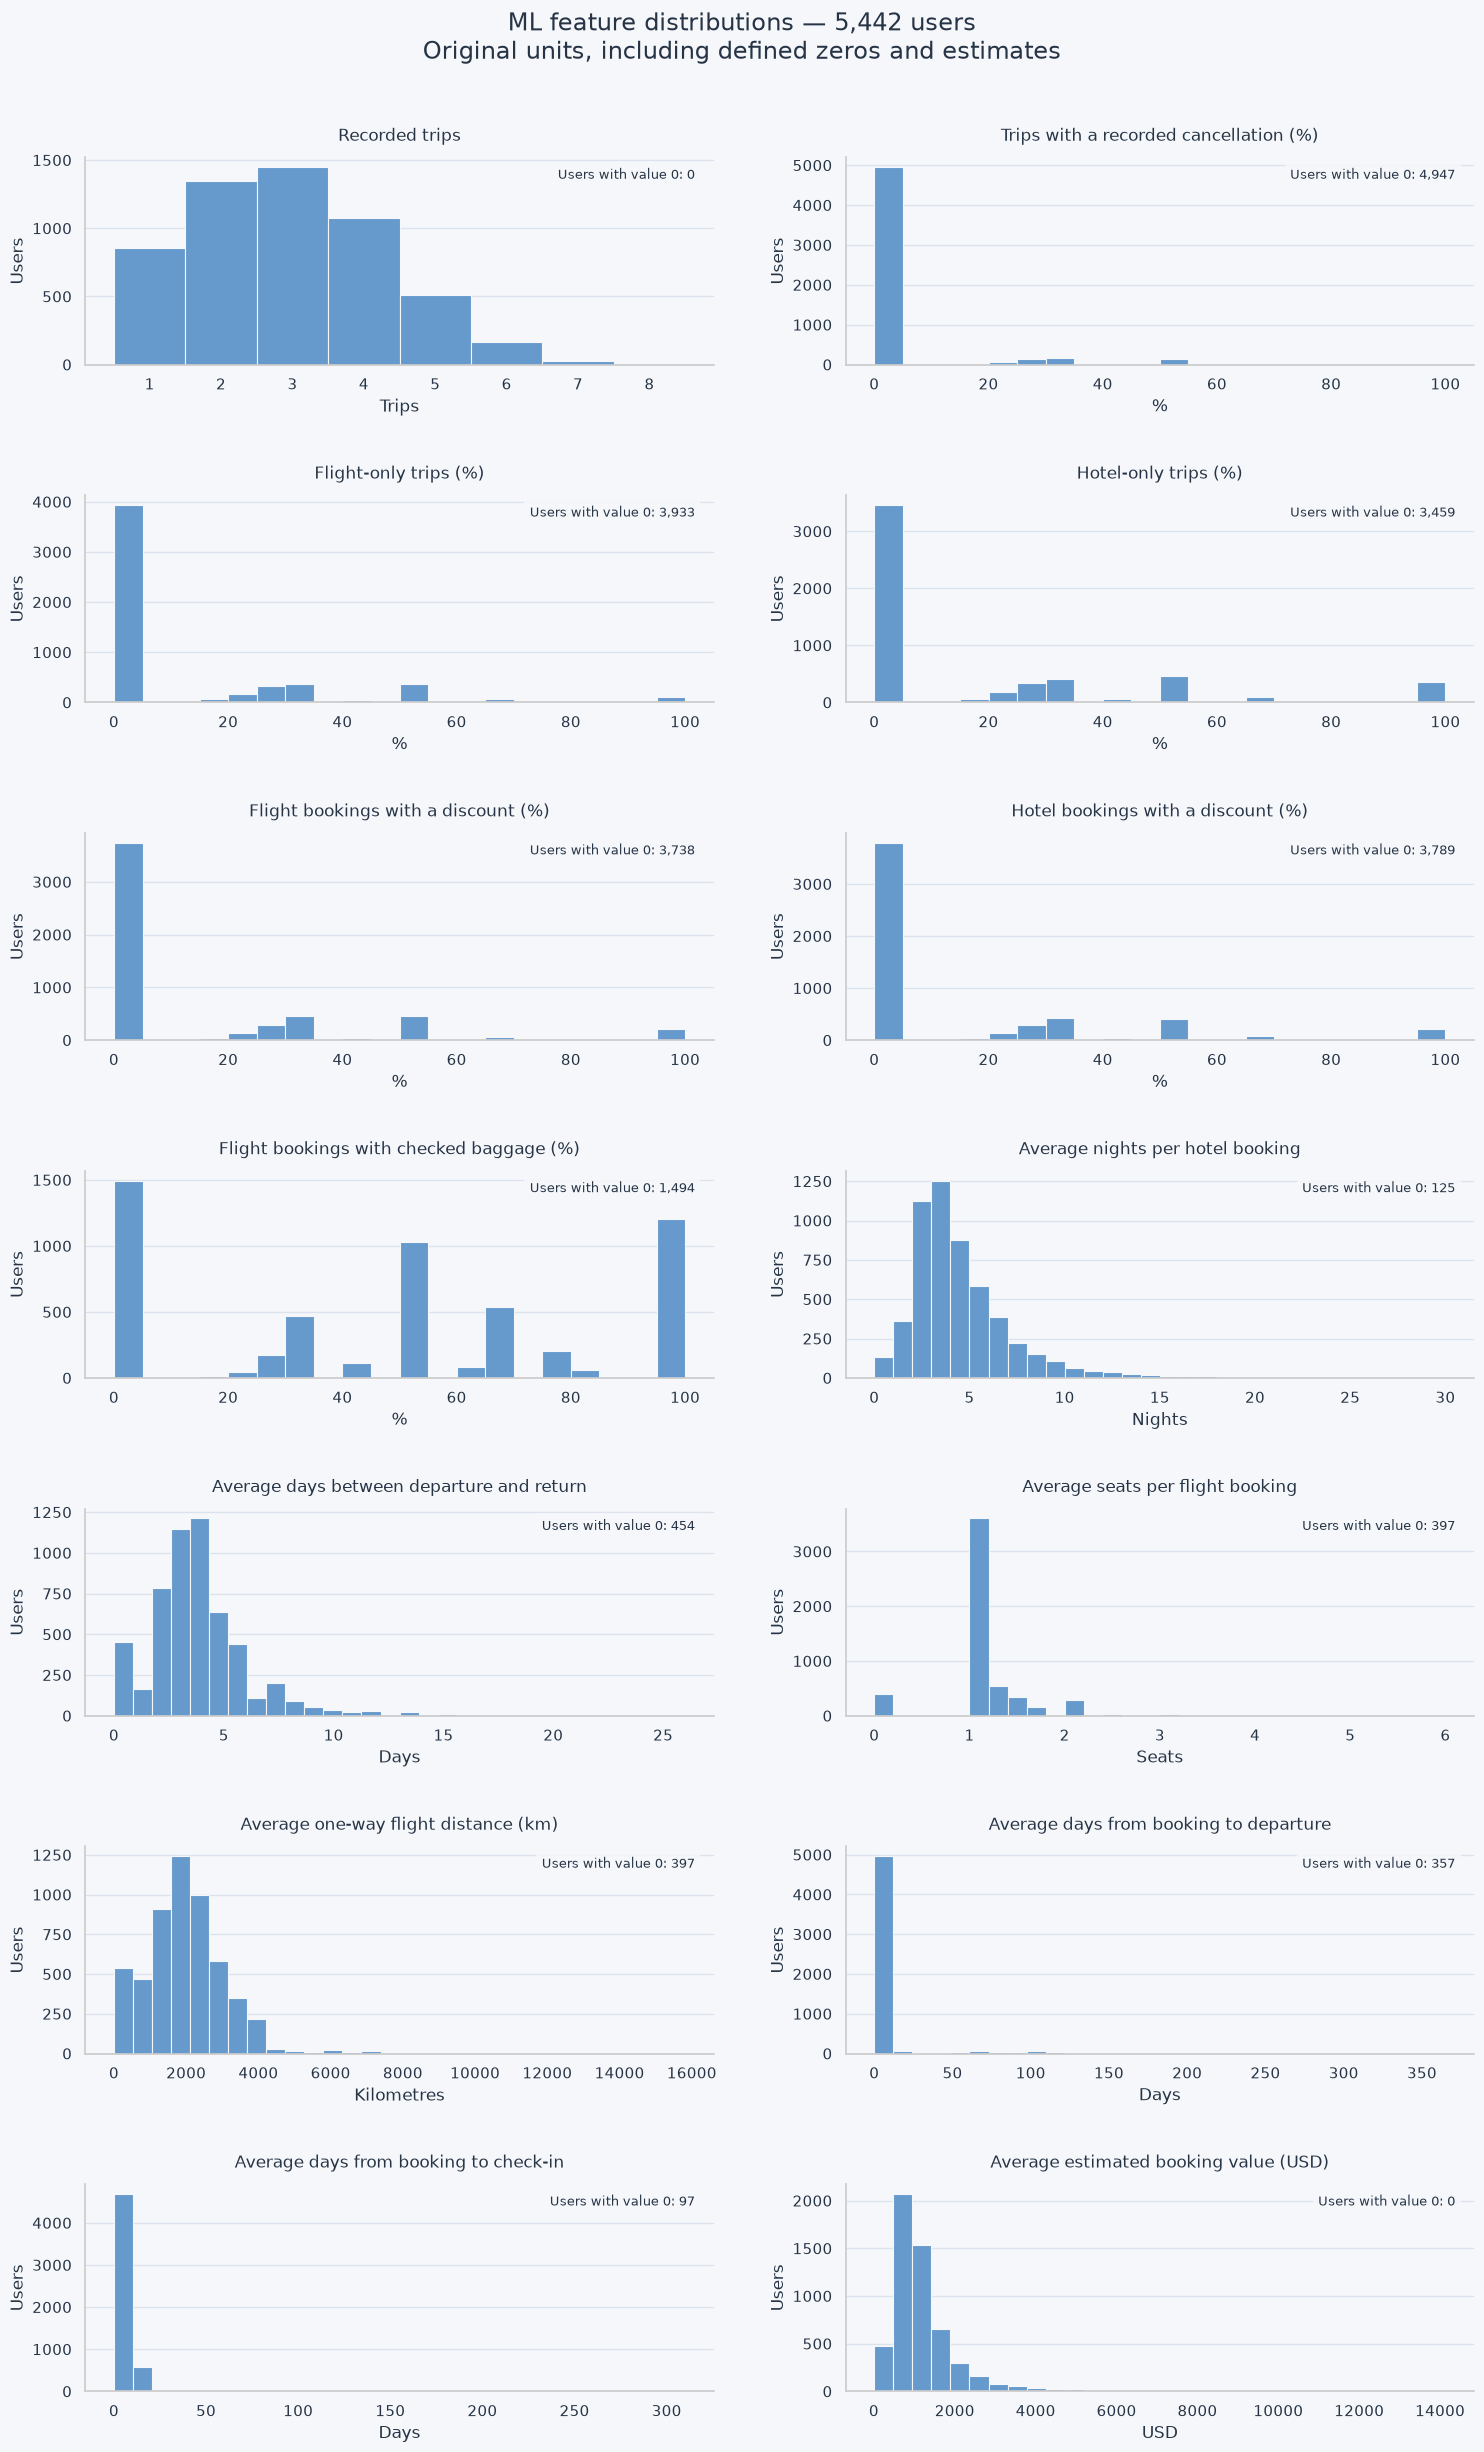

In [18]:
# inspect all feature distributions before transformation and scaling
# alle merkmalsverteilungen vor transformation und skalierung betrachten

from textwrap import fill

feature_units = {
    "trip_count": "Trips",
    "cancelled_trip_share_pct": "%",
    "flight_only_trip_share_pct": "%",
    "hotel_only_trip_share_pct": "%",
    "flight_discount_booking_share_pct": "%",
    "hotel_discount_booking_share_pct": "%",
    "flight_with_baggage_share_pct": "%",
    "avg_hotel_nights": "Nights",
    "avg_travel_days": "Days",
    "avg_seats_per_flight_booking": "Seats",
    "avg_flight_distance_km": "Kilometres",
    "avg_flight_booking_lead_days": "Days",
    "avg_hotel_booking_lead_days": "Days",
    "avg_trip_booking_value_usd": "USD",
}

features = list(ML_FEATURE_LABELS)

fig, axes = plt.subplots(
    nrows=7,
    ncols=2,
    figsize=(15, 25),
)

for ax, feature in zip(axes.flat, features):
    values = ml_work[feature].to_numpy(dtype=float)

    if feature.endswith("_pct"):
        bins = np.linspace(0, 100, 21)
    elif feature == "trip_count":
        bins = np.arange(
            np.floor(values.min()) - 0.5,
            np.ceil(values.max()) + 1.5,
            1,
        )
    else:
        bins = 30

    ax.hist(
        values,
        bins=bins,
        color=COLORS["blue"],
        edgecolor=COLORS["background"],
        linewidth=0.8,
    )

    ax.set_title(
        fill(ML_FEATURE_LABELS[feature], width=46),
        pad=12,
    )
    ax.set_xlabel(feature_units[feature])
    ax.set_ylabel("Users")
    ax.set_axisbelow(True)
    ax.grid(axis="x", visible=False)

    # zeros include the modelling conventions defined earlier
    zero_count = int(np.count_nonzero(values == 0))

    ax.text(
        0.97,
        0.95,
        f"Users with value 0: {zero_count:,}",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=9,
        bbox={
            "facecolor": COLORS["background"],
            "edgecolor": "none",
            "alpha": 0.9,
        },
    )

fig.suptitle(
    "ML feature distributions — 5,442 users\n"
    "Original units, including defined zeros and estimates",
    fontsize=17,
)

fig.tight_layout(rect=[0, 0, 1, 0.97], h_pad=3, w_pad=3)
plt.show()

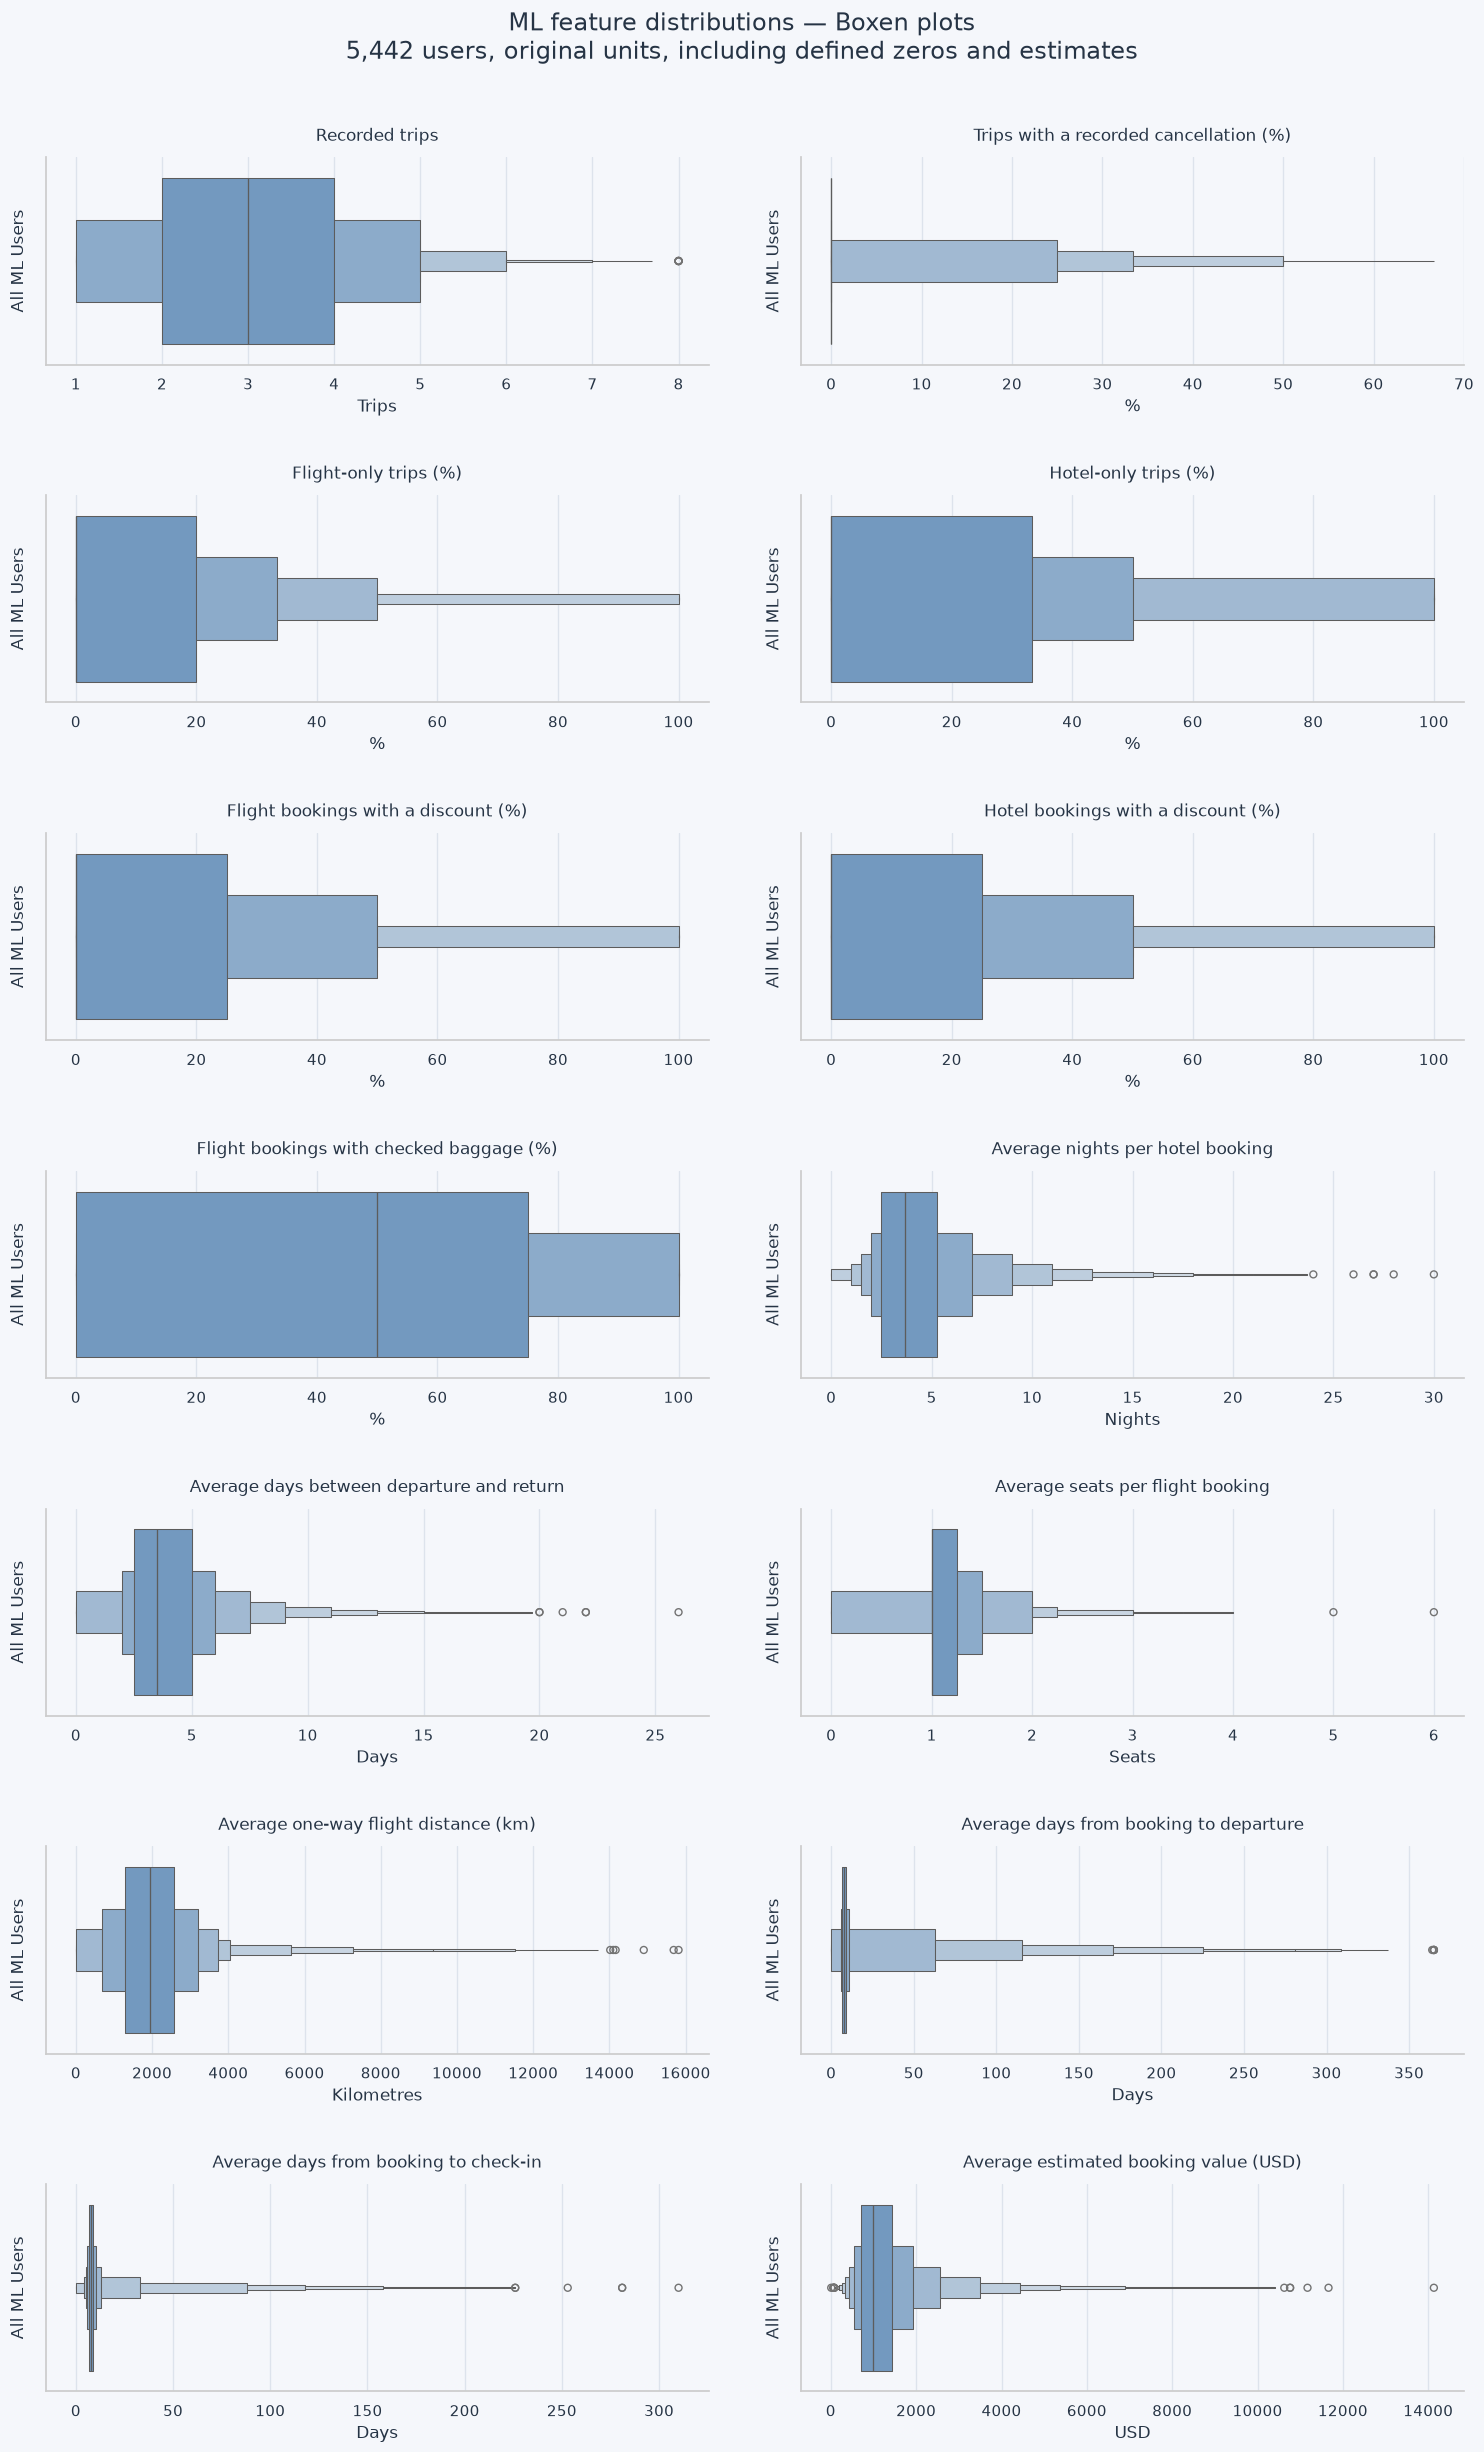

In [19]:
# inspect feature distributions with boxen plots
# merkmalsverteilungen zusätzlich als boxenplots betrachten

fig, axes = plt.subplots(
    nrows=7,
    ncols=2,
    figsize=(15, 25),
)

for ax, feature in zip(axes.flat, features):
    sns.boxenplot(
        x=ml_work[feature].to_numpy(dtype=float),
        ax=ax,
        color=COLORS["blue"],
    )

    ax.set_title(
        fill(ML_FEATURE_LABELS[feature], width=46),
        pad=12,
    )
    ax.set_xlabel(feature_units[feature])
    ax.set_ylabel("All ML Users")
    ax.set_axisbelow(True)
    ax.grid(axis="y", visible=False)

fig.suptitle(
    "ML feature distributions — Boxen plots\n"
    "5,442 users, original units, including defined zeros and estimates",
    fontsize=17,
)

fig.tight_layout(rect=[0, 0, 1, 0.97], h_pad=3, w_pad=3)
plt.show()

#### Two views of the feature distributions
#### Zwei Ansichten der Merkmalsverteilungen

Keep both visualisations because they provide complementary information:

- Histograms show how many users fall within each value interval.
- Boxen plots show the median and successive quantile ranges.
  The widest box contains the middle 50% of values.
  “All ML users” identifies the group shown, not a user count.

Similar distribution shapes do not necessarily indicate a relationship
between features. Many identical values can cause boxes to collapse into
lines. Long right tails indicate a small number of unusually large values.

Both views include the defined zeros and estimates. No data are changed.

---

Beide Darstellungen bleiben erhalten, da sie sich ergänzen:

- Histogramme zeigen, wie viele Nutzer in die jeweiligen Werteintervalle fallen.
- Boxenplots zeigen den Median und aufeinanderfolgende Quantilbereiche.
  Die breiteste Box enthält die mittleren 50% der Werte.
  „All ML users“ bezeichnet die dargestellte Gruppe, keine Nutzeranzahl.

Ähnliche Verteilungsformen bedeuten nicht automatisch einen Zusammenhang
zwischen Merkmalen. Viele identische Werte können Boxen zu Linien
zusammenfallen lassen. Lange rechte Ausläufer weisen auf wenige
ungewöhnlich große Werte hin.

Beide Ansichten enthalten die definierten Nullwerte und Schätzwerte.
Es werden keine Daten verändert.

### 3.15 Inspect value ranges and extremes
### 3.15 Wertebereiche und Extremwerte untersuchen

Compare the minimum, median, 95th percentile and maximum of each feature.
The 95th percentile is the value at or below which approximately 95% of
users lie.

Large differences between the median and maximum suggest a long upper
tail. Extreme values are not automatically errors and are not removed.

Minimum, Median, 95. Perzentil und Maximum jedes Merkmals vergleichen.
Das 95. Perzentil ist der Wert, bei oder unter dem ungefähr 95% der
Nutzer liegen.

Große Abstände zwischen Median und Maximum deuten auf einen langen
oberen Ausläufer hin. Extremwerte sind nicht automatisch Fehler
und werden nicht entfernt.


In [20]:
# compare typical values with the upper end of each distribution
# typische werte mit dem oberen ende jeder verteilung vergleichen

range_rows = []

for feature in features:
    values = ml_work[feature]

    range_rows.append({
        "Feature": ML_FEATURE_LABELS[feature],
        "Unit": feature_units[feature],
        "Minimum": values.min(),
        "Median": values.median(),
        "95th percentile": values.quantile(0.95),
        "Maximum": values.max(),
        "Users at zero": int(values.eq(0).sum()),
    })

feature_ranges = pd.DataFrame(range_rows)

display(style_overview(
    feature_ranges,
    "ML features — Typical values and extremes",
    {
        "Minimum": "{:,.2f}",
        "Median": "{:,.2f}",
        "95th percentile": "{:,.2f}",
        "Maximum": "{:,.2f}",
        "Users at zero": "{:,.0f}",
    },
))

print("No values have been changed or removed.")

Feature,Unit,Minimum,Median,95th percentile,Maximum,Users at zero
Recorded trips,Trips,1.00,3.00,5.00,8.00,0
Trips with a recorded cancellation (%),%,0.00,0.00,33.33,66.67,"4,947"
Flight-only trips (%),%,0.00,0.00,50.00,100.00,"3,933"
Hotel-only trips (%),%,0.00,0.00,100.00,100.00,"3,459"
Flight bookings with a discount (%),%,0.00,0.00,66.67,100.00,"3,738"
Hotel bookings with a discount (%),%,0.00,0.00,66.67,100.00,"3,789"
Flight bookings with checked baggage (%),%,0.00,50.00,100.00,100.00,"1,494"
Average nights per hotel booking,Nights,0.00,3.67,9.00,30.00,125
Average days between departure and return,Days,0.00,3.50,8.00,26.00,454
Average seats per flight booking,Seats,0.00,1.00,2.00,6.00,397


No values have been changed or removed.


### 3.16 Compare original and logarithmic distributions
### 3.16 Ursprüngliche und logarithmische Verteilungen vergleichen

Compare four features with long right tails before and after applying
log1p: flight and hotel booking lead times, flight distance and estimated
booking value.

log1p calculates log(1 + value). It compresses large values, preserves
their order and maps zero to zero. The transformed axis no longer shows
days, kilometres or dollars directly.

This is a comparison only. The original ML feature table remains unchanged.

Vier Merkmale mit langen rechten Ausläufern vor und nach log1p vergleichen:
Buchungsvorlauf für Flug und Hotel, Flugentfernung und geschätzter Buchungswert.

log1p berechnet log(1 + Wert). Große Werte werden zusammengedrückt,
ihre Reihenfolge bleibt erhalten und null bleibt null. Die transformierte
Achse zeigt keine direkten Tages-, Kilometer- oder Dollarwerte mehr.

Dies ist zunächst ein Vergleich. Die ursprüngliche ML-Merkmalstabelle
bleibt unverändert.

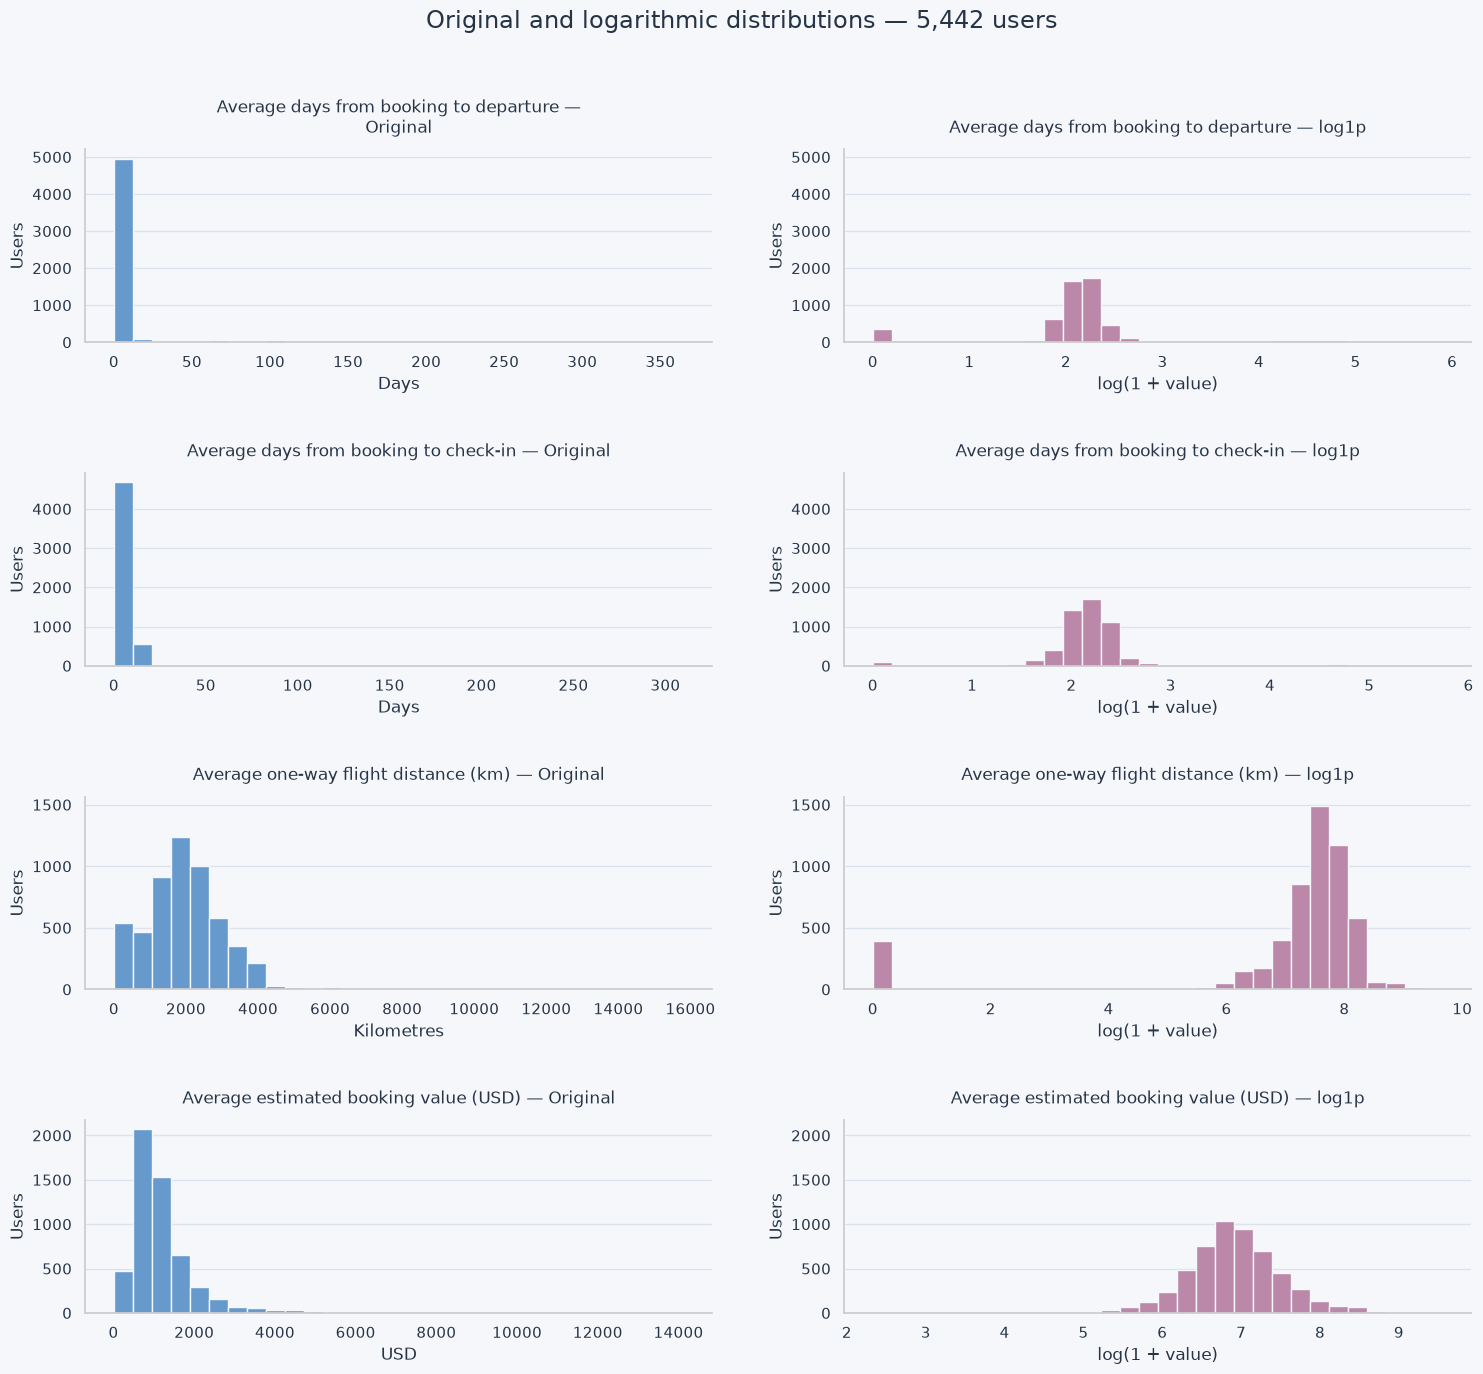

Comparison created. ml_work remains unchanged.


In [21]:
# compare original values with log1p in a separate table
# ursprüngliche werte mit log1p in einer separaten tabelle vergleichen

log_features = [
    "avg_flight_booking_lead_days",
    "avg_hotel_booking_lead_days",
    "avg_flight_distance_km",
    "avg_trip_booking_value_usd",
]

log_comparison = np.log1p(
    ml_work[log_features].astype(float)
)

fig, axes = plt.subplots(
    nrows=len(log_features),
    ncols=2,
    figsize=(15, 14),
)

for row, feature in enumerate(log_features):
    original = ml_work[feature].to_numpy(dtype=float)
    transformed = log_comparison[feature].to_numpy()

    axes[row, 0].hist(
        original,
        bins=30,
        color=COLORS["blue"],
        edgecolor=COLORS["background"],
    )

    axes[row, 1].hist(
        transformed,
        bins=30,
        color=COLORS["lavender"],
        edgecolor=COLORS["background"],
    )

    label = ML_FEATURE_LABELS[feature]

    axes[row, 0].set_title(
        fill(f"{label} — Original", width=48),
        pad=12,
    )
    axes[row, 1].set_title(
        fill(f"{label} — log1p", width=48),
        pad=12,
    )

    axes[row, 0].set_xlabel(feature_units[feature])
    axes[row, 1].set_xlabel("log(1 + value)")

    # use the same count scale within each pair
    upper_limit = max(
        axes[row, 0].get_ylim()[1],
        axes[row, 1].get_ylim()[1],
    )

    for ax in axes[row]:
        ax.set_ylim(0, upper_limit)
        ax.set_ylabel("Users")
        ax.set_axisbelow(True)
        ax.grid(axis="x", visible=False)

fig.suptitle(
    "Original and logarithmic distributions — 5,442 users",
    fontsize=17,
)

fig.tight_layout(rect=[0, 0, 1, 0.96], h_pad=3, w_pad=3)
plt.show()

print("Comparison created. ml_work remains unchanged.")

### 3.17 Assess the logarithmic transformations
### 3.17 Logarithmische Transformationen beurteilen

Compare distribution skewness before and after log1p.
Positive skewness indicates a longer right tail; negative skewness
indicates a longer left tail.

A value closer to zero is not automatically better for clustering.
Also consider structural zeros and the meaning of the feature.
No transformation is adopted solely because it produces a more
symmetric distribution.

Die Schiefe der Verteilungen vor und nach log1p vergleichen.
Positive Schiefe bezeichnet einen längeren rechten Ausläufer,
negative Schiefe einen längeren linken Ausläufer.

Ein Wert näher an null ist nicht automatisch besser für das Clustering.
Strukturelle Nullwerte und die Bedeutung des Merkmals ebenfalls beachten.
Eine Transformation wird nicht allein deshalb übernommen, weil sie
eine symmetrischere Verteilung erzeugt.

In [22]:
# assess the comparison without changing the ML working table
# den vergleich beurteilen, ohne die ML-arbeitstabelle zu verändern

transformation_rows = []

for feature in log_features:
    original = ml_work[feature].astype(float)
    transformed = log_comparison[feature]

    # validate preservation of users, ordering and zeros
    if not transformed.index.equals(original.index):
        raise ValueError("User assignments changed during transformation.")

    if not np.isfinite(transformed.to_numpy()).all():
        raise ValueError("Invalid logarithmic values found.")

    if not original.eq(0).equals(transformed.eq(0)):
        raise ValueError("Zero values changed during transformation.")

    transformation_rows.append({
        "Feature": ML_FEATURE_LABELS[feature],
        "Original skewness": original.skew(),
        "After log1p": transformed.skew(),
        "Users at zero": int(original.eq(0).sum()),
    })

transformation_review = pd.DataFrame(transformation_rows)

display(style_overview(
    transformation_review,
    "Logarithmic transformation — Distribution comparison",
    {
        "Original skewness": "{:.2f}",
        "After log1p": "{:.2f}",
        "Users at zero": "{:,.0f}",
    },
))

print("ml_work remains unchanged.")

Feature,Original skewness,After log1p,Users at zero
Average days from booking to departure,5.26,0.79,357
Average days from booking to check-in,7.96,1.33,97
Average one-way flight distance (km),2.56,-2.90,397
Average estimated booking value (USD),4.05,0.03,0


ml_work remains unchanged.


#### Transformation decisions
#### Entscheidungen zu den Transformationen

Apply log1p to flight booking lead time, hotel booking lead time and
estimated booking value. Their strong right tails are reduced, limiting
the influence of unusually large values.

Keep flight distance unchanged before scaling. Its skewness changes
from 2.56 to −2.90 after log1p. The 397 structural zeros remain far
below the transformed positive distances, creating a pronounced left tail.

Keep the other features unchanged before scaling.
These are initial modelling choices, not proof of an optimal solution.
Evaluate their usefulness through the subsequent clustering results.
Preserve the original values for reporting and interpretation.

---

log1p auf den Buchungsvorlauf für Flüge und Hotels sowie den geschätzten
Buchungswert anwenden. Ihre starken rechten Ausläufer werden reduziert,
sodass ungewöhnlich große Werte weniger Einfluss erhalten.

Die Flugentfernung vor der Skalierung unverändert lassen. Ihre Schiefe
wechselt durch log1p von 2,56 auf −2,90. Die 397 strukturellen Nullwerte
liegen weit unter den transformierten positiven Entfernungen und
erzeugen einen ausgeprägten linken Ausläufer.

Die übrigen Merkmale vor der Skalierung ebenfalls unverändert lassen.
Dies sind begründete Ausgangsentscheidungen, kein Nachweis einer optimalen
Lösung. Ihre Eignung wird anhand der anschließenden Clustering-Ergebnisse
beurteilt. Die ursprünglichen Werte bleiben für Berichte und Interpretation
erhalten.

### 3.18 Apply the selected transformations
### 3.18 Ausgewählte Transformationen anwenden

Create a separate modelling table and apply log1p to flight booking
lead time, hotel booking lead time and estimated booking value.

Keep all other features unchanged. Preserve users, feature names and
structural zeros. Scaling follows in the next step.

Eine separate Modellierungstabelle erstellen und log1p auf den
Buchungsvorlauf für Flüge und Hotels sowie den geschätzten Buchungswert
anwenden.

Alle anderen Merkmale unverändert übernehmen. Nutzer, Merkmalsnamen
und strukturelle Nullwerte erhalten. Die Skalierung folgt im nächsten Schritt.

In [23]:
# create transformed model inputs while preserving original-unit values
# transformierte modelleingaben erstellen, originalwerte erhalten

selected_log_features = [
    "avg_flight_booking_lead_days",
    "avg_hotel_booking_lead_days",
    "avg_trip_booking_value_usd",
]

ml_transformed = ml_work.astype(float).copy()

if ml_transformed[selected_log_features].lt(0).any().any():
    raise ValueError("Negative values found in selected log features.")

ml_transformed[selected_log_features] = np.log1p(
    ml_transformed[selected_log_features]
)

# verify that unselected features remain unchanged
unchanged_features = [
    feature
    for feature in ml_work.columns
    if feature not in selected_log_features
]

pd.testing.assert_frame_equal(
    ml_transformed[unchanged_features],
    ml_work[unchanged_features].astype(float),
)

if not ml_transformed.index.equals(ml_work.index):
    raise ValueError("User assignments changed.")

if not ml_transformed.columns.equals(ml_work.columns):
    raise ValueError("Feature names or order changed.")

if not np.isfinite(ml_transformed.to_numpy()).all():
    raise ValueError("Missing or infinite transformed values found.")

if not ml_transformed.eq(0).equals(ml_work.eq(0)):
    raise ValueError("Zero positions changed.")

transformation_summary = pd.DataFrame({
    "Feature": [
        ML_FEATURE_LABELS[feature]
        for feature in ml_transformed.columns
    ],
    "Treatment": [
        "log1p"
        if feature in selected_log_features
        else "Unchanged"
        for feature in ml_transformed.columns
    ],
})

display(style_overview(
    transformation_summary,
    "ML preparation — Applied transformations",
))

print("Users retained:", f"{len(ml_transformed):,}")
print("Features retained:", len(ml_transformed.columns))
print("Original-unit table preserved: ml_work")
print("Transformation checks passed.")

Feature,Treatment
Recorded trips,Unchanged
Trips with a recorded cancellation (%),Unchanged
Flight-only trips (%),Unchanged
Hotel-only trips (%),Unchanged
Flight bookings with a discount (%),Unchanged
Hotel bookings with a discount (%),Unchanged
Flight bookings with checked baggage (%),Unchanged
Average nights per hotel booking,Unchanged
Average days between departure and return,Unchanged
Average seats per flight booking,Unchanged


Users retained: 5,442
Features retained: 14
Original-unit table preserved: ml_work
Transformation checks passed.


Two tables are now available:

- `ml_work`: all 14 features in their original units, including the
  previously defined zero codings and estimates.
- `ml_transformed`: the same users and features, with log1p applied
  to the three selected features. This table will be used for scaling.

Both tables contain 5,442 users and 14 features.

---

Es stehen nun zwei Tabellen zur Verfügung:

- `ml_work`: alle 14 Merkmale in ihren ursprünglichen Einheiten,
  einschließlich der zuvor definierten Null-Codierungen und Schätzwerte.
- `ml_transformed`: dieselben Nutzer und Merkmale, mit log1p für die
  drei ausgewählten Merkmale. Diese Tabelle wird für die Skalierung verwendet.

Beide Tabellen enthalten 5.442 Nutzer und 14 Merkmale.

### 3.19 Scale the model features
### 3.19 Modellmerkmale skalieren

Apply StandardScaler to the transformed feature table.
Each feature is centred around zero and scaled to a standard deviation
of one. This prevents measurement units alone from dominating distances.

Use only the 5,442 ML users to fit the scaler.
Preserve the fitted scaler and create a separate scaled table.
Negative scaled values indicate values below the feature mean.
Original zeros are also rescaled; their definitions remain documented
in the unscaled tables.

StandardScaler does not remove extreme values or guarantee normal
distributions. Its suitability will be assessed through the clustering.

StandardScaler auf die transformierte Merkmalstabelle anwenden.
Jedes Merkmal wird um null zentriert und auf eine Standardabweichung
von eins skaliert. Dadurch sollen nicht allein die Maßeinheiten
die Abstandsberechnung dominieren.

Den Scaler ausschließlich an die 5.442 ML-Nutzer anpassen.
Den angepassten Scaler behalten und eine separate skalierte Tabelle
erstellen. Negative skalierte Werte liegen unter dem Merkmalsdurchschnitt.
Auch ursprüngliche Nullwerte werden umgerechnet; ihre Bedeutung bleibt
in den unskalierten Tabellen dokumentiert.

StandardScaler entfernt keine Extremwerte und garantiert keine
Normalverteilung. Seine Eignung wird anhand des Clusterings beurteilt.

In [24]:
# fit the scaler only on the ML population
# scaler ausschließlich an die ML-nutzer anpassen

from sklearn.preprocessing import StandardScaler

if not np.isfinite(ml_transformed.to_numpy()).all():
    raise ValueError("Missing or infinite input values found.")

if ml_transformed.std(ddof=0).eq(0).any():
    raise ValueError("A constant feature requires review before scaling.")

scaler = StandardScaler()

ml_scaled = pd.DataFrame(
    scaler.fit_transform(ml_transformed),
    index=ml_transformed.index,
    columns=ml_transformed.columns,
)

# validate scaled values and retained structure
if not ml_scaled.index.equals(ml_transformed.index):
    raise ValueError("User assignments changed.")

if not ml_scaled.columns.equals(ml_transformed.columns):
    raise ValueError("Feature names or order changed.")

if not np.isfinite(ml_scaled.to_numpy()).all():
    raise ValueError("Missing or infinite scaled values found.")

if not np.allclose(ml_scaled.mean(), 0, atol=1e-10):
    raise ValueError("Scaled means are not approximately zero.")

if not np.allclose(ml_scaled.std(ddof=0), 1, atol=1e-10):
    raise ValueError("Scaled standard deviations are not approximately one.")

scaling_summary = pd.DataFrame({
    "Feature": [
        ML_FEATURE_LABELS[feature]
        for feature in ml_scaled.columns
    ],
    "Mean after scaling": ml_scaled.mean().to_numpy(),
    "Standard deviation after scaling": (
        ml_scaled.std(ddof=0).to_numpy()
    ),
})

display(style_overview(
    scaling_summary,
    "ML preparation — StandardScaler checks",
    {
        "Mean after scaling": "{:.4f}",
        "Standard deviation after scaling": "{:.4f}",
    },
))

print("Users retained:", f"{len(ml_scaled):,}")
print("Features retained:", len(ml_scaled.columns))
print("Scaling checks passed.")

Feature,Mean after scaling,Standard deviation after scaling
Recorded trips,0.0000,1.0000
Trips with a recorded cancellation (%),0.0000,1.0000
Flight-only trips (%),0.0000,1.0000
Hotel-only trips (%),0.0000,1.0000
Flight bookings with a discount (%),0.0000,1.0000
Hotel bookings with a discount (%),0.0000,1.0000
Flight bookings with checked baggage (%),0.0000,1.0000
Average nights per hotel booking,-0.0000,1.0000
Average days between departure and return,-0.0000,1.0000
Average seats per flight booking,0.0000,1.0000


Users retained: 5,442
Features retained: 14
Scaling checks passed.


#### StandardScaler — Interpretation of the results
#### StandardScaler — Einordnung der Ergebnisse

All 14 features have a mean of approximately zero and a standard
deviation of one after scaling.

The mean describes the average. The standard deviation measures how
strongly values vary around that average.

A scaled value of:
- 0 represents the feature mean;
- +1 represents one standard deviation above the mean;
- −1 represents one standard deviation below the mean.

The individual values have not all become zero or one.
Instead, each feature now uses its standard deviation as its unit.
The three logarithmically transformed features are scaled on that
transformed basis.

Displayed values of −0.0000 are tiny numerical rounding differences
and can be interpreted as zero.

This confirms correct scaling, not the quality of future clusters.
The original-unit values remain available in `ml_work`,
the transformed values in `ml_transformed`, and the scaled values
in `ml_scaled`.

---

Alle 14 Merkmale haben nach der Skalierung einen Mittelwert von
ungefähr null und eine Standardabweichung von eins.

Der Mittelwert beschreibt den Durchschnitt. Die Standardabweichung
misst, wie stark die Werte um diesen Durchschnitt streuen.

Ein skalierter Wert von:
- 0 entspricht dem Merkmalsdurchschnitt;
- +1 liegt eine Standardabweichung über dem Durchschnitt;
- −1 liegt eine Standardabweichung unter dem Durchschnitt.

Die einzelnen Werte sind nicht alle null oder eins geworden.
Stattdessen verwendet jedes Merkmal nun seine Standardabweichung
als Maßeinheit. Bei den drei logarithmisch transformierten Merkmalen
erfolgt die Skalierung auf Grundlage dieser transformierten Werte.

Angezeigte Werte von −0.0000 entstehen durch winzige numerische
Rundungsabweichungen und können als null interpretiert werden.

Die Prüfung bestätigt die korrekte Skalierung, nicht die Qualität
späterer Cluster. Die Werte in ursprünglichen Einheiten bleiben
in `ml_work`, die transformierten Werte in `ml_transformed`
und die skalierten Werte in `ml_scaled` erhalten.

### 3.20 Visualise the effect of scaling
### 3.20 Wirkung der Skalierung visualisieren

Compare the transformed features before and after StandardScaler.
Before scaling, the features still have different units and ranges.
After scaling, they have a common standardised scale.

Scaling changes location and spread, not the distribution shape
within each feature. Extreme values remain visible.
The left-hand panel already includes the three log1p transformations.

Die transformierten Merkmale vor und nach StandardScaler vergleichen.
Vor der Skalierung besitzen sie weiterhin unterschiedliche Einheiten
und Wertebereiche. Danach verwenden sie eine gemeinsame standardisierte Skala.

Die Skalierung verändert Lage und Streuung, nicht die Verteilungsform
innerhalb eines Merkmals. Extremwerte bleiben sichtbar.
Die linke Darstellung enthält bereits die drei log1p-Transformationen.

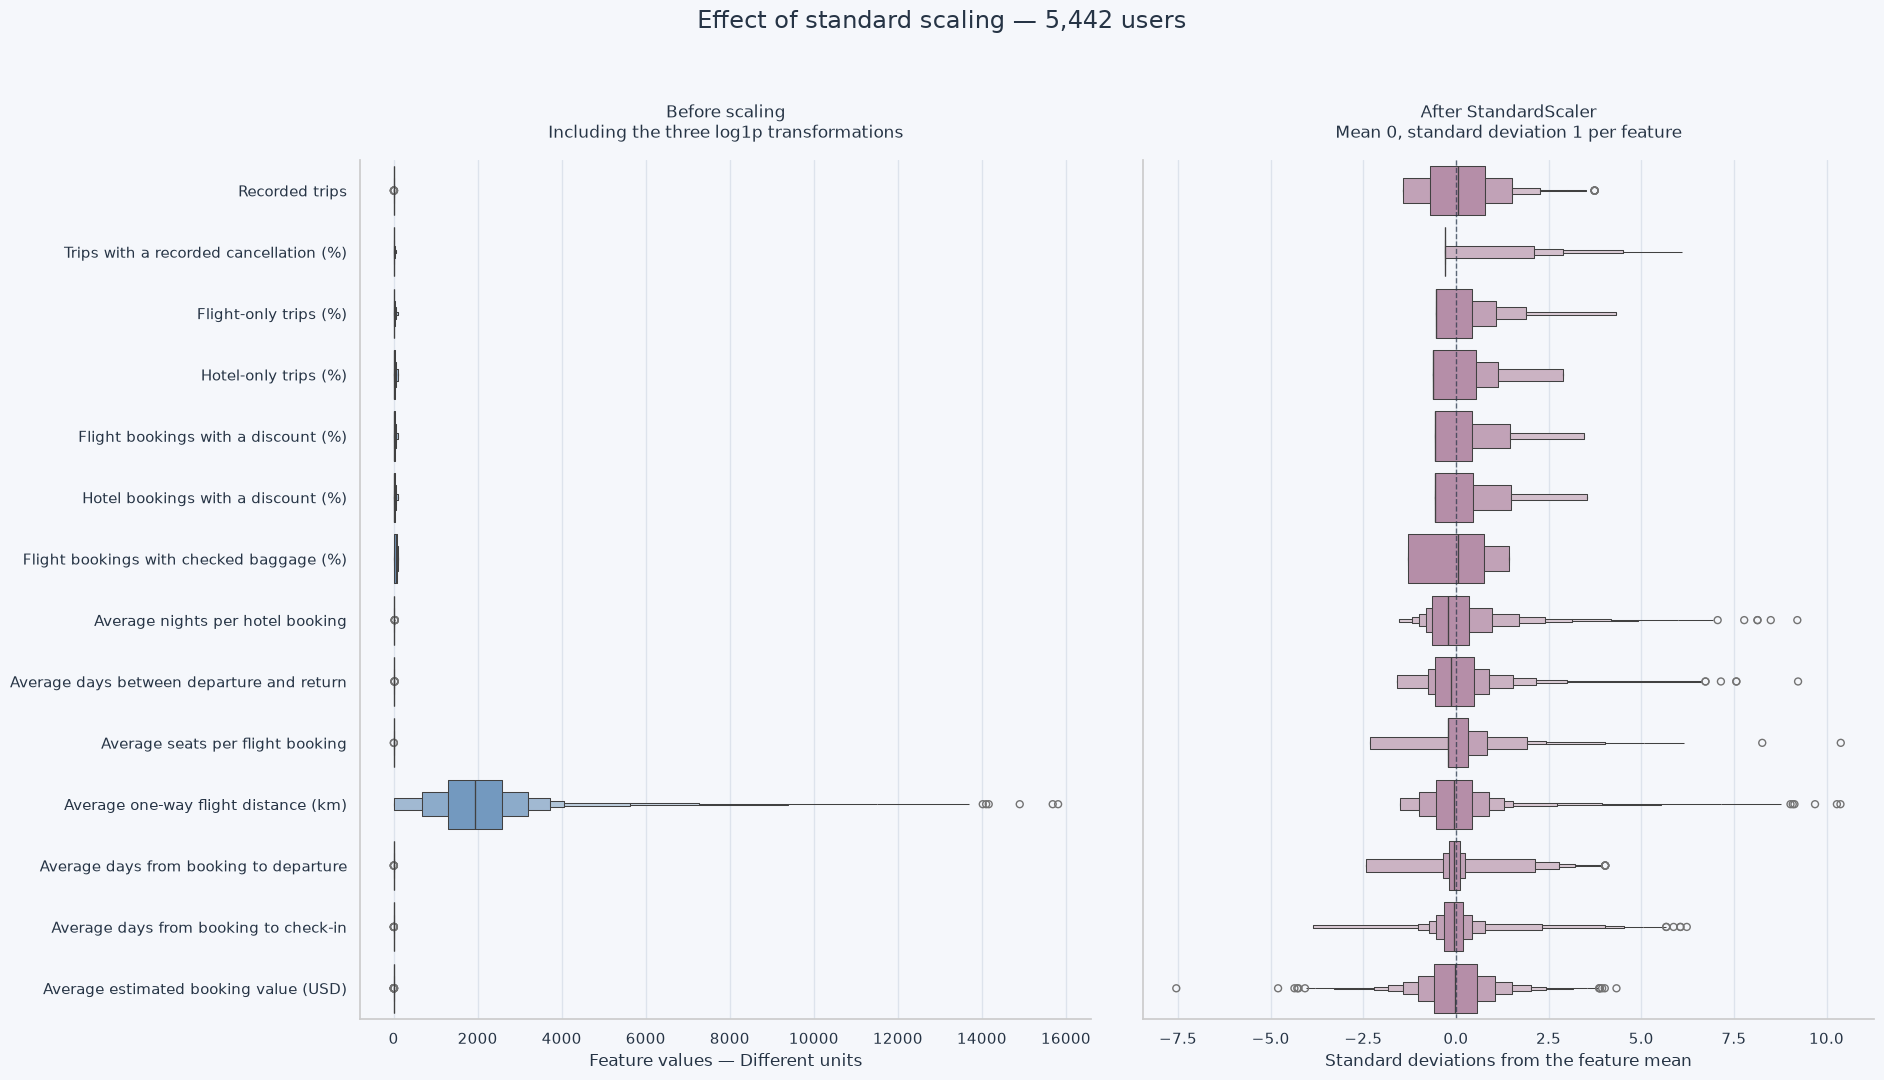

In [25]:
# compare distributions before and after standard scaling
# verteilungen vor und nach der standardskalierung vergleichen

feature_order = list(ml_transformed.columns)

before_plot = ml_transformed[feature_order].rename(
    columns=ML_FEATURE_LABELS
)

after_plot = ml_scaled[feature_order].rename(
    columns=ML_FEATURE_LABELS
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(19, 11),
    sharey=True,
)

sns.boxenplot(
    data=before_plot,
    orient="h",
    color=COLORS["blue"],
    ax=axes[0],
)

sns.boxenplot(
    data=after_plot,
    orient="h",
    color=COLORS["lavender"],
    ax=axes[1],
)

axes[0].set_title(
    "Before scaling\nIncluding the three log1p transformations",
    pad=16,
)
axes[0].set_xlabel("Feature values — Different units")

axes[1].set_title(
    "After StandardScaler\nMean 0, standard deviation 1 per feature",
    pad=16,
)
axes[1].set_xlabel("Standard deviations from the feature mean")
axes[1].axvline(
    0,
    color=COLORS["text"],
    linestyle="--",
    linewidth=1,
    alpha=0.7,
)

for ax in axes:
    ax.set_ylabel("")
    ax.set_axisbelow(True)
    ax.grid(axis="y", visible=False)

fig.suptitle(
    "Effect of standard scaling — 5,442 users",
    fontsize=17,
)

fig.tight_layout(rect=[0, 0, 1, 0.95], w_pad=3)
plt.show()

### 3.21 Prepare the MinMax comparison
### 3.21 MinMax-Vergleich vorbereiten

Apply MinMaxScaler to the same transformed table used for StandardScaler.
For each feature, the observed minimum becomes zero and the maximum one.

Keep identical users, features and logarithmic transformations.
Only the scaling method differs. Preserve both variants for the
subsequent K-Means comparison.

A scaled zero represents the observed minimum, not necessarily
“no booking”. Refer to the original-unit table for interpretation.

MinMaxScaler auf dieselbe transformierte Tabelle wie StandardScaler
anwenden. Je Merkmal wird das beobachtete Minimum zu null und
das Maximum zu eins.

Nutzer, Merkmale und logarithmische Transformationen bleiben identisch.
Nur die Skalierung unterscheidet sich. Beide Varianten für den
anschließenden K-Means-Vergleich behalten.

Eine skalierte null bezeichnet das beobachtete Minimum, nicht
zwangsläufig „keine Buchung“. Für die inhaltliche Interpretation
die Tabelle in ursprünglichen Einheiten verwenden.

In [26]:
# prepare a separate MinMax variant using identical inputs
# separate MinMax-variante mit identischer datengrundlage erstellen

from sklearn.preprocessing import MinMaxScaler

# retain an explicit name for the fitted StandardScaler
standard_scaler = scaler

if not np.isfinite(ml_transformed.to_numpy()).all():
    raise ValueError("Missing or infinite input values found.")

if ml_transformed.nunique().le(1).any():
    raise ValueError("A constant feature requires review.")

minmax_scaler = MinMaxScaler(feature_range=(0, 1))

ml_minmax = pd.DataFrame(
    minmax_scaler.fit_transform(ml_transformed),
    index=ml_transformed.index,
    columns=ml_transformed.columns,
)

# verify identical users and features in both variants
if not ml_minmax.index.equals(ml_scaled.index):
    raise ValueError("User assignments differ between scaling variants.")

if not ml_minmax.columns.equals(ml_scaled.columns):
    raise ValueError("Features differ between scaling variants.")

if not np.isfinite(ml_minmax.to_numpy()).all():
    raise ValueError("Missing or infinite MinMax values found.")

if not np.allclose(ml_minmax.min(), 0, atol=1e-10):
    raise ValueError("MinMax minimum values are not approximately zero.")

if not np.allclose(ml_minmax.max(), 1, atol=1e-10):
    raise ValueError("MinMax maximum values are not approximately one.")

minmax_summary = pd.DataFrame({
    "Feature": [
        ML_FEATURE_LABELS[feature]
        for feature in ml_minmax.columns
    ],
    "Minimum after scaling": ml_minmax.min().to_numpy(),
    "Maximum after scaling": ml_minmax.max().to_numpy(),
})

display(style_overview(
    minmax_summary,
    "ML preparation — MinMaxScaler checks",
    {
        "Minimum after scaling": "{:.4f}",
        "Maximum after scaling": "{:.4f}",
    },
))

print("Users retained:", f"{len(ml_minmax):,}")
print("Features retained:", len(ml_minmax.columns))
print("StandardScaler variant: ml_scaled")
print("MinMaxScaler variant: ml_minmax")
print("MinMax scaling checks passed.")

Feature,Minimum after scaling,Maximum after scaling
Recorded trips,0.0000,1.0000
Trips with a recorded cancellation (%),0.0000,1.0000
Flight-only trips (%),0.0000,1.0000
Hotel-only trips (%),0.0000,1.0000
Flight bookings with a discount (%),0.0000,1.0000
Hotel bookings with a discount (%),0.0000,1.0000
Flight bookings with checked baggage (%),0.0000,1.0000
Average nights per hotel booking,0.0000,1.0000
Average days between departure and return,0.0000,1.0000
Average seats per flight booking,0.0000,1.0000


Users retained: 5,442
Features retained: 14
StandardScaler variant: ml_scaled
MinMaxScaler variant: ml_minmax
MinMax scaling checks passed.


### 3.22 Compare the scaling variants visually
### 3.22 Skalierungsvarianten visuell vergleichen

Compare the same 14 features after StandardScaler and MinMaxScaler.
StandardScaler expresses values relative to each feature's mean and
standard deviation. MinMaxScaler expresses their position between
the observed minimum and maximum.

The panels use different x-axis scales. Compare the concentration and
tails within each feature, not absolute box widths across panels.
Neither plot alone determines which scaling is better for clustering.

Dieselben 14 Merkmale nach StandardScaler und MinMaxScaler vergleichen.
StandardScaler beschreibt Werte relativ zum Mittelwert und zur
Standardabweichung. MinMaxScaler beschreibt ihre Position zwischen
beobachtetem Minimum und Maximum.

Die Darstellungen verwenden unterschiedliche x-Achsen.
Häufungen und Ausläufer innerhalb der Merkmale vergleichen, nicht
die absoluten Boxbreiten zwischen den Darstellungen.
Aus den Grafiken allein ergibt sich noch keine bessere Skalierung
für das Clustering.

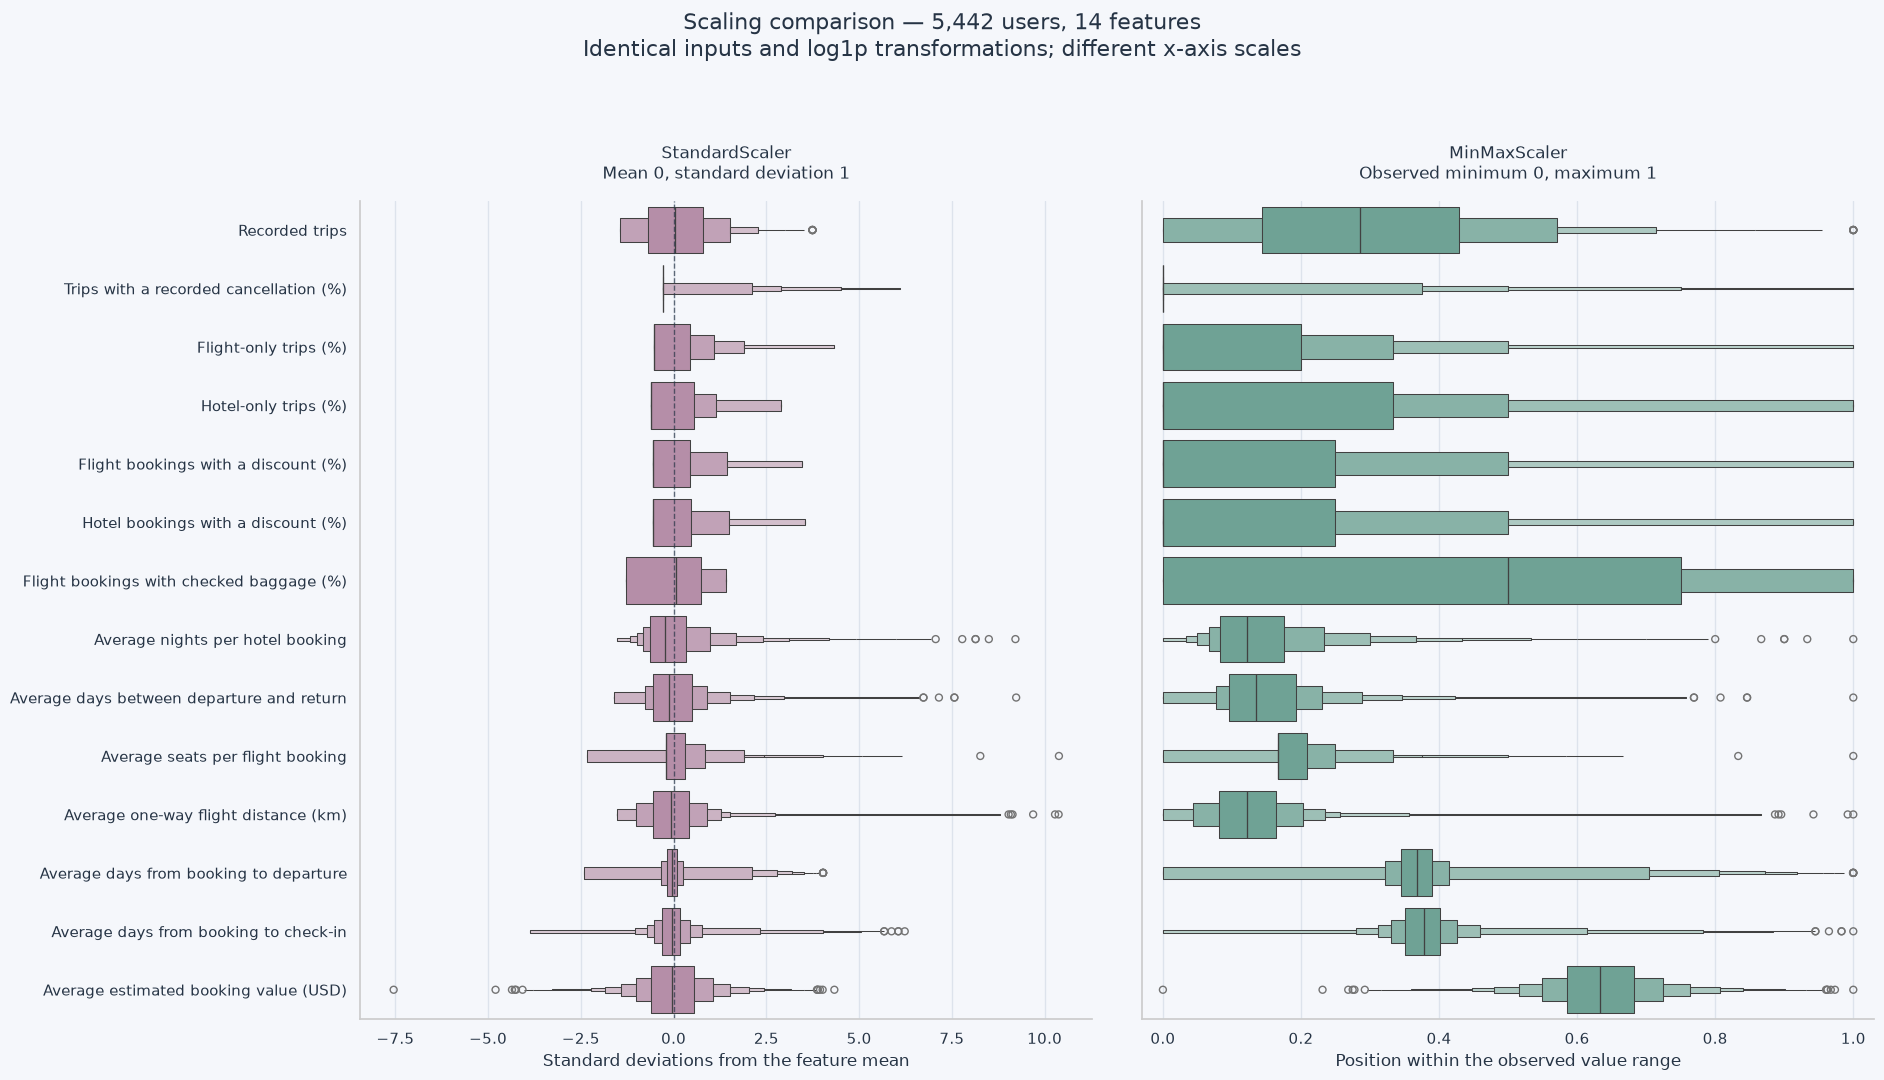

In [27]:
# compare both scaling variants using identical users and feature order
# beide skalierungsvarianten mit denselben nutzern und merkmalen vergleichen

feature_order = list(ml_transformed.columns)

standard_plot = ml_scaled[feature_order].rename(
    columns=ML_FEATURE_LABELS
)

minmax_plot = ml_minmax[feature_order].rename(
    columns=ML_FEATURE_LABELS
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(19, 11),
    sharey=True,
)

sns.boxenplot(
    data=standard_plot,
    orient="h",
    color=COLORS["lavender"],
    ax=axes[0],
)

sns.boxenplot(
    data=minmax_plot,
    orient="h",
    color=COLORS["mint"],
    ax=axes[1],
)

axes[0].set_title(
    "StandardScaler\nMean 0, standard deviation 1",
    pad=16,
)
axes[0].set_xlabel("Standard deviations from the feature mean")
axes[0].axvline(
    0,
    color=COLORS["text"],
    linestyle="--",
    linewidth=1,
    alpha=0.7,
)

axes[1].set_title(
    "MinMaxScaler\nObserved minimum 0, maximum 1",
    pad=16,
)
axes[1].set_xlabel("Position within the observed value range")
axes[1].set_xlim(-0.03, 1.03)
axes[1].set_xticks(np.linspace(0, 1, 6))

for ax in axes:
    ax.set_ylabel("")
    ax.set_axisbelow(True)
    ax.grid(axis="y", visible=False)

fig.suptitle(
    "Scaling comparison — 5,442 users, 14 features\n"
    "Identical inputs and log1p transformations; different x-axis scales",
    fontsize=16,
)

fig.tight_layout(rect=[0, 0, 1, 0.94], w_pad=3)
plt.show()

#### Scaling comparison — Interpretation
#### Skalierungsvergleich — Einordnung

Both scalers preserve the distribution shape within each feature.
They change its location and scale, not the order of users.

StandardScaler gives each feature a mean of zero and a standard
deviation of one. MinMaxScaler maps each feature's observed minimum
to zero and maximum to one.

The MinMax plots appear more stretched because every feature spans
the full range from zero to one. The panels use different x-axis scales,
so absolute box widths cannot be compared directly.

The scaling methods change the relative influence of features on
distances between users. Neither visualisation alone establishes
which variant is more suitable. Both will be compared using K-Means,
cluster quality, stability and interpretable user profiles.

---

Beide Scaler erhalten die Verteilungsform innerhalb jedes Merkmals.
Sie verändern Lage und Maßstab, nicht die Reihenfolge der Nutzer.

StandardScaler gibt jedem Merkmal einen Mittelwert von null und
eine Standardabweichung von eins. MinMaxScaler setzt das beobachtete
Minimum jedes Merkmals auf null und das Maximum auf eins.

Die MinMax-Darstellungen wirken gedehnter, weil jedes Merkmal den
gesamten Bereich von null bis eins aufspannt. Die Grafiken verwenden
unterschiedliche x-Achsen; absolute Boxbreiten sind deshalb nicht
direkt vergleichbar.

Die Skalierungen verändern den relativen Einfluss der Merkmale auf
die Abstände zwischen Nutzern. Welche Variante besser geeignet ist,
lässt sich aus der Grafik allein nicht bestimmen. Beide werden anhand
von K-Means-Ergebnissen, Clusterqualität, Stabilität und verständlichen
Nutzerprofilen verglichen.

## 4. K-Means clustering

Group users by similarities across the 14 prepared features.
Compare StandardScaler and MinMaxScaler using identical model settings.

Cluster numbers are identifiers, not customer descriptions or assigned
benefits. Interpret the groups after examining their original-unit profiles.

Nutzer anhand ihrer Ähnlichkeit in den 14 vorbereiteten Merkmalen gruppieren.
StandardScaler und MinMaxScaler mit identischen Modelleinstellungen vergleichen.

Clusternummern sind Kennungen, keine Kundenbeschreibungen oder zugewiesenen
Vorteile. Die Gruppen werden anschließend anhand ihrer Profile in
ursprünglichen Einheiten interpretiert.

### 4.1 Compare different numbers of clusters
### 4.1 Unterschiedliche Clusterzahlen vergleichen

Model settings:

- `n_clusters`: test values from 2 to 10.
- `init="k-means++"`: select initial centres using a distance-based
  procedure that favours centres spread across the data.
- `n_init=20`: run 20 initialisations for each cluster count and retain
  the solution with the lowest inertia.
- `max_iter=300`: allow up to 300 centre-update iterations per
  initialisation. The algorithm may converge earlier.
- `random_state=42`: fix the random seed to make runs reproducible
  under the same software and data conditions.

Twenty initialisations reduce dependence on an unlucky starting
configuration. This is a practical choice, not a guaranteed optimum
or a separate stability test.

Record inertia, silhouette score and the smallest and largest group sizes.
Calculate the silhouette score using all 5,442 ML users.

Inertia measures squared distances to cluster centres and is compared
only within the same scaling variant. Silhouette measures separation
between groups; higher values indicate better separation in the
respective feature space.

No final model is selected at this stage. Stability and meaningful
user profiles will also inform the decision.

Modelleinstellungen:

- `n_clusters`: Werte von 2 bis 10 testen.
- `init="k-means++"`: Startzentren mit einem abstandsbasierten Verfahren
  auswählen, das über die Daten verteilte Zentren begünstigt.
- `n_init=20`: Für jede Clusterzahl 20 Initialisierungen durchführen
  und die Lösung mit der niedrigsten Inertia behalten.
- `max_iter=300`: Je Initialisierung höchstens 300 Anpassungsschritte
  der Clusterzentren erlauben. Der Algorithmus kann früher konvergieren.
- `random_state=42`: Den Zufallsstartwert festlegen, um Durchläufe
  bei gleichen Software- und Datenbedingungen wiederholbar zu machen.

Die 20 Initialisierungen verringern die Abhängigkeit von ungünstigen
Startzentren. Die Anzahl ist eine praktische Entscheidung, kein
garantiertes Optimum und keine gesonderte Stabilitätsprüfung.

Inertia, Silhouette-Wert sowie kleinste und größte Gruppengröße erfassen.
Den Silhouette-Wert anhand aller 5.442 ML-Nutzer berechnen.

Inertia misst die quadrierten Abstände zu den Clusterzentren und wird
nur innerhalb derselben Skalierungsvariante verglichen. Die Silhouette
beschreibt die Trennung der Gruppen; höhere Werte bedeuten eine bessere
Trennung im jeweiligen Merkmalsraum.

Noch kein endgültiges Modell auswählen. Auch Stabilität und verständliche
Nutzerprofile fließen später in die Entscheidung ein.

In [28]:
# compare K-Means across cluster counts and scaling variants
# K-Means mit verschiedenen clusterzahlen und skalierungen vergleichen

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

scaling_variants = {
    "StandardScaler": ml_scaled,
    "MinMaxScaler": ml_minmax,
}

cluster_counts = range(2, 11)

kmeans_models = {}
kmeans_labels = {}
comparison_rows = []

for scaling_name, data in scaling_variants.items():
    for k in cluster_counts:
        model = KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=20,
            max_iter=300,
            random_state=42,
        )

        labels = model.fit_predict(data)
        group_sizes = pd.Series(labels).value_counts()

        if len(group_sizes) != k:
            raise ValueError(
                f"{scaling_name}, k={k}: fewer clusters than requested."
            )

        if model.n_iter_ >= model.max_iter:
            raise ValueError(
                f"{scaling_name}, k={k}: iteration limit reached."
            )

        score = silhouette_score(
            data,
            labels,
            metric="euclidean",
        )

        key = (scaling_name, k)

        kmeans_models[key] = model
        kmeans_labels[key] = pd.Series(
            labels,
            index=data.index,
            name="cluster",
        )

        comparison_rows.append({
            "Scaling": scaling_name,
            "Clusters": k,
            "Inertia": model.inertia_,
            "Silhouette": score,
            "Smallest group": int(group_sizes.min()),
            "Largest group": int(group_sizes.max()),
        })

    print(f"{scaling_name}: cluster counts 2–10 checked.")

kmeans_comparison = pd.DataFrame(comparison_rows)

display(style_overview(
    kmeans_comparison,
    "K-Means — Initial model comparison",
    {
        "Clusters": "{:.0f}",
        "Inertia": "{:,.2f}",
        "Silhouette": "{:.3f}",
        "Smallest group": "{:,.0f}",
        "Largest group": "{:,.0f}",
    },
))

print("Models fitted:", len(kmeans_models))
print("No final clustering solution selected.")

StandardScaler: cluster counts 2–10 checked.
MinMaxScaler: cluster counts 2–10 checked.


Scaling,Clusters,Inertia,Silhouette,Smallest group,Largest group
StandardScaler,2,"64,563.51",0.393,368,"5,074"
StandardScaler,3,"58,461.83",0.364,366,"4,558"
StandardScaler,4,"54,110.99",0.202,360,"3,524"
StandardScaler,5,"50,649.32",0.118,166,"2,486"
StandardScaler,6,"47,694.11",0.118,153,"1,992"
StandardScaler,7,"45,203.17",0.112,99,"1,962"
StandardScaler,8,"42,416.28",0.121,100,"1,516"
StandardScaler,9,"40,490.59",0.131,100,"1,335"
StandardScaler,10,"39,132.29",0.133,82,"1,279"
MinMaxScaler,2,"2,198.60",0.273,"1,494","3,948"


Models fitted: 18
No final clustering solution selected.


### 4.2 Visualise cluster-count comparisons
### 4.2 Vergleiche der Clusterzahlen visualisieren

Plot inertia and silhouette scores for two to ten clusters.
Use separate inertia axes because the absolute values are not comparable
between scaling variants.

Look for an elbow where additional clusters bring smaller reductions
in inertia. Compare silhouette trends alongside group sizes.
Neither curve alone determines the final model.

Inertia und Silhouette für zwei bis zehn Cluster darstellen.
Für Inertia getrennte Achsen verwenden, da die absoluten Werte zwischen
den Skalierungen nicht vergleichbar sind.

Nach einem Ellenbogen suchen, ab dem zusätzliche Cluster die Inertia
nur noch weniger stark reduzieren. Die Silhouette-Verläufe zusammen
mit den Gruppengrößen betrachten. Keine Kurve allein bestimmt
das endgültige Modell.

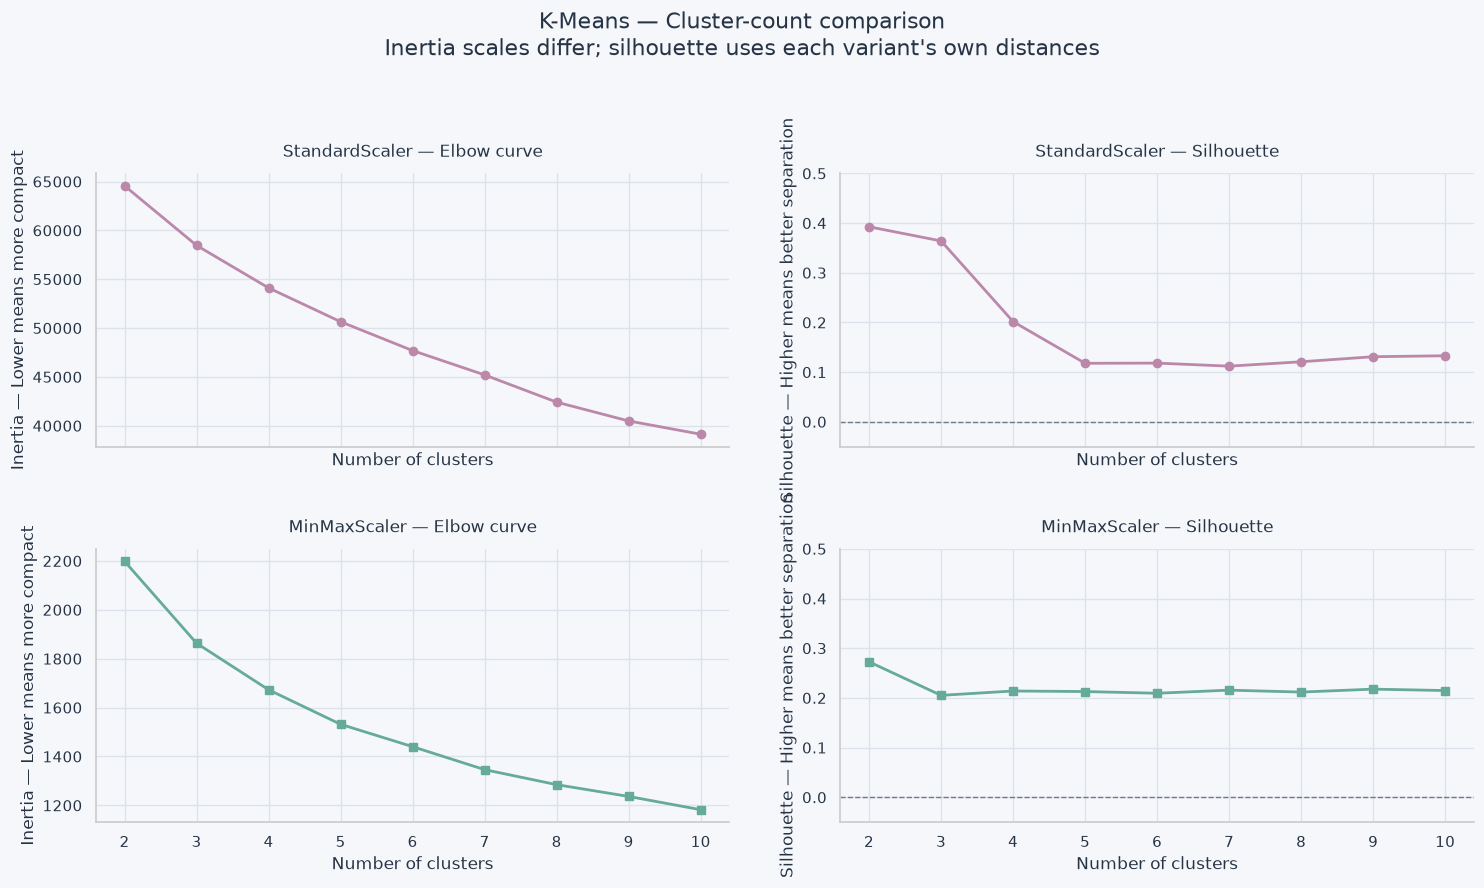

In [29]:
# visualise inertia and silhouette for both scaling variants
# inertia und silhouette für beide skalierungen darstellen

scaling_colors = {
    "StandardScaler": COLORS["lavender"],
    "MinMaxScaler": COLORS["mint"],
}

scaling_markers = {
    "StandardScaler": "o",
    "MinMaxScaler": "s",
}

fig, axes = plt.subplots(
    2,
    2,
    figsize=(15, 9),
    sharex=True,
)

for row, scaling_name in enumerate(scaling_colors):
    results = (
        kmeans_comparison.loc[
            kmeans_comparison["Scaling"].eq(scaling_name)
        ]
        .sort_values("Clusters")
    )

    color = scaling_colors[scaling_name]
    marker = scaling_markers[scaling_name]

    axes[row, 0].plot(
        results["Clusters"],
        results["Inertia"],
        color=color,
        marker=marker,
        linewidth=2,
    )

    axes[row, 0].set_title(
        f"{scaling_name} — Elbow curve",
        pad=12,
    )
    axes[row, 0].set_ylabel("Inertia — Lower means more compact")
    axes[row, 0].ticklabel_format(
        axis="y",
        style="plain",
        useOffset=False,
    )

    axes[row, 1].plot(
        results["Clusters"],
        results["Silhouette"],
        color=color,
        marker=marker,
        linewidth=2,
    )

    axes[row, 1].set_title(
        f"{scaling_name} — Silhouette",
        pad=12,
    )
    axes[row, 1].set_ylabel("Silhouette — Higher means better separation")

    # identical silhouette axes support visual comparison
    axes[row, 1].set_ylim(-0.05, 0.5)
    axes[row, 1].axhline(
        0,
        color=COLORS["text"],
        linestyle="--",
        linewidth=1,
        alpha=0.6,
    )

for ax in axes.flat:
    ax.set_xlabel("Number of clusters")
    ax.set_xticks(range(2, 11))
    ax.set_axisbelow(True)

fig.suptitle(
    "K-Means — Cluster-count comparison\n"
    "Inertia scales differ; silhouette uses each variant's own distances",
    fontsize=16,
)

fig.tight_layout(rect=[0, 0, 1, 0.93], h_pad=3, w_pad=3)
plt.show()

#### Initial findings and next investigation
#### Erste Ergebnisse und nächste Untersuchung

Neither scaling variant shows an unambiguous elbow.
For StandardScaler, silhouette decreases only slightly from two to three
clusters (0.393 to 0.364), then drops substantially at four clusters (0.202).
For MinMaxScaler, scores change little from three clusters onward.

We therefore examine the StandardScaler solutions with two and three
clusters together:

- Two clusters: identify the main distinction between the 368 users
  in the smaller group and the other 5,074.
- Three clusters: examine which additional distinctions emerge and
  whether they provide meaningful information.

Compare feature profiles in original units and check the booking context.
The three-cluster solution is fitted independently; it does not necessarily
just split one of the existing groups.

This is a diagnostic comparison, not a final model selection.
A small or specialised group is not automatically unsuitable.
The MinMax solutions remain part of the subsequent comparison.

---

Keine der beiden Skalierungsvarianten zeigt einen eindeutigen Ellenbogen.
Bei StandardScaler sinkt die Silhouette von zwei auf drei Cluster nur
leicht (0,393 auf 0,364), fällt bei vier Clustern jedoch deutlich auf 0,202.
Bei MinMaxScaler verändern sich die Werte ab drei Clustern nur wenig.

Deshalb untersuchen wir die StandardScaler-Lösungen mit zwei und drei
Clustern gemeinsam:

- Zwei Cluster: die grundlegende Trennung zwischen den 368 Nutzern
  der kleineren Gruppe und den übrigen 5.074 verstehen.
- Drei Cluster: prüfen, welche zusätzlichen Unterschiede entstehen
  und ob diese fachlich hilfreiche Informationen liefern.

Die Merkmalsprofile in ursprünglichen Einheiten vergleichen und den
Buchungskontext prüfen. Die Dreierlösung wird unabhängig berechnet;
sie teilt nicht zwangsläufig nur eine der bisherigen Gruppen auf.

Dies ist ein diagnostischer Vergleich, keine endgültige Modellauswahl.
Eine kleine oder spezialisierte Gruppe ist nicht automatisch ungeeignet.
Die MinMax-Lösungen bleiben Bestandteil des anschließenden Vergleichs.

### 4.3 Compare the two- and three-cluster profiles
### 4.3 Profile der Zweier- und Dreierlösung vergleichen

Inspect the existing StandardScaler solutions with two and three clusters.

First, show group sizes and the number of users without flight or hotel
bookings without a recorded cancellation. Then compare the mean feature
values in original units, including the documented ML estimates.

This helps explain the main separation and the additional distinctions
in the three-cluster solution. Group averages describe tendencies,
not characteristics shared by every member.

Cluster numbers are arbitrary identifiers. Cluster 1 in one solution
does not automatically correspond to Cluster 1 in the other.
No final solution or customer benefit is assigned.

Die vorhandenen StandardScaler-Lösungen mit zwei und drei Clustern
untersuchen.

Zunächst Gruppengrößen sowie Nutzer ohne Flug- beziehungsweise
Hotelbuchungen ohne verzeichnete Stornierung anzeigen. Anschließend
die durchschnittlichen Merkmalswerte in ursprünglichen Einheiten
vergleichen, einschließlich der dokumentierten ML-Schätzwerte.

So erklären wir die grundlegende Trennung und die zusätzlichen
Unterschiede der Dreierlösung. Gruppendurchschnitte beschreiben
Tendenzen, keine Eigenschaften jedes einzelnen Gruppenmitglieds.

Clusternummern sind beliebige Kennungen. Cluster 1 der einen Lösung
entspricht nicht automatisch Cluster 1 der anderen.
Noch keine endgültige Lösung oder Kundenvorteile zuweisen.

In [30]:
# inspect existing cluster assignments in original feature units
# vorhandene clusterzuordnungen in ursprünglichen einheiten betrachten

# add combined bookings for interpretation only
# kombinierte buchungen ausschließlich für die interpretation ergänzen

profile_display_data = ml_work.copy()

profile_display_data["flight_hotel_trip_share_pct"] = (
    100
    - profile_display_data["flight_only_trip_share_pct"]
    - profile_display_data["hotel_only_trip_share_pct"]
)

combined_share = profile_display_data["flight_hotel_trip_share_pct"]

if not combined_share.between(-1e-8, 100 + 1e-8).all():
    raise ValueError("Invalid combined-booking shares.")

profile_display_labels = {
    **ML_FEATURE_LABELS,
    "flight_hotel_trip_share_pct": "Flight and hotel trips (%)",
}

# place the new row directly after hotel-only trips
profile_feature_order = list(ml_work.columns)
profile_feature_order.insert(
    profile_feature_order.index("hotel_only_trip_share_pct") + 1,
    "flight_hotel_trip_share_pct",
)

profile_display_data = profile_display_data[profile_feature_order]

profile_tables = {}
context_tables = []

for k in [2, 3]:
    labels = kmeans_labels[("StandardScaler", k)].reindex(
        ml_work.index
    )

    if labels.isna().any():
        raise ValueError("Cluster assignments missing for some users.")

    # display cluster numbers starting at 1
    # underlying model labels remain unchanged
    display_clusters = (labels + 1).astype(int).rename("Cluster")

    # means in original units, including the agreed ML estimates
    means = (
        profile_display_data.groupby(display_clusters)
        .mean()
        .T
)

    group_sizes = display_clusters.value_counts().sort_index()

    means.columns = [
        f"Cluster {cluster} — {group_sizes.loc[cluster]:,} users"
        for cluster in means.columns
    ]

    means.index = [
        profile_display_labels[feature]
        for feature in means.index
]

    profile_tables[k] = (
        means.rename_axis("Feature")
        .reset_index()
    )

    # check whether absent bookings help explain the separation
    context = profile_booking_counts.reindex(ml_work.index).copy()

    if context.isna().any().any():
        raise ValueError("Booking context missing for some users.")

    context["Cluster"] = display_clusters
    context["No flight booking"] = context[
        "profile_flight_count"
    ].eq(0)
    context["No hotel booking"] = context[
        "profile_hotel_count"
    ].eq(0)

    summary = (
        context.groupby("Cluster")
        .agg(
            **{
                "Users": ("Cluster", "size"),
                "Users without a flight booking": (
                    "No flight booking", "sum"
                ),
                "Users without a hotel booking": (
                    "No hotel booking", "sum"
                ),
            }
        )
        .reset_index()
    )

    summary.insert(0, "Solution — Clusters", k)

    if summary["Users"].sum() != len(ml_work):
        raise ValueError("User counts do not reconcile.")

    context_tables.append(summary)

cluster_booking_context = pd.concat(
    context_tables,
    ignore_index=True,
)

display(style_overview(
    cluster_booking_context,
    "StandardScaler — Group sizes and bookings without cancellation",
    {
        column: "{:,.0f}"
        for column in cluster_booking_context.columns
    },
))

# show both sets of original-unit profiles side by side
profile_html = []

for k in [2, 3]:
    table = profile_tables[k]

    formats = {
        column: "{:,.2f}"
        for column in table.columns
        if column != "Feature"
    }

    profile_html.append(
        '<div style="overflow-x:auto;">'
        + style_overview(
            table,
            f"StandardScaler — {k} clusters — Mean feature values",
            formats,
        ).to_html()
        + "</div>"
    )

display(HTML(
    '<div style="display:flex; gap:32px; '
    'align-items:flex-start; flex-wrap:wrap;">'
    + "".join(profile_html)
    + "</div>"
))

print("Existing models inspected; no models refitted.")
print("No final clustering solution selected.")

Solution — Clusters,Cluster,Users,Users without a flight booking,Users without a hotel booking
2,1,368,364,0
2,2,"5,074",33,106
3,1,"4,558",0,78
3,2,366,364,0
3,3,518,33,28


Feature,Cluster 1 — 368 users,"Cluster 2 — 5,074 users"
Recorded trips,1.30,3.06
Trips with a recorded cancellation (%),1.63,3.21
Flight-only trips (%),0.32,11.64
Hotel-only trips (%),98.73,11.65
Flight and hotel trips (%),0.95,76.71
Flight bookings with a discount (%),0.54,15.01
Hotel bookings with a discount (%),20.61,13.02
Flight bookings with checked baggage (%),0.00,51.06
Average nights per hotel booking,8.01,4.02
Average days between departure and return,0.02,4.10


Existing models inspected; no models refitted.
No final clustering solution selected.


#### Behavioural clusters and customer benefits
#### Verhaltenscluster und Kundenvorteile

The current results do not establish whether five benefit-oriented
segments are suitable. The five-cluster solutions have not yet been
examined in detail.

K-Means groups users by feature similarity; it does not know the five
proposed benefits. Five clusters therefore do not automatically correspond
to five benefit preferences.

First understand the behavioural groups. Then assess benefit recommendations
using their profiles and additional user characteristics.
Several groups may receive the same benefit, while users within one group
may receive different recommendations.

The five-cluster solutions remain part of the investigation.
No final decision on cluster count or benefit assignment has been made.

---

Die bisherigen Ergebnisse entscheiden noch nicht, ob fünf an den
Kundenvorteilen orientierte Segmente geeignet sind. Die Fünferlösungen
wurden noch nicht im Detail untersucht.

K-Means gruppiert Nutzer nach ähnlichen Merkmalen; die fünf vorgeschlagenen
Vorteile kennt das Verfahren nicht. Fünf Cluster entsprechen deshalb
nicht automatisch fünf unterschiedlichen Vorteilspräferenzen.

Zunächst die Verhaltensgruppen verstehen. Anschließend anhand ihrer
Profile und zusätzlicher Nutzereigenschaften passende Vorteile empfehlen.
Mehrere Gruppen können denselben Vorteil erhalten; innerhalb einer Gruppe
können unterschiedliche Empfehlungen sinnvoll sein.

Die Fünferlösungen bleiben Bestandteil der Untersuchung.
Clusterzahl und Vorteilszuordnung sind noch nicht endgültig festgelegt.

### 4.4 Compare cluster means and medians
### 4.4 Durchschnitt und Median der Cluster vergleichen

For the three-cluster StandardScaler solution, compare means and medians
of selected features in original units.

The mean includes the size of every value. The median is the middle value
when users are sorted by the feature. A large difference can indicate
that a minority of high values raises the mean.

Include the documented zero codings and ML estimates.
Booking-type and cancellation percentages are user-level percentages,
not pooled percentages across all bookings in a cluster.

Für die StandardScaler-Dreierlösung Durchschnitt und Median ausgewählter
Merkmale in ursprünglichen Einheiten vergleichen.

Der Durchschnitt berücksichtigt die Höhe aller Werte. Der Median ist
der mittlere Wert, wenn die Nutzer nach dem Merkmal sortiert werden.
Ein großer Unterschied kann darauf hinweisen, dass wenige hohe Werte
den Durchschnitt anheben.

Die dokumentierten Null-Codierungen und ML-Schätzwerte bleiben enthalten.
Buchungsarten und Stornierungsanteile sind persönliche Nutzeranteile,
keine zusammengefassten Anteile aller Buchungen eines Clusters.

In [31]:
# inspect typical values in the existing three-cluster solution
# typische werte der vorhandenen dreierlösung untersuchen

labels_three = kmeans_labels[
    ("StandardScaler", 3)
].reindex(profile_display_data.index)

if labels_three.isna().any():
    raise ValueError("Cluster assignments missing.")

review_clusters = (labels_three + 1).astype(int)

selected_review_features = [
    "flight_hotel_trip_share_pct",
    "cancelled_trip_share_pct",
    "avg_flight_booking_lead_days",
    "avg_hotel_booking_lead_days",
    "avg_hotel_nights",
    "avg_travel_days",
    "avg_flight_distance_km",
    "avg_trip_booking_value_usd",
]

mean_median_comparison = pd.DataFrame({
    "Feature": [
        profile_display_labels[feature]
        for feature in selected_review_features
    ]
})

for cluster in sorted(review_clusters.unique()):
    group = profile_display_data.loc[
        review_clusters.eq(cluster),
        selected_review_features,
    ]

    mean_median_comparison[
        f"Cluster {cluster} — Mean"
    ] = group.mean().reindex(
        selected_review_features
    ).to_numpy()

    mean_median_comparison[
        f"Cluster {cluster} — Median"
    ] = group.median().reindex(
        selected_review_features
    ).to_numpy()

display(HTML(
    '<div style="overflow-x:auto;">'
    + style_overview(
        mean_median_comparison,
        "StandardScaler — 3 clusters — Means and medians",
        {
            column: "{:,.2f}"
            for column in mean_median_comparison.columns
            if column != "Feature"
        },
    ).to_html()
    + "</div>"
))

print("Existing cluster assignments used; no model refitted.")

Feature,Cluster 1 — Mean,Cluster 1 — Median,Cluster 2 — Mean,Cluster 2 — Median,Cluster 3 — Mean,Cluster 3 — Median
Flight and hotel trips (%),78.24,83.33,0.73,0.00,63.11,66.67
Trips with a recorded cancellation (%),0.74,0.00,1.50,0.00,24.97,33.33
Average days from booking to departure,8.33,7.67,0.19,0.00,97.00,87.25
Average days from booking to check-in,7.80,7.67,9.01,7.00,38.29,9.00
Average nights per hotel booking,3.92,3.50,7.95,7.00,4.94,4.29
Average days between departure and return,3.92,3.50,0.02,0.00,5.68,5.00
Average one-way flight distance (km),"2,063.02","1,984.43",3.76,0.00,"3,019.42","2,392.44"
Average estimated booking value (USD),"1,124.90",963.47,"1,891.71","1,284.00","1,684.10","1,259.60"


Existing cluster assignments used; no model refitted.


### 4.5 Visualise distributions within clusters
### 4.5 Verteilungen innerhalb der Cluster darstellen

Compare flight and hotel booking lead times, cancellation shares and
hotel nights across the three StandardScaler clusters.

Use original-unit values, including the documented zero codings and
ML estimates. Boxen plots show the median and successive quantile ranges.
They reveal variation and overlap hidden by group averages.

For Cluster 2, flight-related zeros mostly represent absent flight bookings,
not exceptionally short booking lead times.

Flug- und Hotelbuchungsvorlauf, Stornierungsanteile und Hotelnächte
zwischen den drei StandardScaler-Clustern vergleichen.

Werte in ursprünglichen Einheiten einschließlich der dokumentierten
Null-Codierungen und ML-Schätzwerte verwenden. Boxenplots zeigen Median
und aufeinanderfolgende Quantilbereiche. Sie machen Streuung und
Überschneidungen sichtbar, die Gruppendurchschnitte verdecken.

Bei Cluster 2 stehen flugbezogene Nullwerte überwiegend für fehlende
Flugbuchungen, nicht für besonders kurzfristige Buchungen.

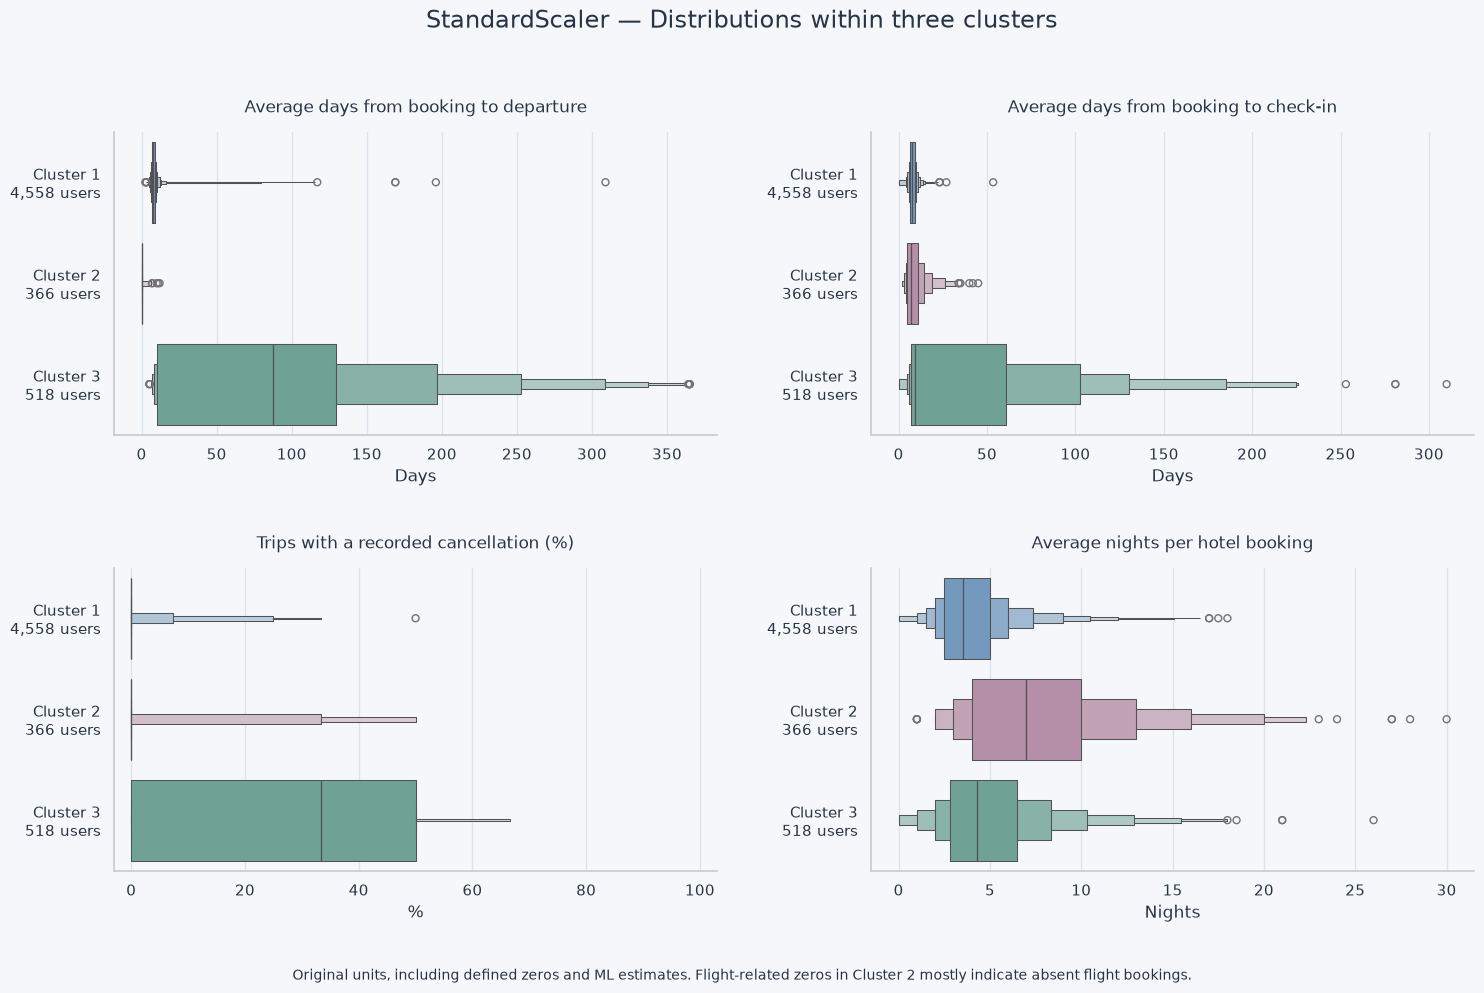

In [32]:
# show distributions within the existing three clusters
# verteilungen innerhalb der vorhandenen drei cluster zeigen

cluster_visual_data = profile_display_data.copy()

cluster_visual_data["Cluster"] = (
    labels_three.reindex(cluster_visual_data.index) + 1
).astype(int)

cluster_order = [1, 2, 3]

cluster_colors = {
    1: COLORS["blue"],
    2: COLORS["lavender"],
    3: COLORS["mint"],
}

cluster_sizes = (
    cluster_visual_data["Cluster"]
    .value_counts()
    .reindex(cluster_order)
)

visual_features = [
    "avg_flight_booking_lead_days",
    "avg_hotel_booking_lead_days",
    "cancelled_trip_share_pct",
    "avg_hotel_nights",
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(15, 10),
)

for ax, feature in zip(axes.flat, visual_features):
    sns.boxenplot(
        data=cluster_visual_data,
        x=feature,
        y="Cluster",
        hue="Cluster",
        order=cluster_order,
        hue_order=cluster_order,
        palette=cluster_colors,
        orient="h",
        dodge=False,
        legend=False,
        ax=ax,
    )

    ax.set_title(
        fill(ML_FEATURE_LABELS[feature], width=46),
        pad=14,
    )
    ax.set_xlabel(feature_units[feature])
    ax.set_ylabel("")

    ax.set_yticks(range(len(cluster_order)))
    ax.set_yticklabels([
        f"Cluster {cluster}\n{cluster_sizes.loc[cluster]:,} users"
        for cluster in cluster_order
    ])

    if feature.endswith("_pct"):
        ax.set_xlim(-3, 103)

    ax.set_axisbelow(True)
    ax.grid(axis="y", visible=False)

fig.suptitle(
    "StandardScaler — Distributions within three clusters",
    fontsize=17,
)

fig.text(
    0.5,
    0.01,
    "Original units, including defined zeros and ML estimates. "
    "Flight-related zeros in Cluster 2 mostly indicate absent flight bookings.",
    ha="center",
    fontsize=10,
)

fig.tight_layout(
    rect=[0, 0.05, 1, 0.95],
    h_pad=3,
    w_pad=3,
)

plt.show()

#### Cluster distributions — Interpretation
#### Clusterverteilungen — Einordnung

The three clusters differ in several features, but are not completely
separated in every individual feature.

- Cluster 3 has a substantially higher typical flight booking lead time.
- Hotel booking lead-time medians are similar across clusters, while
  Cluster 3 has a much longer right tail.
- Cluster 2 tends to have longer hotel stays, although the central
  night-count ranges overlap.
- Cluster 3 has higher cancellation shares overall, but also includes
  users without recorded cancellations.

Overlapping value ranges do not mean that users belong to several clusters.
Each user has exactly one assignment within this solution.
Box widths represent value ranges, not group sizes.

Boxen plots do not directly quantify how many users share similar values
across clusters. ECDF curves will provide a complementary view.

---

Die drei Cluster unterscheiden sich in mehreren Merkmalen, sind aber
nicht bei jedem einzelnen Merkmal vollständig getrennt.

- Cluster 3 hat einen deutlich höheren typischen Flugbuchungsvorlauf.
- Die Mediane des Hotelbuchungsvorlaufs liegen nah beieinander;
  Cluster 3 besitzt jedoch einen wesentlich längeren rechten Ausläufer.
- Cluster 2 weist tendenziell längere Hotelaufenthalte auf, wobei sich
  die zentralen Nächtebereiche überschneiden.
- Cluster 3 hat insgesamt höhere Stornierungsanteile, enthält aber
  ebenfalls Nutzer ohne verzeichnete Stornierung.

Überlappende Wertebereiche bedeuten keine mehrfachen Clusterzuordnungen.
Jeder Nutzer gehört innerhalb dieser Lösung genau einem Cluster an.
Die Boxbreiten zeigen Wertebereiche, keine Gruppengrößen.

Boxenplots beziffern nicht unmittelbar, wie viele Nutzer verschiedener
Cluster ähnliche Werte haben. ECDF-Kurven ergänzen diese Betrachtung.

### 4.6 Compare cumulative distributions
### 4.6 Kumulative Verteilungen vergleichen

ECDF curves show the percentage of users whose feature value is less than
or equal to the value on the x-axis. Each cluster reaches 100%, regardless
of its size.

Nearby curves indicate similar distributions at those values.
Vertical gaps show differences in cumulative percentages.
A curve rising further to the right generally indicates larger values.

Show full distributions and additional zoomed views for booking lead times.
Zooming changes only the visible axis range; no users are excluded.

ECDF-Kurven zeigen den Anteil der Nutzer, deren Merkmalswert kleiner
oder gleich dem Wert auf der x-Achse ist. Jedes Cluster erreicht
unabhängig von seiner Größe 100%.

Nahe beieinanderliegende Kurven zeigen an diesen Stellen ähnliche
Verteilungen. Vertikale Abstände zeigen Unterschiede der kumulierten
Prozentanteile. Eine weiter rechts ansteigende Kurve weist grundsätzlich
auf höhere Werte hin.

Vollständige Verteilungen und ergänzende Ausschnitte des Buchungsvorlaufs
zeigen. Die Vergrößerung verändert nur den sichtbaren Achsenbereich;
es werden keine Nutzer ausgeschlossen.

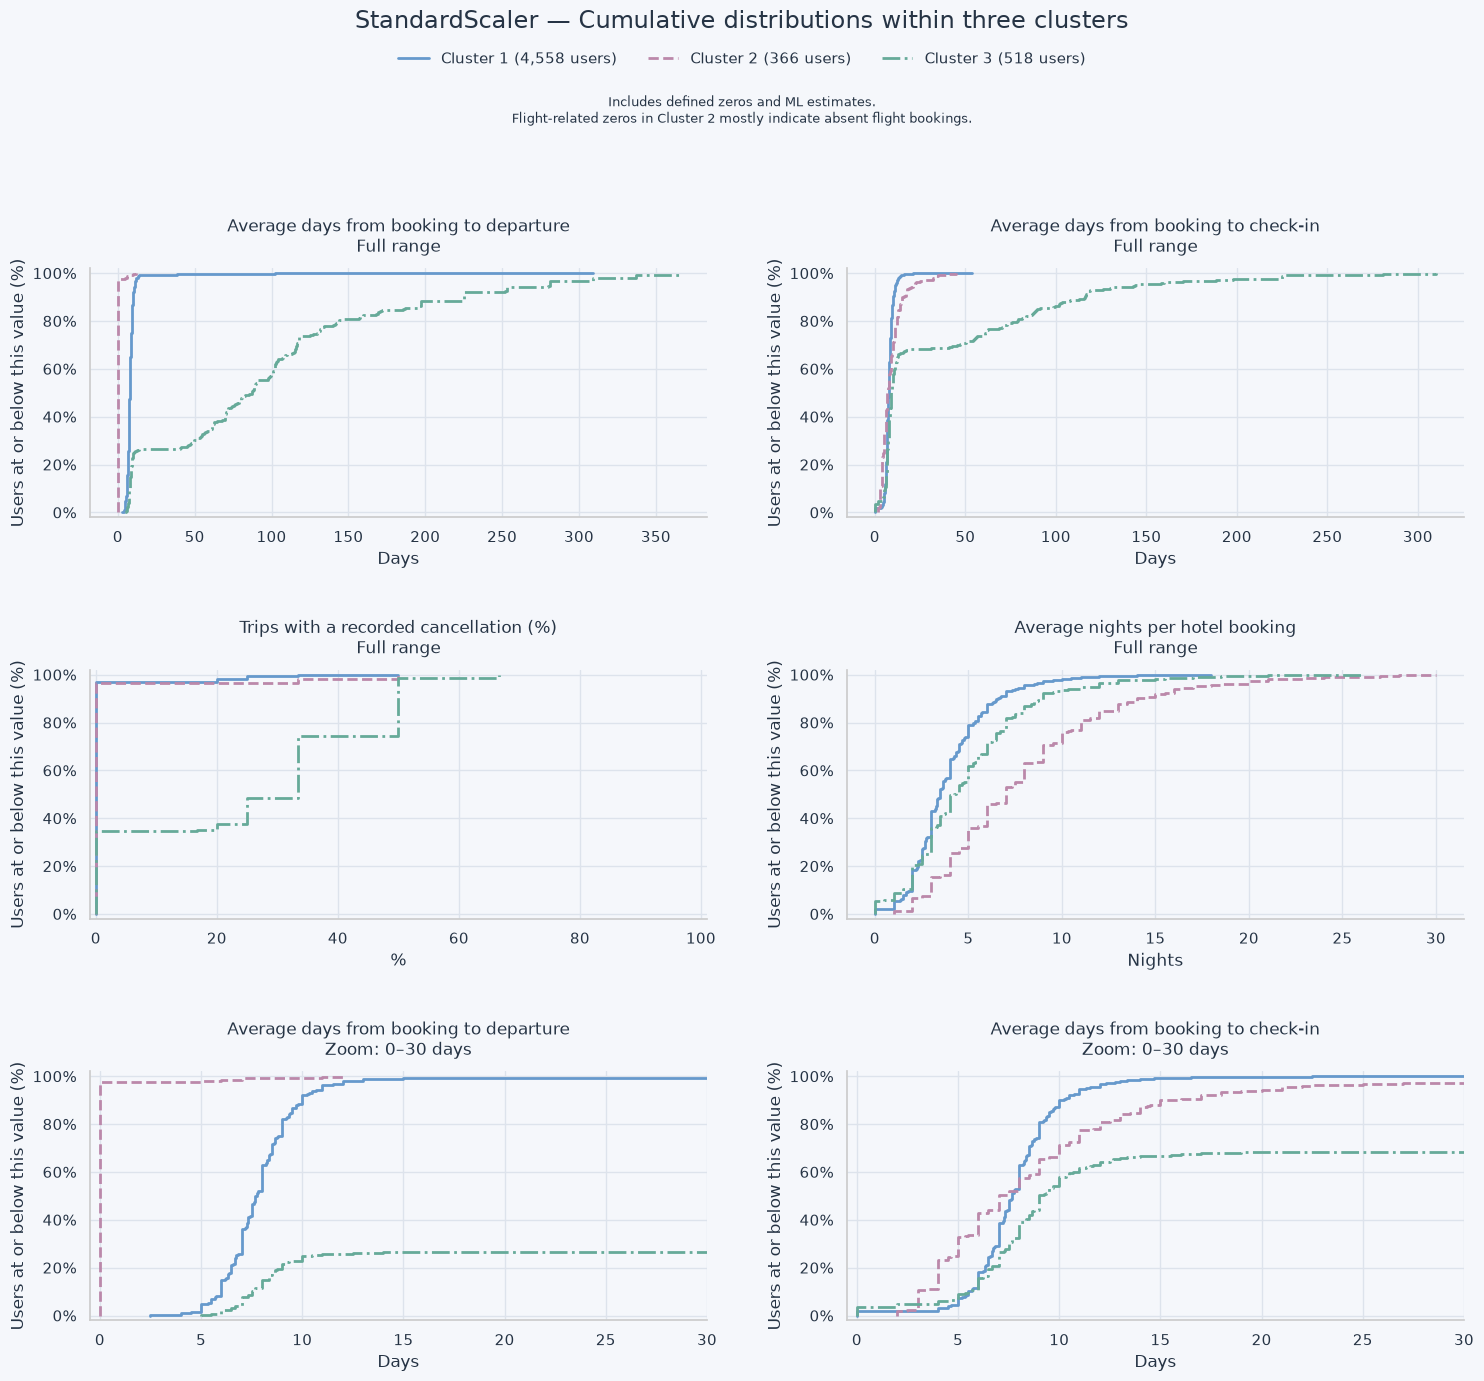

In [33]:
# compare cumulative percentages rather than absolute group counts
# kumulierte prozentanteile statt absoluter gruppengrößen vergleichen

from matplotlib.ticker import PercentFormatter

ecdf_panels = [
    ("avg_flight_booking_lead_days", None, "Full range"),
    ("avg_hotel_booking_lead_days", None, "Full range"),
    ("cancelled_trip_share_pct", (-1, 101), "Full range"),
    ("avg_hotel_nights", None, "Full range"),
    ("avg_flight_booking_lead_days", (-0.5, 30), "Zoom: 0–30 days"),
    ("avg_hotel_booking_lead_days", (-0.5, 30), "Zoom: 0–30 days"),
]

fig, axes = plt.subplots(
    3,
    2,
    figsize=(15, 14),
)

line_styles = {
    1: "-",
    2: "--",
    3: "-.",
}

for ax, (feature, limits, subtitle) in zip(
    axes.flat,
    ecdf_panels,
):
    for cluster in cluster_order:
        values = np.sort(
            cluster_visual_data.loc[
                cluster_visual_data["Cluster"].eq(cluster),
                feature,
            ].to_numpy(dtype=float)
        )

        # calculate the cumulative share at each distinct value
        distinct_values, counts = np.unique(
            values,
            return_counts=True,
        )
        cumulative_share = counts.cumsum() / len(values)

        # add a starting point to display jumps at the minimum
        plot_x = np.r_[distinct_values[0], distinct_values]
        plot_y = np.r_[0.0, cumulative_share]

        ax.step(
            plot_x,
            plot_y,
            where="post",
            color=cluster_colors[cluster],
            linestyle=line_styles[cluster],
            linewidth=2,
            label=(
                f"Cluster {cluster} "
                f"({cluster_sizes.loc[cluster]:,} users)"
            ),
        )

    ax.set_title(
        fill(ML_FEATURE_LABELS[feature], width=46)
        + "\n"
        + subtitle,
        pad=12,
    )
    ax.set_xlabel(feature_units[feature])
    ax.set_ylabel("Users at or below this value (%)")
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.set_ylim(-0.02, 1.02)

    if limits is not None:
        ax.set_xlim(*limits)

    ax.set_axisbelow(True)

handles, legend_labels = axes[0, 0].get_legend_handles_labels()

fig.suptitle(
    "StandardScaler — Cumulative distributions within three clusters",
    fontsize=17,
    y=0.995,
)

fig.legend(
    handles,
    legend_labels,
    loc="upper center",
    ncol=3,
    frameon=False,
    bbox_to_anchor=(0.5, 0.975),
)

fig.text(
    0.5,
    0.935,
    "Includes defined zeros and ML estimates.\n"
    "Flight-related zeros in Cluster 2 mostly indicate absent flight bookings.",
    ha="center",
    va="top",
    fontsize=9,
)

fig.tight_layout(
    rect=[0, 0.01, 1, 0.89],
    h_pad=3,
    w_pad=3,
)

plt.show()

#### ECDF comparison — Findings
#### ECDF-Vergleich — Ergebnisse

The cumulative distributions clarify the differences between the clusters:

- Cluster 3 has substantially longer flight booking lead times.
  Approximately three quarters of its users have personal averages
  above 30 days.
- Hotel booking lead-time medians are similar across clusters.
  However, Cluster 3 contains a larger share of users with long lead times.
- Most users in Clusters 1 and 2 have no recorded cancellations.
  Cluster 3 has a considerably larger share of users with cancellations.
- Cluster 2 tends to have longer hotel stays, although the night-count
  distributions overlap.

Flight-related zeros in Cluster 2 mostly indicate absent flight bookings.
They must not be interpreted as same-day flight bookings.

These are differences between distributions, not completely separate
value ranges. Each user belongs to exactly one cluster in this solution.
The profiles include the documented zero codings and ML estimates.
No final clustering solution or benefit assignment has been selected.

---

Die kumulierten Verteilungen verdeutlichen die Unterschiede zwischen
den Clustern:

- Cluster 3 hat deutlich längere Flugbuchungsvorläufe.
  Ungefähr drei Viertel seiner Nutzer haben persönliche Durchschnitte
  von mehr als 30 Tagen.
- Die Mediane des Hotelbuchungsvorlaufs liegen nah beieinander.
  Cluster 3 enthält jedoch einen größeren Anteil mit langen Vorlaufzeiten.
- Die meisten Nutzer in Cluster 1 und 2 haben keine verzeichnete Stornierung.
  In Cluster 3 ist der Anteil der Nutzer mit Stornierungen deutlich größer.
- Cluster 2 weist tendenziell längere Hotelaufenthalte auf.
  Die Nächteverteilungen überschneiden sich dennoch.

Flugbezogene Nullwerte in Cluster 2 stehen überwiegend für fehlende
Flugbuchungen. Sie dürfen nicht als Flugbuchungen am Abflugtag
interpretiert werden.

Dies sind Unterschiede zwischen Verteilungen, keine vollständig getrennten
Wertebereiche. Jeder Nutzer gehört innerhalb dieser Lösung genau einem
Cluster an. Die Profile enthalten die dokumentierten Null-Codierungen
und ML-Schätzwerte. Eine endgültige Clusterlösung oder Vorteilszuordnung
wurde noch nicht ausgewählt.

### 4.7 Check stability across random seeds
### 4.7 Stabilität bei unterschiedlichen Zufallsstarts prüfen

Repeat the StandardScaler solutions with two and three clusters using
random_state values 0, 1, 7, 21 and 84. Keep the data and all other
settings unchanged, including 20 initialisations per model.

Compare each result with the initial solution using random_state=42.
Use the Adjusted Rand Index (ARI), which compares group membership
independently of cluster numbering.

ARI=1 indicates identical groupings; values near zero indicate
chance-level agreement. ARI is not a percentage of correctly assigned users.

This checks sensitivity to random initialisation on the same data.
It does not establish stability under different datasets or prove
that the groups are suitable for benefit recommendations.
Preserve the initial models and assignments.

Die StandardScaler-Lösungen mit zwei und drei Clustern mit den
random_state-Werten 0, 1, 7, 21 und 84 wiederholen. Daten und alle anderen
Einstellungen bleiben unverändert, einschließlich der
20 Initialisierungen je Modell.

Jedes Ergebnis mit der ursprünglichen Lösung mit random_state=42
vergleichen. Dafür den Adjusted Rand Index (ARI) verwenden, der
Gruppenzugehörigkeiten unabhängig von den Clusternummern vergleicht.

ARI=1 bedeutet identische Gruppierungen; Werte nahe null entsprechen
ungefähr zufällig erwartbarer Übereinstimmung. ARI ist kein Prozentsatz
korrekt zugeordneter Nutzer.

Die Prüfung untersucht die Abhängigkeit von zufälligen Startzentren
bei denselben Daten. Sie bestätigt weder Stabilität bei anderen
Datensätzen noch die Eignung für Vorteilsempfehlungen.
Die ursprünglichen Modelle und Zuordnungen bleiben erhalten.

In [34]:
# test random-start stability without replacing the initial models
# stabilität prüfen, ohne die ursprünglichen modelle zu ersetzen

from sklearn.metrics import adjusted_rand_score

stability_seeds = [0, 1, 7, 21, 84]

stability_models = {}
stability_labels = {}
stability_rows = []

for k in [2, 3]:
    reference_model = kmeans_models[("StandardScaler", k)]
    reference_labels = kmeans_labels[("StandardScaler", k)]

    if not reference_labels.index.equals(ml_scaled.index):
        raise ValueError("User order differs from the reference model.")

    for seed in stability_seeds:
        # retain all settings except the random seed
        settings = reference_model.get_params().copy()
        settings["random_state"] = seed

        model = KMeans(**settings)
        labels = model.fit_predict(ml_scaled)

        group_sizes = pd.Series(labels).value_counts()

        if len(group_sizes) != k:
            raise ValueError("Fewer clusters than requested.")

        if model.n_iter_ >= model.max_iter:
            raise ValueError("Iteration limit reached.")

        agreement = adjusted_rand_score(
            reference_labels.to_numpy(),
            labels,
        )

        stability_models[(k, seed)] = model
        stability_labels[(k, seed)] = pd.Series(
            labels,
            index=ml_scaled.index,
            name="cluster",
        )

        stability_rows.append({
            "Clusters": k,
            "Random seed": seed,
            "Agreement with initial solution — ARI": agreement,
            "Inertia": model.inertia_,
            "Smallest group": int(group_sizes.min()),
            "Largest group": int(group_sizes.max()),
        })

    print(f"{k} clusters: five additional random seeds checked.")

stability_results = pd.DataFrame(stability_rows)

display(style_overview(
    stability_results,
    "StandardScaler — Random-start stability",
    {
        "Clusters": "{:.0f}",
        "Random seed": "{:.0f}",
        "Agreement with initial solution — ARI": "{:.4f}",
        "Inertia": "{:,.2f}",
        "Smallest group": "{:,.0f}",
        "Largest group": "{:,.0f}",
    },
))

print("Initial models and assignments remain unchanged.")

2 clusters: five additional random seeds checked.
3 clusters: five additional random seeds checked.


Clusters,Random seed,Agreement with initial solution — ARI,Inertia,Smallest group,Largest group
2,0,1.0000,"64,563.51",368,"5,074"
2,1,1.0000,"64,563.51",368,"5,074"
2,7,1.0000,"64,563.51",368,"5,074"
2,21,1.0000,"64,563.51",368,"5,074"
2,84,1.0000,"64,563.51",368,"5,074"
3,0,1.0000,"58,461.83",366,"4,558"
3,1,1.0000,"58,461.83",366,"4,558"
3,7,1.0000,"58,461.83",366,"4,558"
3,21,1.0000,"58,461.83",366,"4,558"
3,84,1.0000,"58,461.83",366,"4,558"


Initial models and assignments remain unchanged.


#### Random-start stability — Findings
#### Stabilität gegenüber Zufallsstarts — Ergebnis

Both StandardScaler solutions reproduce the initial groupings across
all five additional random seeds: every displayed ARI is 1.0000.
Inertia and group sizes also remain unchanged at the reported precision.

The two- and three-cluster solutions are therefore stable under the
tested initialisation settings. This does not establish stability under
changed data or determine their suitability for benefit recommendations.

---

Beide StandardScaler-Lösungen reproduzieren bei allen fünf zusätzlichen
Zufallsstartwerten die ursprünglichen Gruppierungen: Jeder angezeigte
ARI beträgt 1,0000. Auch Inertia und Gruppengrößen bleiben in der
ausgegebenen Genauigkeit unverändert.

Die Zwei- und Dreierlösung sind damit unter den getesteten
Initialisierungsbedingungen stabil. Das bestätigt weder Stabilität
bei veränderten Daten noch ihre Eignung für Vorteilsempfehlungen.

### 4.8 Inspect the five-cluster MinMax solution
### 4.8 MinMax-Lösung mit fünf Clustern untersuchen

Inspect the existing five-cluster MinMax solution without refitting.
Compare group sizes, booking context and mean feature values in original
units, including documented zero codings and ML estimates.

Include the combined flight-and-hotel share for interpretation only.
The model still uses 14 features.

Five clusters do not automatically represent the five customer benefits.
Cluster identifiers are unrelated to those in the StandardScaler solutions.

Die vorhandene MinMax-Fünferlösung untersuchen, ohne sie neu zu berechnen.
Gruppengrößen, Buchungskontext und durchschnittliche Merkmalswerte
in ursprünglichen Einheiten vergleichen, einschließlich der dokumentierten
Null-Codierungen und ML-Schätzwerte.

Den Anteil kombinierter Flug-und-Hotel-Buchungen nur zur Interpretation
ergänzen. Das Modell verwendet weiterhin 14 Merkmale.

Fünf Cluster entsprechen nicht automatisch den fünf Kundenvorteilen.
Die Clusternummern haben keinen Bezug zu denen der StandardScaler-Lösungen.

In [35]:
# inspect the existing five-cluster MinMax solution
# vorhandene MinMax-fünferlösung untersuchen

minmax_five_labels = kmeans_labels[
    ("MinMaxScaler", 5)
].reindex(profile_display_data.index)

if minmax_five_labels.isna().any():
    raise ValueError("Cluster assignments missing.")

minmax_five_clusters = (
    minmax_five_labels + 1
).astype(int).rename("Cluster")

# group sizes and booking context
minmax_context = profile_booking_counts.reindex(
    profile_display_data.index
).copy()

if minmax_context.isna().any().any():
    raise ValueError("Booking context missing.")

minmax_context["Cluster"] = minmax_five_clusters
minmax_context["No flight booking"] = (
    minmax_context["profile_flight_count"].eq(0)
)
minmax_context["No hotel booking"] = (
    minmax_context["profile_hotel_count"].eq(0)
)

minmax_five_context = (
    minmax_context.groupby("Cluster")
    .agg(
        **{
            "Users": ("Cluster", "size"),
            "Users without a flight booking": (
                "No flight booking", "sum"
            ),
            "Users without a hotel booking": (
                "No hotel booking", "sum"
            ),
        }
    )
    .reset_index()
)

minmax_five_context["Share of ML users (%)"] = (
    minmax_five_context["Users"]
    / len(profile_display_data)
    * 100
)

if minmax_five_context["Users"].sum() != len(ml_work):
    raise ValueError("User counts do not reconcile.")

display(style_overview(
    minmax_five_context,
    "MinMaxScaler — 5 clusters — Bookings without cancellation",
    {
        "Cluster": "{:.0f}",
        "Users": "{:,.0f}",
        "Users without a flight booking": "{:,.0f}",
        "Users without a hotel booking": "{:,.0f}",
        "Share of ML users (%)": "{:.1f}",
    },
))

# original-unit mean profiles; no transformations are reversed manually
minmax_five_means = (
    profile_display_data.groupby(minmax_five_clusters)
    .mean()
    .T
)

minmax_five_means.index = [
    profile_display_labels[feature]
    for feature in minmax_five_means.index
]

sizes = minmax_five_clusters.value_counts()

minmax_five_means.columns = [
    f"Cluster {cluster} — {sizes.loc[cluster]:,} users"
    for cluster in minmax_five_means.columns
]

minmax_five_profile = (
    minmax_five_means
    .rename_axis("Feature")
    .reset_index()
)

display(HTML(
    '<div style="overflow-x:auto;">'
    + style_overview(
        minmax_five_profile,
        "MinMaxScaler — 5 clusters — Mean feature values",
        {
            column: "{:,.2f}"
            for column in minmax_five_profile.columns
            if column != "Feature"
        },
    ).to_html()
    + "</div>"
))

print("Existing model inspected; no model refitted.")
print("Profiles use different booking bases as previously defined.")
print("No customer benefits assigned.")

Cluster,Users,Users without a flight booking,Users without a hotel booking,Share of ML users (%)
1,"2,443",0,4,44.9
2,513,6,15,9.4
3,"1,024",32,37,18.8
4,363,359,0,6.7
5,"1,099",0,50,20.2


Feature,"Cluster 1 — 2,443 users",Cluster 2 — 513 users,"Cluster 3 — 1,024 users",Cluster 4 — 363 users,"Cluster 5 — 1,099 users"
Recorded trips,3.79,2.48,2.35,1.30,2.36
Trips with a recorded cancellation (%),2.02,1.71,5.53,0.92,4.61
Flight-only trips (%),11.41,11.03,11.52,0.00,12.59
Hotel-only trips (%),7.16,14.90,15.94,99.49,16.27
Flight and hotel trips (%),81.43,74.06,72.54,0.51,71.14
Flight bookings with a discount (%),9.33,73.16,7.48,0.00,7.64
Hotel bookings with a discount (%),12.61,15.08,12.22,21.14,13.60
Flight bookings with checked baggage (%),50.75,49.13,0.00,0.00,100.00
Average nights per hotel booking,3.83,4.25,4.17,7.88,4.23
Average days between departure and return,4.07,4.18,3.98,0.02,4.24


Existing model inspected; no model refitted.
Profiles use different booking bases as previously defined.
No customer benefits assigned.


#### MinMax five-cluster solution — Initial findings
#### MinMax-Fünferlösung — Erste Ergebnisse

The five clusters highlight different booking patterns:

- Cluster 1 has the highest average number of recorded trips.
- Cluster 2 has a substantially higher share of flight bookings with discounts.
- Cluster 3 shows a checked-baggage share of 0% at the reported precision.
- Cluster 4 consists predominantly of hotel-only bookers with longer stays.
- Cluster 5 shows a checked-baggage share of 100% at the reported precision.

Compared with the StandardScaler three-cluster solution, this model
emphasises baggage usage and flight discounts more strongly.
These patterns provide possible starting points for benefit recommendations,
but do not prove preferences or the effectiveness of an offer.

The five clusters are not automatically assigned to five different benefits.
Check random-start stability before assessing the solution further.

---

Die fünf Cluster heben unterschiedliche Buchungsmuster hervor:

- Cluster 1 hat die höchste durchschnittliche Anzahl erfasster Reisen.
- Cluster 2 weist einen deutlich höheren Anteil rabattierter Flugbuchungen auf.
- Cluster 3 zeigt in der ausgegebenen Genauigkeit einen Gepäckanteil von 0%.
- Cluster 4 umfasst überwiegend reine Hotelbucher mit längeren Aufenthalten.
- Cluster 5 zeigt in der ausgegebenen Genauigkeit einen Gepäckanteil von 100%.

Im Vergleich zur StandardScaler-Dreierlösung betont dieses Modell
Gepäcknutzung und Flugrabatte stärker. Diese Muster liefern mögliche
Ansatzpunkte für Vorteilsempfehlungen, beweisen aber weder Präferenzen
noch die Wirksamkeit eines Angebots.

Die fünf Cluster werden nicht automatisch fünf verschiedenen Vorteilen
zugeordnet. Vor der weiteren Bewertung die Stabilität gegenüber
unterschiedlichen Zufallsstarts prüfen.

### 4.9 Check MinMax five-cluster stability
### 4.9 Stabilität der MinMax-Fünferlösung prüfen

Repeat the model with random_state values 0, 1, 7, 21 and 84.
Keep all other settings unchanged, including 20 initialisations.

Compare each grouping with the initial solution using random_state=42
and the Adjusted Rand Index (ARI). Preserve the initial model.

ARI measures agreement between groupings, not the percentage of
correctly assigned users. This tests random-start stability on the
same data, not stability under changes to the dataset.

Das Modell mit den random_state-Werten 0, 1, 7, 21 und 84 wiederholen.
Alle anderen Einstellungen einschließlich der 20 Initialisierungen
unverändert lassen.

Jede Gruppierung mithilfe des Adjusted Rand Index (ARI) mit der
ursprünglichen Lösung mit random_state=42 vergleichen.
Das ursprüngliche Modell erhalten.

ARI misst die Übereinstimmung zwischen Gruppierungen, keinen Prozentsatz
korrekt zugeordneter Nutzer. Geprüft wird die Stabilität gegenüber
Zufallsstarts bei denselben Daten, nicht bei verändertem Datensatz.

In [36]:
# test the MinMax five-cluster solution with different random seeds
# MinMax-fünferlösung mit unterschiedlichen zufallsstarts prüfen

reference_model = kmeans_models[("MinMaxScaler", 5)]
reference_labels = kmeans_labels[("MinMaxScaler", 5)]

if not reference_labels.index.equals(ml_minmax.index):
    raise ValueError("User order differs from the reference model.")

minmax_stability_models = {}
minmax_stability_labels = {}
minmax_stability_rows = []

for seed in [0, 1, 7, 21, 84]:
    settings = reference_model.get_params().copy()
    settings["random_state"] = seed

    model = KMeans(**settings)
    labels = model.fit_predict(ml_minmax)

    group_sizes = pd.Series(labels).value_counts()

    if len(group_sizes) != 5:
        raise ValueError("Expected five clusters.")

    if model.n_iter_ >= model.max_iter:
        raise ValueError("Iteration limit reached.")

    agreement = adjusted_rand_score(
        reference_labels.to_numpy(),
        labels,
    )

    minmax_stability_models[seed] = model
    minmax_stability_labels[seed] = pd.Series(
        labels,
        index=ml_minmax.index,
        name="cluster",
    )

    minmax_stability_rows.append({
        "Random seed": seed,
        "Agreement with initial solution — ARI": agreement,
        "Inertia": model.inertia_,
        "Smallest group": int(group_sizes.min()),
        "Largest group": int(group_sizes.max()),
    })

minmax_stability_results = pd.DataFrame(
    minmax_stability_rows
)

display(style_overview(
    minmax_stability_results,
    "MinMaxScaler — 5 clusters — Random-start stability",
    {
        "Random seed": "{:.0f}",
        "Agreement with initial solution — ARI": "{:.4f}",
        "Inertia": "{:,.2f}",
        "Smallest group": "{:,.0f}",
        "Largest group": "{:,.0f}",
    },
))

print("Five additional random seeds checked.")
print("Initial model and assignments remain unchanged.")

Random seed,Agreement with initial solution — ARI,Inertia,Smallest group,Largest group
0,1.0000,"1,531.66",363,"2,443"
1,1.0000,"1,531.66",363,"2,443"
7,1.0000,"1,531.66",363,"2,443"
21,1.0000,"1,531.66",363,"2,443"
84,1.0000,"1,531.66",363,"2,443"


Five additional random seeds checked.
Initial model and assignments remain unchanged.


### 4.10 Inspect the distinguishing MinMax features
### 4.10 Unterscheidende MinMax-Merkmale untersuchen

Compare cumulative distributions of flight discount usage, checked-baggage
usage, hotel-only trip shares and recorded trip counts across the five
MinMax clusters.

Check whether the differences in group averages also appear across
the user distributions. Each curve shows the percentage of users at
or below the feature value.

The features retain their previously defined booking bases.
Zero values may represent either absence of the relevant booking
or an observed booking without the characteristic.
No benefits are assigned at this stage.

Die kumulierten Verteilungen von Flugrabattnutzung, Gepäcknutzung,
Anteilen reiner Hotelreisen und erfassten Reiseanzahlen zwischen
den fünf MinMax-Clustern vergleichen.

Prüfen, ob die Unterschiede der Gruppendurchschnitte auch in den
Nutzerverteilungen sichtbar sind. Jede Kurve zeigt den Nutzeranteil
bei oder unter dem jeweiligen Merkmalswert.

Die zuvor definierten Buchungsgrundlagen bleiben bestehen.
Nullwerte können entweder für eine fehlende entsprechende Buchung
oder für eine vorhandene Buchung ohne das Merkmal stehen.
Noch keine Kundenvorteile zuweisen.

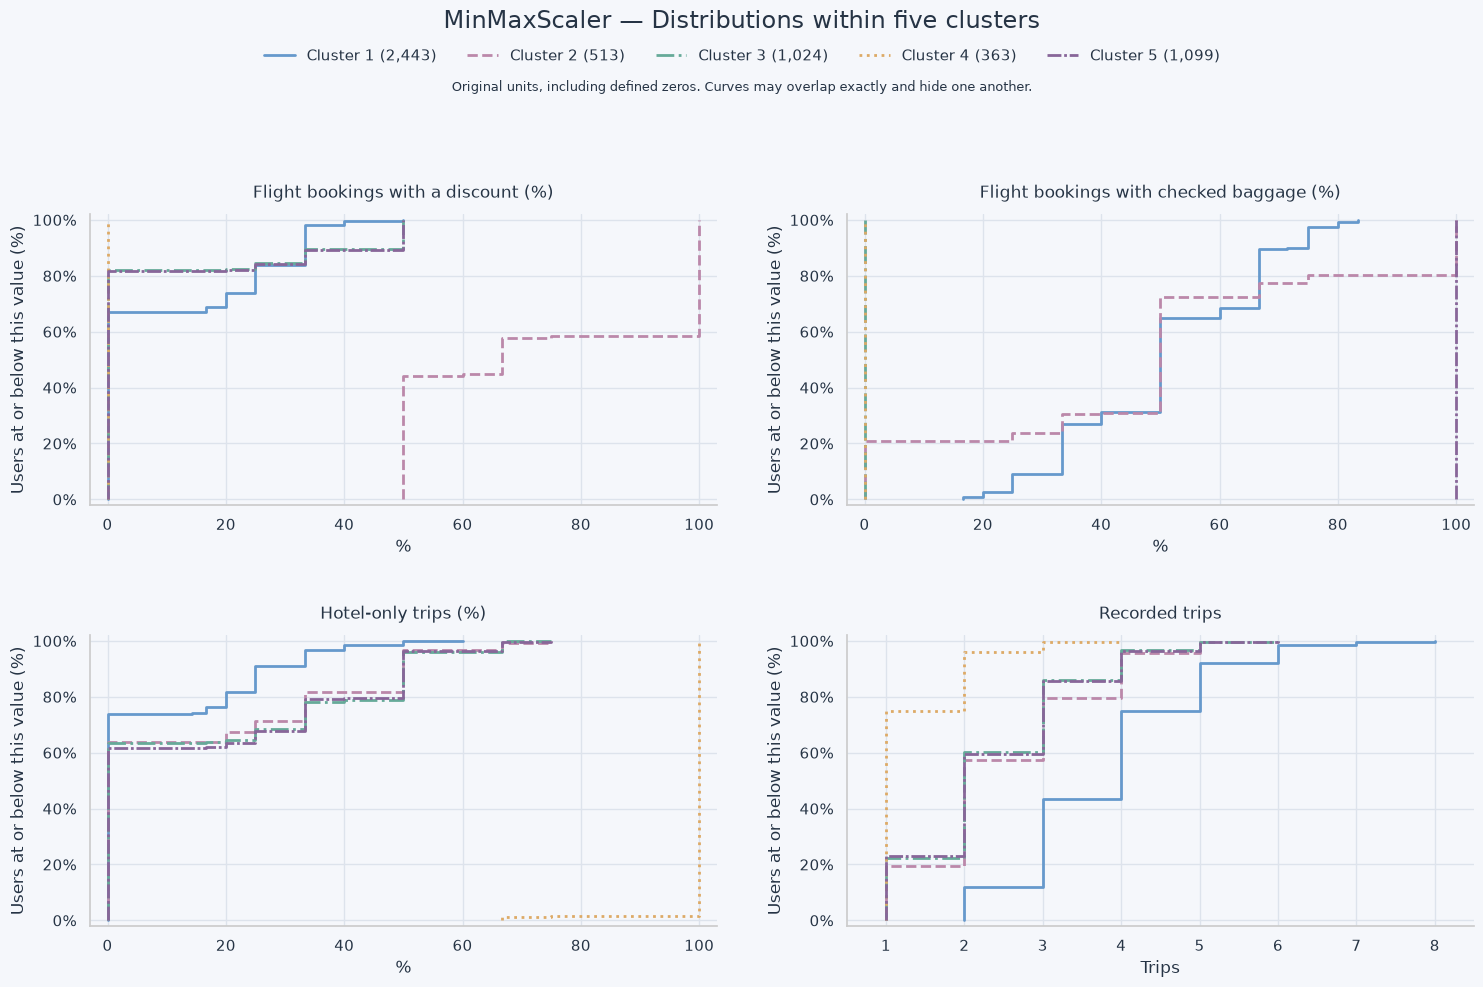

In [37]:
# inspect distinguishing features of the five MinMax clusters
# unterscheidende merkmale der fünf MinMax-cluster betrachten

minmax_visual_data = profile_display_data.copy()
minmax_visual_data["Cluster"] = minmax_five_clusters.reindex(
    minmax_visual_data.index
)

if minmax_visual_data["Cluster"].isna().any():
    raise ValueError("Cluster assignments missing.")

minmax_cluster_order = [1, 2, 3, 4, 5]

minmax_cluster_colors = {
    1: COLORS["blue"],
    2: COLORS["lavender"],
    3: COLORS["mint"],
    4: COLORS["orange"],
    5: COLORS["highlight"],
}

minmax_line_styles = {
    1: "-",
    2: "--",
    3: "-.",
    4: ":",
    5: (0, (5, 1, 1, 1)),
}

minmax_sizes = (
    minmax_visual_data["Cluster"]
    .value_counts()
    .reindex(minmax_cluster_order)
)

minmax_visual_features = [
    "flight_discount_booking_share_pct",
    "flight_with_baggage_share_pct",
    "hotel_only_trip_share_pct",
    "trip_count",
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(15, 10),
)

for ax, feature in zip(axes.flat, minmax_visual_features):
    for cluster in minmax_cluster_order:
        values = np.sort(
            minmax_visual_data.loc[
                minmax_visual_data["Cluster"].eq(cluster),
                feature,
            ].to_numpy(dtype=float)
        )

        distinct_values, counts = np.unique(
            values,
            return_counts=True,
        )
        cumulative_share = counts.cumsum() / len(values)

        plot_x = np.r_[distinct_values[0], distinct_values]
        plot_y = np.r_[0.0, cumulative_share]

        ax.step(
            plot_x,
            plot_y,
            where="post",
            color=minmax_cluster_colors[cluster],
            linestyle=minmax_line_styles[cluster],
            linewidth=2,
            label=f"Cluster {cluster} ({minmax_sizes.loc[cluster]:,})",
        )

    ax.set_title(
        fill(profile_display_labels[feature], width=46),
        pad=12,
    )
    ax.set_xlabel(feature_units[feature])
    ax.set_ylabel("Users at or below this value (%)")
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.set_ylim(-0.02, 1.02)

    if feature.endswith("_pct"):
        ax.set_xlim(-3, 103)
    else:
        ax.set_xlim(0.5, ml_work["trip_count"].max() + 0.5)
        ax.set_xticks(
            range(1, int(ml_work["trip_count"].max()) + 1)
        )

    ax.set_axisbelow(True)

handles, legend_labels = axes[0, 0].get_legend_handles_labels()

fig.suptitle(
    "MinMaxScaler — Distributions within five clusters",
    fontsize=17,
    y=0.995,
)

fig.legend(
    handles,
    legend_labels,
    loc="upper center",
    ncol=5,
    frameon=False,
    bbox_to_anchor=(0.5, 0.97),
)

fig.text(
    0.5,
    0.925,
    "Original units, including defined zeros. "
    "Curves may overlap exactly and hide one another.",
    ha="center",
    va="top",
    fontsize=9,
)

fig.tight_layout(
    rect=[0, 0.01, 1, 0.88],
    h_pad=3,
    w_pad=3,
)

plt.show()

#### Complementary, simpler views
#### Ergänzende, verständlichere Darstellungen

The ECDF curves provide detailed distribution comparisons.
However, five overlapping curves and percentages on both axes make
some comparisons difficult to read.

Keep these figures and add simpler views:
baggage and discount usage as “never / sometimes / always”,
booking-type shares and recorded trip counts.

Show users without a corresponding flight booking separately.
For discount usage, consider all recorded flight bookings.
For baggage usage, consider flight bookings without a recorded cancellation.

---

Die ECDF-Kurven ermöglichen detaillierte Verteilungsvergleiche.
Fünf überlagerte Kurven und Prozentwerte auf beiden Achsen erschweren
jedoch teilweise das Lesen.

Die Grafiken bleiben erhalten und werden durch einfachere Ansichten
ergänzt: Gepäck- und Rabattnutzung als „nie / manchmal / immer“,
Buchungsarten und Anzahl erfasster Reisen.

Nutzer ohne entsprechende Flugbuchung separat ausweisen.
Bei der Rabattnutzung zählen alle erfassten Flugbuchungen.
Bei der Gepäcknutzung zählen Flugbuchungen ohne verzeichnete Stornierung.

### 4.11 Explain the five clusters with simpler comparisons
### 4.11 Die fünf Cluster mit einfacheren Vergleichen erklären

The first two charts show user percentages within each cluster.
The booking-type chart shows average personal trip shares.
The heatmap shows the percentage of users with each recorded trip count.

Each cluster totals 100% in every chart.
These views describe the existing model without changing its assignments.

Die ersten beiden Grafiken zeigen Nutzeranteile innerhalb jedes Clusters.
Die Buchungsartengrafik zeigt durchschnittliche persönliche Reiseanteile.
Die Heatmap zeigt die Nutzeranteile mit der jeweiligen Anzahl erfasster Reisen.

Jedes Cluster ergibt in jeder Grafik 100%.
Die Ansichten beschreiben das vorhandene Modell, ohne Zuordnungen zu ändern.

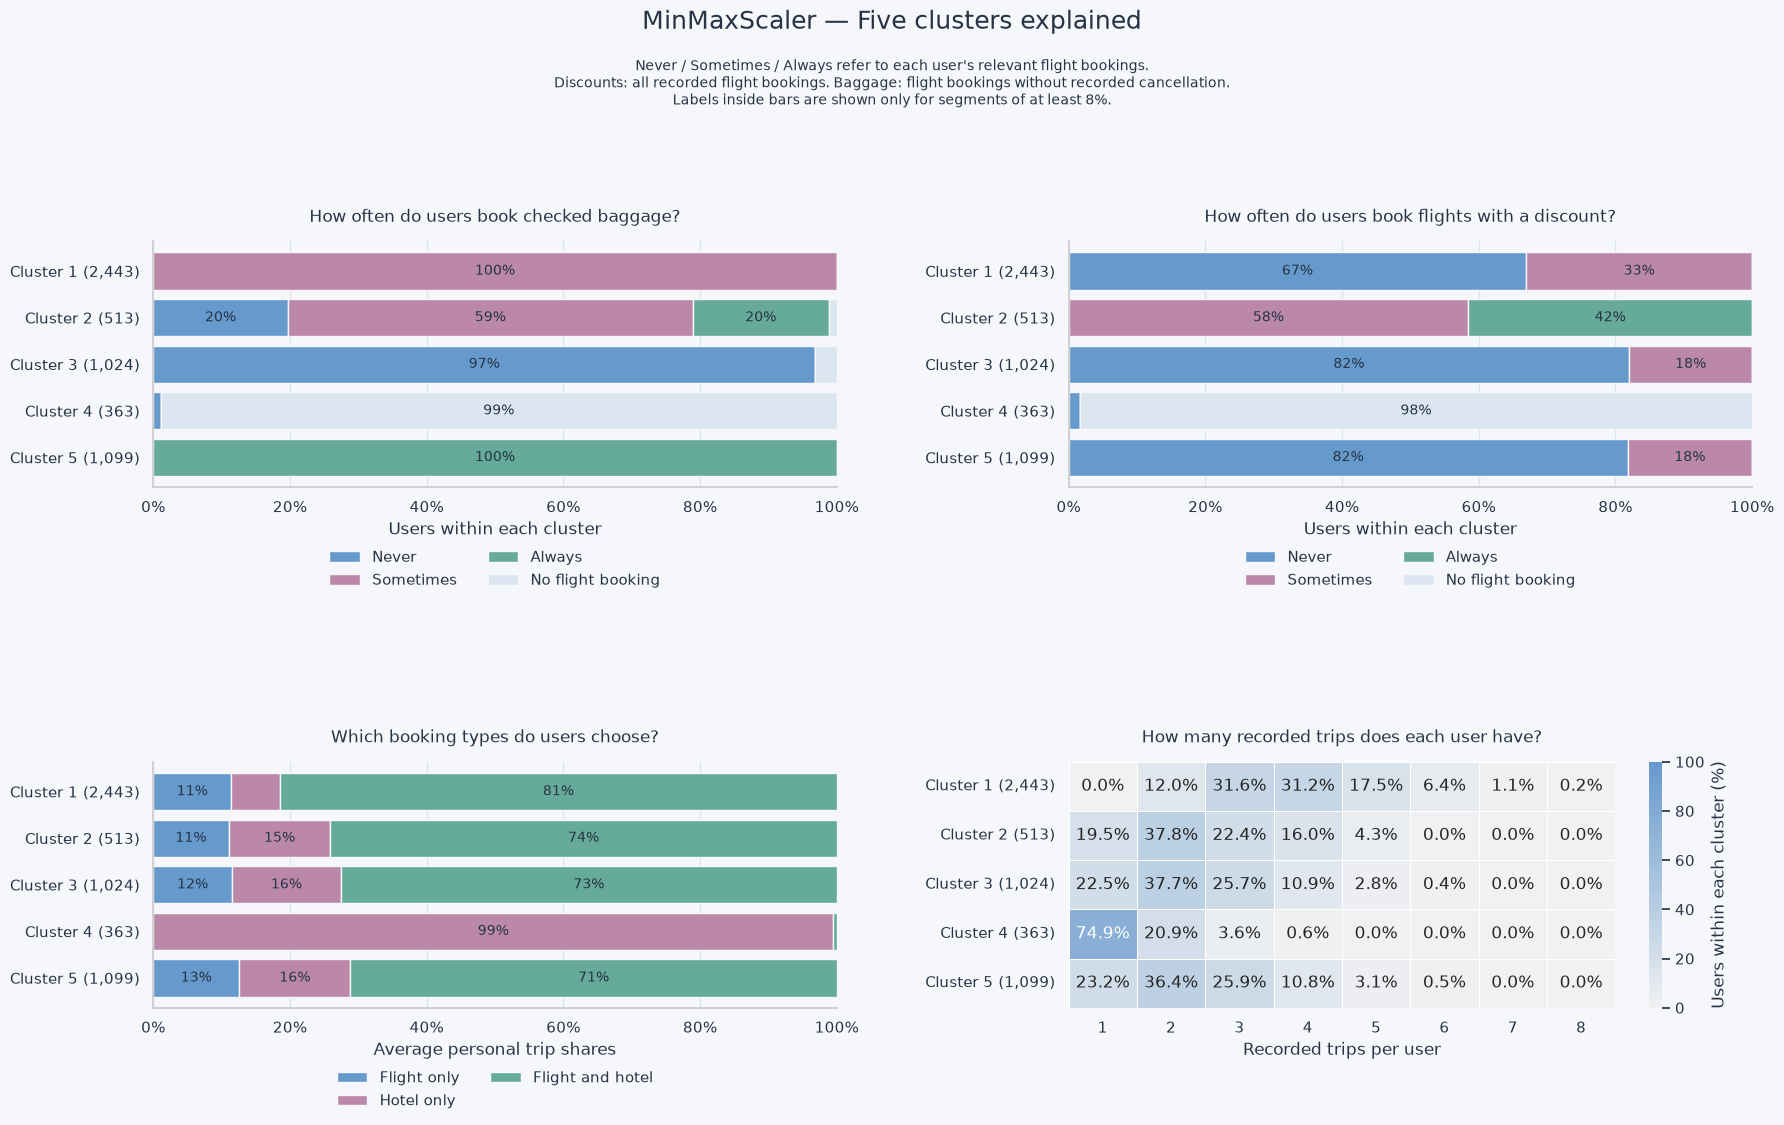

In [38]:
# explain the existing five clusters with simpler comparisons
# vorhandene fünf cluster mit einfacheren vergleichen erklären

simple_cluster_data = profile_display_data.copy()
simple_cluster_data["Cluster"] = minmax_five_clusters.reindex(
    simple_cluster_data.index
)

cluster_order_five = [1, 2, 3, 4, 5]

historical_counts = (
    user_features.set_index("user_id")
    .reindex(simple_cluster_data.index)
)

remaining_counts = profile_booking_counts.reindex(
    simple_cluster_data.index
)

if (
    simple_cluster_data["Cluster"].isna().any()
    or historical_counts["flight_trip_count"].isna().any()
    or remaining_counts["profile_flight_count"].isna().any()
):
    raise ValueError("Cluster or booking information missing.")

usage_order = [
    "Never",
    "Sometimes",
    "Always",
    "No flight booking",
]

usage_colors = {
    "Never": COLORS["blue"],
    "Sometimes": COLORS["lavender"],
    "Always": COLORS["mint"],
    "No flight booking": COLORS["table_header"],
}


def cluster_usage_percentages(feature, has_flight):
    """Separate absent bookings from observed usage."""
    rate = simple_cluster_data[feature]

    category = pd.Series(
        np.select(
            [
                ~has_flight,
                rate.eq(0),
                rate.eq(100),
            ],
            [
                "No flight booking",
                "Never",
                "Always",
            ],
            default="Sometimes",
        ),
        index=simple_cluster_data.index,
    )

    counts = pd.crosstab(
        simple_cluster_data["Cluster"],
        category,
    ).reindex(
        index=cluster_order_five,
        columns=usage_order,
        fill_value=0,
    )

    return counts.div(counts.sum(axis=1), axis=0) * 100


baggage_percentages = cluster_usage_percentages(
    "flight_with_baggage_share_pct",
    remaining_counts["profile_flight_count"].gt(0),
)

discount_percentages = cluster_usage_percentages(
    "flight_discount_booking_share_pct",
    historical_counts["flight_trip_count"].gt(0),
)

booking_type_features = {
    "flight_only_trip_share_pct": "Flight only",
    "hotel_only_trip_share_pct": "Hotel only",
    "flight_hotel_trip_share_pct": "Flight and hotel",
}

booking_type_percentages = (
    simple_cluster_data.groupby("Cluster")[
        list(booking_type_features)
    ]
    .mean()
    .rename(columns=booking_type_features)
    .reindex(cluster_order_five)
)

trip_counts = pd.crosstab(
    simple_cluster_data["Cluster"],
    simple_cluster_data["trip_count"].astype(int),
).reindex(
    index=cluster_order_five,
    columns=range(
        1,
        int(simple_cluster_data["trip_count"].max()) + 1,
    ),
    fill_value=0,
)

trip_count_percentages = (
    trip_counts.div(trip_counts.sum(axis=1), axis=0) * 100
)

for table in [
    baggage_percentages,
    discount_percentages,
    booking_type_percentages,
    trip_count_percentages,
]:
    if not np.allclose(table.sum(axis=1), 100):
        raise ValueError("Cluster percentages do not total 100.")

sizes = (
    simple_cluster_data["Cluster"]
    .value_counts()
    .reindex(cluster_order_five)
)

group_labels = [
    f"Cluster {cluster} ({sizes.loc[cluster]:,})"
    for cluster in cluster_order_five
]


def draw_percentage_bars(ax, table, colors, title, xlabel):
    positions = np.arange(len(table))
    left = np.zeros(len(table))

    for category in table.columns:
        widths = table[category].to_numpy()

        ax.barh(
            positions,
            widths,
            left=left,
            color=colors[category],
            edgecolor=COLORS["background"],
            label=category,
        )

        for position, start, width in zip(
            positions, left, widths
        ):
            if width >= 8:
                ax.text(
                    start + width / 2,
                    position,
                    f"{width:.0f}%",
                    ha="center",
                    va="center",
                    color=COLORS["text"],
                    fontsize=10,
                )

        left += widths

    ax.set_yticks(positions)
    ax.set_yticklabels(group_labels)
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.set_xlabel(xlabel)
    ax.set_title(title, pad=14)
    ax.set_axisbelow(True)
    ax.grid(axis="y", visible=False)

    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.20),
        ncol=2,
        frameon=False,
    )


fig, axes = plt.subplots(
    2,
    2,
    figsize=(18, 12),
)

draw_percentage_bars(
    axes[0, 0],
    baggage_percentages,
    usage_colors,
    "How often do users book checked baggage?",
    "Users within each cluster",
)

draw_percentage_bars(
    axes[0, 1],
    discount_percentages,
    usage_colors,
    "How often do users book flights with a discount?",
    "Users within each cluster",
)

draw_percentage_bars(
    axes[1, 0],
    booking_type_percentages,
    {
        "Flight only": COLORS["blue"],
        "Hotel only": COLORS["lavender"],
        "Flight and hotel": COLORS["mint"],
    },
    "Which booking types do users choose?",
    "Average personal trip shares",
)

heatmap_annotations = trip_count_percentages.map(
    lambda value: f"{value:.1f}%"
)

sns.heatmap(
    trip_count_percentages,
    annot=heatmap_annotations,
    fmt="",
    cmap=sns.light_palette(COLORS["blue"], as_cmap=True),
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={"label": "Users within each cluster (%)"},
    ax=axes[1, 1],
)

axes[1, 1].set_title(
    "How many recorded trips does each user have?",
    pad=14,
)
axes[1, 1].set_xlabel("Recorded trips per user")
axes[1, 1].set_ylabel("")
axes[1, 1].set_yticklabels(group_labels, rotation=0)

fig.suptitle(
    "MinMaxScaler — Five clusters explained",
    fontsize=18,
    y=0.995,
)

fig.text(
    0.5,
    0.955,
    "Never / Sometimes / Always refer to each user's relevant flight bookings.\n"
    "Discounts: all recorded flight bookings. "
    "Baggage: flight bookings without recorded cancellation.\n"
    "Labels inside bars are shown only for segments of at least 8%.",
    ha="center",
    va="top",
    fontsize=10,
)

fig.tight_layout(
    rect=[0, 0.03, 1, 0.88],
    h_pad=6,
    w_pad=4,
)

plt.show()

#### Five-cluster comparison — Findings
#### Vergleich der fünf Cluster — Ergebnis

The simpler views clarify the main differences:

- Cluster 1 contains users with flight bookings both with and without
  checked baggage and comparatively more recorded trips.
- Cluster 2 has a high share of flight bookings with discounts.
- Cluster 3 predominantly contains flight bookers without checked baggage.
- Cluster 4 predominantly contains hotel-only bookers.
- Cluster 5 contains users who book checked baggage with every
  relevant flight booking.

The baggage and discount charts count users by their personal booking
patterns. For example, 100% “Sometimes” means that all users in the group
have bookings both with and without the characteristic.

These descriptions refer to recorded bookings.
They do not yet establish which benefit should be recommended.

---

Die einfacheren Ansichten verdeutlichen die wichtigsten Unterschiede:

- Cluster 1 umfasst Nutzer mit Flugbuchungen sowohl mit als auch ohne
  aufgegebenes Gepäck und vergleichsweise mehr erfassten Reisen.
- Cluster 2 weist einen hohen Anteil rabattierter Flugbuchungen auf.
- Cluster 3 umfasst überwiegend Flugbucher ohne aufgegebenes Gepäck.
- Cluster 4 umfasst überwiegend reine Hotelbucher.
- Cluster 5 umfasst Nutzer, die bei jeder berücksichtigten Flugbuchung
  aufgegebenes Gepäck buchen.

Die Gepäck- und Rabattgrafiken zählen Nutzer nach ihrem persönlichen
Buchungsmuster. Beispielsweise bedeutet 100% „Sometimes“, dass alle
Nutzer der Gruppe Buchungen sowohl mit als auch ohne das Merkmal haben.

Die Beschreibungen beziehen sich auf erfasste Buchungen.
Eine Vorteilsempfehlung ist damit noch nicht festgelegt.

### 4.12 Inspect typical values in the five clusters
### 4.12 Typische Werte der fünf Cluster prüfen

Calculate medians of selected user features to complement the previously
shown means. This helps distinguish typical values from averages raised
by unusually large values.

Use original-unit values, including documented zero codings and estimates.
Percentage features remain personal booking percentages.

Die Mediane ausgewählter Nutzermerkmale als Ergänzung zu den bereits
gezeigten Durchschnitten berechnen. So unterscheiden wir typische Werte
von Durchschnitten, die durch ungewöhnlich große Werte angehoben werden.

Werte in ursprünglichen Einheiten einschließlich dokumentierter
Null-Codierungen und Schätzwerte verwenden.
Prozentmerkmale bleiben persönliche Buchungsanteile.

In [39]:
# inspect median user values within the existing MinMax clusters
# mediane der nutzerwerte in den vorhandenen MinMax-clustern prüfen

median_review_features = [
    "trip_count",
    "flight_discount_booking_share_pct",
    "flight_with_baggage_share_pct",
    "hotel_only_trip_share_pct",
    "avg_hotel_nights",
    "avg_flight_booking_lead_days",
    "avg_hotel_booking_lead_days",
    "avg_trip_booking_value_usd",
]

review_labels = minmax_five_clusters.reindex(
    profile_display_data.index
)

if review_labels.isna().any():
    raise ValueError("Cluster assignments missing.")

minmax_five_medians = (
    profile_display_data[median_review_features]
    .groupby(review_labels)
    .median()
    .T
)

minmax_five_medians.index = [
    profile_display_labels[feature]
    for feature in minmax_five_medians.index
]

review_sizes = review_labels.value_counts()

minmax_five_medians.columns = [
    f"Cluster {cluster} — {review_sizes.loc[cluster]:,} users"
    for cluster in minmax_five_medians.columns
]

minmax_median_table = (
    minmax_five_medians
    .rename_axis("Feature")
    .reset_index()
)

display(HTML(
    '<div style="overflow-x:auto;">'
    + style_overview(
        minmax_median_table,
        "MinMaxScaler — 5 clusters — Median user values",
        {
            column: "{:,.2f}"
            for column in minmax_median_table.columns
            if column != "Feature"
        },
    ).to_html()
    + "</div>"
))

print("Existing assignments used; no model refitted.")

Feature,"Cluster 1 — 2,443 users",Cluster 2 — 513 users,"Cluster 3 — 1,024 users",Cluster 4 — 363 users,"Cluster 5 — 1,099 users"
Recorded trips,4.00,2.00,2.00,1.00,2.00
Flight bookings with a discount (%),0.00,66.67,0.00,0.00,0.00
Flight bookings with checked baggage (%),50.00,50.00,0.00,0.00,100.00
Hotel-only trips (%),0.00,0.00,0.00,100.00,0.00
Average nights per hotel booking,3.50,3.50,3.63,7.00,3.67
Average days from booking to departure,8.00,8.00,8.00,0.00,8.00
Average days from booking to check-in,7.75,7.67,7.67,7.00,8.00
Average estimated booking value (USD),984.03,"1,025.64",964.16,"1,280.00",988.92


Existing assignments used; no model refitted.


#### K-Means — Interim conclusion
#### K-Means — Zwischenfazit

The MinMax five-cluster medians support the observed differences in
booking frequency, flight discount usage, baggage usage and hotel-only
bookings. Typical booking lead times differ little between its flight groups.

The StandardScaler three-cluster solution highlights a different perspective:
hotel-only bookings and users with longer flight booking lead times
and higher cancellation shares.

Both solutions are stable across the tested random seeds.
MinMax with five clusters remains the provisional main candidate;
StandardScaler with three clusters remains a comparison.
No final model or customer benefits have been selected.

Next, investigate DBSCAN, followed by PCA.

---

Die Mediane der MinMax-Fünferlösung bestätigen die Unterschiede bei
Buchungshäufigkeit, Flugrabatten, Gepäcknutzung und reinen Hotelbuchungen.
Die typischen Buchungsvorläufe unterscheiden sich zwischen ihren
Flugbuchergruppen dagegen wenig.

Die StandardScaler-Dreierlösung zeigt eine andere Perspektive:
reine Hotelbuchungen sowie Nutzer mit längerem Flugbuchungsvorlauf
und höheren Stornierungsanteilen.

Beide Lösungen sind gegenüber den getesteten Zufallsstarts stabil.
MinMax mit fünf Clustern bleibt der vorläufige Hauptkandidat;
StandardScaler mit drei Clustern bleibt als Vergleich erhalten.
Eine endgültige Modellauswahl oder Vorteilszuordnung ist noch nicht erfolgt.

Als Nächstes DBSCAN untersuchen, anschließend PCA.

## 5. DBSCAN
## 5. DBSCAN

Investigate density-based clustering using the same 5,442 users and
14 MinMax-scaled features. DBSCAN does not require a predefined cluster count.
Users labelled as noise remain in the dataset.

Dichtebasiertes Clustering mit denselben 5.442 Nutzern und
14 MinMax-skalierten Merkmalen untersuchen. DBSCAN benötigt keine
vorgegebene Clusterzahl. Als Noise markierte Nutzer bleiben im Datensatz.

### 5.1 Inspect neighbourhood distances
### 5.1 Nachbarschaftsabstände untersuchen

Start with min_samples=28: twice the number of features.
This is an exploratory choice, not a fixed requirement.

For each user, calculate the radius needed to include 28 users,
including the user themselves. Sort these distances and plot them
to identify candidate eps values. No DBSCAN model is fitted yet.

Mit min_samples=28 beginnen: dem Doppelten der Merkmalsanzahl.
Dies ist eine Ausgangsentscheidung, keine feste Vorgabe.

Für jeden Nutzer den Radius berechnen, der 28 Nutzer einschließlich
seiner selbst umfasst. Die Abstände sortieren und darstellen,
um mögliche eps-Werte auszuwählen. Noch kein DBSCAN-Modell berechnen.

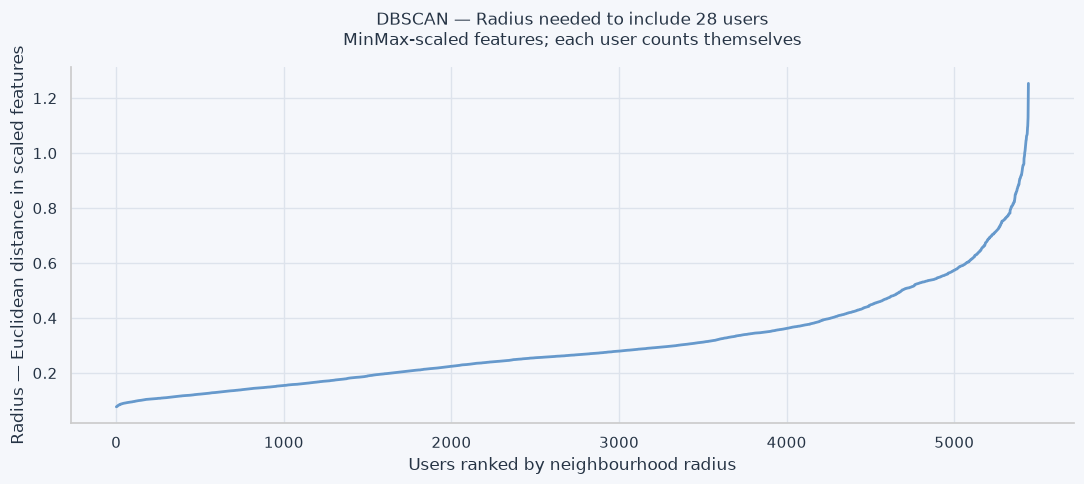

Metric,Distance
Minimum radius,0.0772
Median radius,0.2651
90th percentile,0.5455
95th percentile,0.6582
Maximum radius,1.2537


Users checked: 5,442
Features: 14
Initial min_samples: 28
No DBSCAN model fitted yet.


In [40]:
# inspect neighbour distances before choosing DBSCAN parameters
# nachbarabstände vor der wahl der DBSCAN-parameter untersuchen

from sklearn.neighbors import NearestNeighbors

dbscan_data = ml_minmax.copy()
dbscan_min_samples = 2 * dbscan_data.shape[1]  # 28

if not np.isfinite(dbscan_data.to_numpy()).all():
    raise ValueError("Missing or infinite input values found.")

neighbour_model = NearestNeighbors(
    n_neighbors=dbscan_min_samples,
    metric="euclidean",
)

neighbour_model.fit(dbscan_data)

# explicitly query the same data so each user counts as their own neighbour
neighbour_distances, _ = neighbour_model.kneighbors(
    dbscan_data
)

dbscan_radius_per_user = pd.Series(
    neighbour_distances[:, -1],
    index=dbscan_data.index,
    name="neighbourhood_radius",
)

sorted_radii = np.sort(
    dbscan_radius_per_user.to_numpy()
)

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    np.arange(1, len(sorted_radii) + 1),
    sorted_radii,
    color=COLORS["blue"],
    linewidth=2,
)

ax.set_title(
    "DBSCAN — Radius needed to include 28 users\n"
    "MinMax-scaled features; each user counts themselves",
    pad=16,
)

ax.set_xlabel("Users ranked by neighbourhood radius")
ax.set_ylabel("Radius — Euclidean distance in scaled features")
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

radius_summary = pd.DataFrame({
    "Metric": [
        "Minimum radius",
        "Median radius",
        "90th percentile",
        "95th percentile",
        "Maximum radius",
    ],
    "Distance": [
        dbscan_radius_per_user.min(),
        dbscan_radius_per_user.median(),
        dbscan_radius_per_user.quantile(0.90),
        dbscan_radius_per_user.quantile(0.95),
        dbscan_radius_per_user.max(),
    ],
})

display(style_overview(
    radius_summary,
    "DBSCAN — Neighbourhood distances",
    {"Distance": "{:.4f}"},
))

print("Users checked:", f"{len(dbscan_data):,}")
print("Features:", dbscan_data.shape[1])
print("Initial min_samples:", dbscan_min_samples)
print("No DBSCAN model fitted yet.")

#### Neighbourhood distances — Findings
#### Nachbarschaftsabstände — Ergebnis

Most users require a relatively small radius to include 28 users,
counting themselves. A smaller proportion requires substantially larger
radii. The curve becomes progressively steeper toward its upper end,
without identifying a single unambiguous eps value.

As an initial comparison, test eps values of 0.4, 0.5, 0.6, 0.7 and 0.8
while keeping min_samples=28.

Compare cluster counts, group sizes and the proportion of users labelled
as noise. Calculate silhouette only where at least two clusters exist,
excluding noise, and interpret it alongside the proportion of users assigned.

Large neighbourhood distances do not establish data errors.
A user who is not a core point may still join a cluster as a border point.

---

Die meisten Nutzer benötigen einen vergleichsweise kleinen Radius,
um einschließlich ihrer selbst 28 Nutzer zu umfassen. Ein kleinerer
Anteil benötigt deutlich größere Radien. Zum oberen Ende wird die
Kurve zunehmend steiler, ohne einen eindeutig besten eps-Wert zu zeigen.

Als ersten Vergleich eps-Werte von 0,4, 0,5, 0,6, 0,7 und 0,8 testen.
min_samples bleibt zunächst bei 28.

Clusteranzahl, Gruppengrößen und den als Noise markierten Nutzeranteil
vergleichen. Die Silhouette nur bei mindestens zwei Clustern und ohne
Noise berechnen; sie gemeinsam mit dem Anteil zugeordneter Nutzer bewerten.

Große Nachbarschaftsabstände belegen keine Datenfehler.
Ein Nutzer ohne Kernpunktstatus kann weiterhin als Randpunkt
einem Cluster zugeordnet werden.

### 5.2 Compare DBSCAN neighbourhood radii
### 5.2 DBSCAN-Nachbarschaftsradien vergleichen

Test eps values 0.4, 0.5, 0.6, 0.7 and 0.8 with min_samples=28
on the same MinMax-scaled features.

Record the cluster count, assigned users, noise percentage and group sizes.
Noise means unassigned under these settings, not an erroneous record.
No users are deleted.

Calculate silhouette only for assigned users and only when at least
two clusters exist. Noise is not treated as an additional cluster.
Because coverage varies, interpret silhouette together with the noise
percentage; do not directly equate it with the full-population K-Means score.

Die eps-Werte 0,4, 0,5, 0,6, 0,7 und 0,8 bei min_samples=28
auf denselben MinMax-skalierten Merkmalen testen.

Clusterzahl, zugeordnete Nutzer, Noise-Anteil und Gruppengrößen erfassen.
Noise bedeutet bei diesen Einstellungen nicht zugeordnet, nicht fehlerhaft.
Es werden keine Nutzer gelöscht.

Die Silhouette nur für zugeordnete Nutzer und nur bei mindestens
zwei Clustern berechnen. Noise wird nicht als zusätzlicher Cluster behandelt.
Da die Abdeckung variiert, die Silhouette zusammen mit dem Noise-Anteil
beurteilen. Sie ist nicht unmittelbar mit dem K-Means-Wert für alle
Nutzer gleichzusetzen.

In [41]:
# compare DBSCAN radii and explicitly display the results
# DBSCAN-radien vergleichen und ergebnisse ausdrücklich anzeigen

from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

eps_values = [0.4, 0.5, 0.6, 0.7, 0.8]

dbscan_models = {}
dbscan_labels = {}
dbscan_rows = []

for eps in eps_values:
    model = DBSCAN(
        eps=eps,
        min_samples=dbscan_min_samples,
        metric="euclidean",
    )

    labels = model.fit_predict(dbscan_data)

    # DBSCAN uses -1 for users not assigned to a cluster
    assigned = labels != -1
    assigned_labels = labels[assigned]

    group_sizes = pd.Series(assigned_labels).value_counts()
    cluster_count = len(group_sizes)

    noise_count = int((~assigned).sum())
    assigned_count = int(assigned.sum())

    # evaluate separation only among assigned users
    score = np.nan

    if 2 <= cluster_count < assigned_count:
        score = silhouette_score(
            dbscan_data.loc[assigned],
            assigned_labels,
            metric="euclidean",
        )

    key = (eps, dbscan_min_samples)

    dbscan_models[key] = model
    dbscan_labels[key] = pd.Series(
        labels,
        index=dbscan_data.index,
        name="cluster",
    )

    dbscan_rows.append({
        "eps": eps,
        "Clusters": cluster_count,
        "Assigned users": assigned_count,
        "Noise users": noise_count,
        "Noise share (%)": noise_count / len(dbscan_data) * 100,
        "Smallest cluster": (
            int(group_sizes.min()) if cluster_count else 0
        ),
        "Largest cluster": (
            int(group_sizes.max()) if cluster_count else 0
        ),
        "Silhouette — Assigned users only": score,
    })

dbscan_results = pd.DataFrame(dbscan_rows)

display(HTML(
    '<div style="overflow-x:auto;">'
    + style_overview(
        dbscan_results,
        "DBSCAN — Initial radius comparison",
        {
            "eps": "{:.1f}",
            "Clusters": "{:.0f}",
            "Assigned users": "{:,.0f}",
            "Noise users": "{:,.0f}",
            "Noise share (%)": "{:.1f}",
            "Smallest cluster": "{:,.0f}",
            "Largest cluster": "{:,.0f}",
            "Silhouette — Assigned users only": "{:.3f}",
        },
    ).to_html()
    + "</div>"
))

print("Models fitted:", len(dbscan_models))
print("min_samples:", dbscan_min_samples)
print("All users retained:", len(dbscan_data))
print("Noise users remain in the dataset.")

eps,Clusters,Assigned users,Noise users,Noise share (%),Smallest cluster,Largest cluster,Silhouette — Assigned users only
0.4,5,"4,701",741,13.6,28,"4,288",0.324
0.5,3,"5,054",388,7.1,29,"4,674",0.353
0.6,1,"5,308",134,2.5,"5,308","5,308",—
0.7,1,"5,386",56,1.0,"5,386","5,386",—
0.8,1,"5,429",13,0.2,"5,429","5,429",—


Models fitted: 5
min_samples: 28
All users retained: 5442
Noise users remain in the dataset.


#### Initial DBSCAN results
#### Erste DBSCAN-Ergebnisse

With min_samples=28, smaller radii produce one dominant cluster,
several small clusters and unassigned users. At eps=0.6 and above,
only one cluster remains.

The tested settings therefore provide limited support for differentiated
user segmentation. Silhouette scores exclude noise users and cannot
be compared directly with the K-Means scores calculated for all users.

Before concluding, test whether changing min_samples substantially
changes this pattern. This is a limited sensitivity check, not an
exhaustive parameter search.

---

Bei min_samples=28 entstehen mit kleineren Radien ein dominantes Cluster,
mehrere kleine Cluster und unzugeordnete Nutzer. Ab eps=0,6 bleibt
nur ein Cluster übrig.

Die getesteten Einstellungen helfen deshalb bislang wenig bei einer
differenzierten Nutzersegmentierung. Die Silhouette schließt Noise-Nutzer
aus und ist nicht direkt mit den K-Means-Werten über alle Nutzer vergleichbar.

Vor dem Fazit prüfen wir, ob andere min_samples-Werte dieses Muster
wesentlich verändern. Dies ist eine begrenzte Sensitivitätsprüfung,
keine vollständige Suche über alle möglichen Einstellungen.

### 5.3 Check sensitivity to min_samples
### 5.3 Einfluss von min_samples prüfen

Compare min_samples values of 14, 28 and 42 using the same five eps values.
These represent one, two and three times the number of features;
they are exploratory choices, not fixed requirements.

Reuse the existing results for 28 and fit ten additional models.
Assess cluster counts, group sizes and noise shares together.
Do not select parameters merely to reproduce five clusters.

Die min_samples-Werte 14, 28 und 42 bei denselben fünf eps-Werten vergleichen.
Sie entsprechen der einfachen, doppelten und dreifachen Merkmalsanzahl;
dies sind Ausgangsentscheidungen, keine festen Vorgaben.

Die Ergebnisse für 28 wiederverwenden und zehn zusätzliche Modelle berechnen.
Clusteranzahl, Gruppengrößen und Noise-Anteile gemeinsam beurteilen.
Parameter nicht allein danach auswählen, ob fünf Cluster entstehen.

In [42]:
# test two additional density requirements
# zwei zusätzliche dichteanforderungen testen

additional_dbscan_rows = []

for min_samples_value in [14, 42]:
    for eps in eps_values:
        model = DBSCAN(
            eps=eps,
            min_samples=min_samples_value,
            metric="euclidean",
        )

        labels = model.fit_predict(dbscan_data)

        assigned = labels != -1
        assigned_labels = labels[assigned]

        group_sizes = pd.Series(assigned_labels).value_counts()
        cluster_count = len(group_sizes)

        assigned_count = int(assigned.sum())
        noise_count = int((~assigned).sum())

        score = np.nan

        if 2 <= cluster_count < assigned_count:
            score = silhouette_score(
                dbscan_data.loc[assigned],
                assigned_labels,
                metric="euclidean",
            )

        key = (eps, min_samples_value)

        dbscan_models[key] = model
        dbscan_labels[key] = pd.Series(
            labels,
            index=dbscan_data.index,
            name="cluster",
        )

        additional_dbscan_rows.append({
            "min_samples": min_samples_value,
            "eps": eps,
            "Clusters": cluster_count,
            "Assigned users": assigned_count,
            "Noise users": noise_count,
            "Noise share (%)": noise_count / len(dbscan_data) * 100,
            "Smallest cluster": (
                int(group_sizes.min()) if cluster_count else 0
            ),
            "Largest cluster": (
                int(group_sizes.max()) if cluster_count else 0
            ),
            "Silhouette — Assigned users only": score,
        })

    print(f"min_samples={min_samples_value}: five radii checked.")

# retain the original five results and add the ten new results
initial_dbscan_results = dbscan_results.assign(
    min_samples=dbscan_min_samples
)

dbscan_sensitivity_results = (
    pd.concat(
        [
            initial_dbscan_results,
            pd.DataFrame(additional_dbscan_rows),
        ],
        ignore_index=True,
    )
    .sort_values(["min_samples", "eps"])
    .reset_index(drop=True)
)

display_columns = [
    "min_samples",
    "eps",
    "Clusters",
    "Assigned users",
    "Noise users",
    "Noise share (%)",
    "Smallest cluster",
    "Largest cluster",
    "Silhouette — Assigned users only",
]

display(HTML(
    '<div style="overflow-x:auto;">'
    + style_overview(
        dbscan_sensitivity_results[display_columns],
        "DBSCAN — Density and radius comparison",
        {
            "min_samples": "{:.0f}",
            "eps": "{:.1f}",
            "Clusters": "{:.0f}",
            "Assigned users": "{:,.0f}",
            "Noise users": "{:,.0f}",
            "Noise share (%)": "{:.1f}",
            "Smallest cluster": "{:,.0f}",
            "Largest cluster": "{:,.0f}",
            "Silhouette — Assigned users only": "{:.3f}",
        },
    ).to_html()
    + "</div>"
))

print("Parameter combinations compared:", len(dbscan_sensitivity_results))
print("All users remain in the dataset.")

min_samples=14: five radii checked.
min_samples=42: five radii checked.


min_samples,eps,Clusters,Assigned users,Noise users,Noise share (%),Smallest cluster,Largest cluster,Silhouette — Assigned users only
14,0.4,9,"4,929",513,9.4,16,"4,433",0.246
14,0.5,5,"5,195",247,4.5,25,"4,762",0.287
14,0.6,1,"5,351",91,1.7,"5,351","5,351",—
14,0.7,1,"5,414",28,0.5,"5,414","5,414",—
14,0.8,1,"5,432",10,0.2,"5,432","5,432",—
28,0.4,5,"4,701",741,13.6,28,"4,288",0.324
28,0.5,3,"5,054",388,7.1,29,"4,674",0.353
28,0.6,1,"5,308",134,2.5,"5,308","5,308",—
28,0.7,1,"5,386",56,1.0,"5,386","5,386",—
28,0.8,1,"5,429",13,0.2,"5,429","5,429",—


Parameter combinations compared: 15
All users remain in the dataset.


#### DBSCAN — Conclusion of the tested configurations
#### DBSCAN — Fazit der getesteten Einstellungen

Across 15 parameter combinations on the MinMax-scaled features,
the main pattern remains unchanged: one dominant cluster with smaller
groups and noise, or a single cluster at larger radii.

Higher silhouette scores in some configurations apply only to assigned
users and must be considered alongside noise proportions and group sizes.
They do not establish superiority over K-Means.

The tested DBSCAN configurations do not provide a more useful primary
segmentation for this project. Retain K-Means as the main candidate
and proceed to PCA.

This conclusion is limited to the tested MinMax configurations.
DBSCAN with StandardScaler has not been evaluated.

---

Bei 15 Parameterkombinationen auf den MinMax-skalierten Merkmalen
bleibt das Grundmuster bestehen: ein dominantes Cluster mit kleineren
Gruppen und Noise oder ein einzelnes Cluster bei größeren Radien.

Höhere Silhouette-Werte einzelner Einstellungen gelten nur für zugeordnete
Nutzer und müssen zusammen mit Noise-Anteilen und Gruppengrößen betrachtet
werden. Sie belegen keine Überlegenheit gegenüber K-Means.

Die getesteten DBSCAN-Einstellungen liefern für dieses Projekt keine
hilfreichere Hauptsegmentierung. K-Means bleibt Hauptkandidat;
als Nächstes folgt PCA.

Diese Schlussfolgerung gilt ausschließlich für die getesteten
MinMax-Einstellungen. DBSCAN mit StandardScaler wurde nicht untersucht.

## 6. Principal Component Analysis — PCA
## 6. Hauptkomponentenanalyse — PCA

PCA creates new axes as weighted combinations of the prepared features.
It does not assign clusters or simply select individual original columns.

Use the MinMax-scaled data to complement our provisional main model.
The existing tables and cluster assignments remain unchanged.

PCA erzeugt neue Achsen als gewichtete Kombinationen der vorbereiteten
Merkmale. Sie bildet keine Cluster und wählt nicht einfach einzelne
ursprüngliche Spalten aus.

Die MinMax-skalierten Daten als Ergänzung zu unserem vorläufigen
Hauptmodell verwenden. Bestehende Tabellen und Clusterzuordnungen
bleiben unverändert.

### 6.1 Inspect explained variance
### 6.1 Erklärte Varianz untersuchen

Initially calculate all 14 principal components.
Show the variance explained by each component and their cumulative total.

Report how many components retain at least 80%, 90% and 95% of the
variance. These are comparison thresholds, not automatic selection rules.
Explained variance describes statistical spread, not business relevance.

Zunächst alle 14 Hauptkomponenten berechnen.
Die erklärte Varianz je Komponente und ihre kumulierte Summe darstellen.

Anzeigen, wie viele Komponenten mindestens 80%, 90% und 95% der Varianz
abbilden. Dies sind Vergleichsschwellen, keine automatischen Auswahlregeln.
Erklärte Varianz beschreibt statistische Streuung, nicht geschäftliche Relevanz.

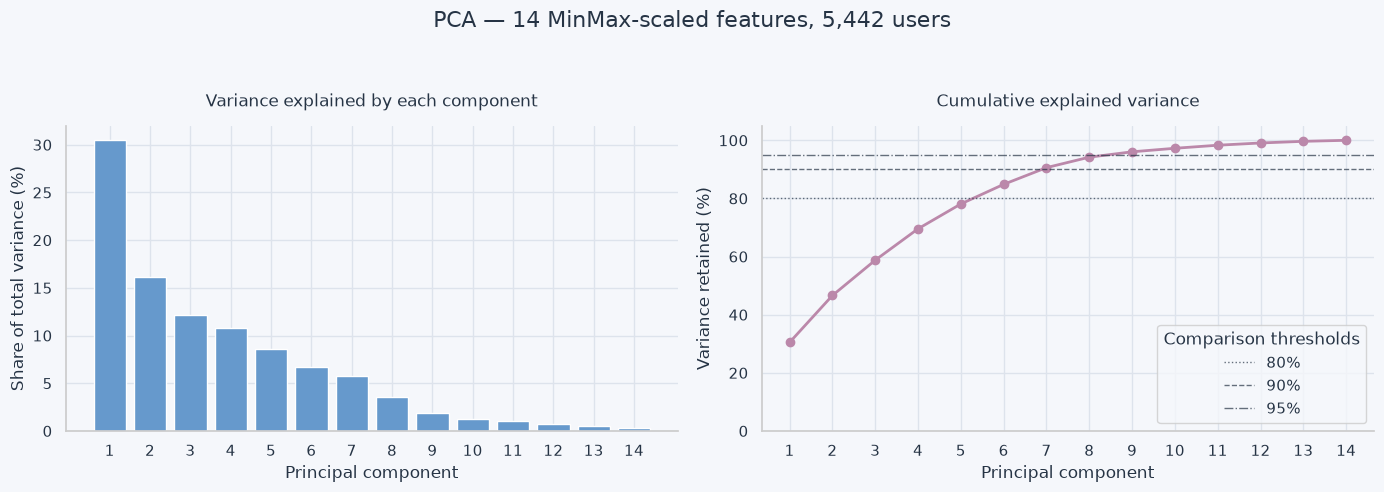

Target spread retained (%),Components needed,Actual spread retained (%)
80,6,84.85
90,7,90.60
95,9,96.05


Variance represented by PC1 and PC2: 46.61%
Existing cluster assignments remain unchanged.


In [43]:
# inspect PCA variance without changing the existing clustering
# PCA-varianz untersuchen, ohne bestehende cluster zu verändern

from sklearn.decomposition import PCA

pca_input = ml_minmax.copy()

pca_full = PCA(
    n_components=pca_input.shape[1],
    svd_solver="full",
    whiten=False,
)

pca_scores = pd.DataFrame(
    pca_full.fit_transform(pca_input),
    index=pca_input.index,
    columns=[
        f"PC{i}"
        for i in range(1, pca_input.shape[1] + 1)
    ],
)

if not np.isfinite(pca_scores.to_numpy()).all():
    raise ValueError("Invalid PCA values found.")

explained_share = pca_full.explained_variance_ratio_
cumulative_share = np.cumsum(explained_share)
component_numbers = np.arange(1, len(explained_share) + 1)

pca_variance_table = pd.DataFrame({
    "Component": component_numbers,
    "Explained variance (%)": explained_share * 100,
    "Cumulative variance (%)": cumulative_share * 100,
})

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
)

axes[0].bar(
    component_numbers,
    explained_share * 100,
    color=COLORS["blue"],
)

axes[0].set_title("Variance explained by each component", pad=14)
axes[0].set_ylabel("Share of total variance (%)")

axes[1].plot(
    component_numbers,
    cumulative_share * 100,
    marker="o",
    color=COLORS["lavender"],
    linewidth=2,
)

for threshold, linestyle in [
    (80, ":"),
    (90, "--"),
    (95, "-."),
]:
    axes[1].axhline(
        threshold,
        color=COLORS["text"],
        linestyle=linestyle,
        linewidth=1,
        alpha=0.7,
        label=f"{threshold}%",
    )

axes[1].set_title("Cumulative explained variance", pad=14)
axes[1].set_ylabel("Variance retained (%)")
axes[1].set_ylim(0, 105)
axes[1].legend(title="Comparison thresholds")

for ax in axes:
    ax.set_xlabel("Principal component")
    ax.set_xticks(component_numbers)
    ax.set_axisbelow(True)

fig.suptitle(
    "PCA — 14 MinMax-scaled features, 5,442 users",
    fontsize=16,
)

fig.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

threshold_rows = []

for threshold in [0.80, 0.90, 0.95]:
    required = int(
        np.searchsorted(cumulative_share, threshold) + 1
    )

    threshold_rows.append({
        "Target variance (%)": threshold * 100,
        "Components required": required,
        "Variance retained (%)": (
            cumulative_share[required - 1] * 100
        ),
    })

pca_threshold_display = pd.DataFrame(
    threshold_rows
).rename(columns={
    "Target variance (%)": "Target spread retained (%)",
    "Components required": "Components needed",
    "Variance retained (%)": "Actual spread retained (%)",
})

display(style_overview(
    pca_threshold_display,
    "PCA — How many components do we need?",
    {
        "Target spread retained (%)": "{:.0f}",
        "Components needed": "{:.0f}",
        "Actual spread retained (%)": "{:.2f}",
    },
))

print(
    "Variance represented by PC1 and PC2:",
    f"{cumulative_share[1] * 100:.2f}%",
)
print("Existing cluster assignments remain unchanged.")

#### Explained variance — Findings and comparison plan
#### Erklärte Varianz — Ergebnis und Vergleichsplan

Seven components retain 90.60% of the variance; nine retain 96.05%.
Both are reasonable comparison candidates: seven reduce the dimensions
more strongly, while nine preserve more of the measured variation.

Compare K-Means with five clusters using:
- the original 14 prepared features;
- the first seven PCA components;
- the first nine PCA components.

Keep users and K-Means settings unchanged.
Do not rescale or whiten the PCA components.
Retain the original features for interpreting the resulting groups.

More explained variance does not automatically mean better clustering.
PCA remains a comparison, not a mandatory replacement.

---

Sieben Komponenten bilden 90,60% der Varianz ab, neun Komponenten 96,05%.
Beide sind sinnvolle Vergleichskandidaten: Sieben reduzieren stärker,
neun erhalten mehr der gemessenen Unterschiede.

K-Means mit fünf Clustern auf folgenden Grundlagen vergleichen:
- den ursprünglichen 14 vorbereiteten Merkmalen;
- den ersten sieben PCA-Komponenten;
- den ersten neun PCA-Komponenten.

Nutzer und K-Means-Einstellungen unverändert lassen.
Die PCA-Komponenten nicht erneut skalieren oder durch Whitening umgewichten.
Die ursprünglichen Merkmale zur Interpretation der Gruppen behalten.

Mehr erklärte Varianz bedeutet nicht automatisch besseres Clustering.
PCA bleibt eine Vergleichsvariante, kein notwendiger Ersatz.

### 6.2 Compare clustering with and without PCA
### 6.2 Clustering mit und ohne PCA vergleichen

Compare group sizes, agreement with the original assignments and silhouette.

Calculate silhouette in two spaces:
- the input space used by the respective model;
- the same original 14-feature MinMax space for every solution.

The second calculation provides a common distance basis.
ARI measures agreement with the original grouping, not correctness.
A different grouping is not automatically worse.

Gruppengrößen, Übereinstimmung mit der ursprünglichen Zuordnung
und Silhouette vergleichen.

Die Silhouette in zwei Merkmalsräumen berechnen:
- im jeweiligen Eingaberaum des Modells;
- für jede Lösung im selben ursprünglichen MinMax-Raum mit 14 Merkmalen.

Die zweite Berechnung bietet eine gemeinsame Abstandsgrundlage.
ARI misst Übereinstimmung mit der ursprünglichen Gruppierung,
keine Richtigkeit. Eine andere Gruppierung ist nicht automatisch schlechter.

In [44]:
# compare the existing model with seven- and nine-component PCA models
# bestehendes modell mit sieben und neun PCA-komponenten vergleichen

if not pca_scores.index.equals(ml_minmax.index):
    raise ValueError("PCA and original user order differ.")

reference_key = ("MinMaxScaler", 5)
reference_model = kmeans_models[reference_key]
reference_labels = kmeans_labels[reference_key]

if not reference_labels.index.equals(ml_minmax.index):
    raise ValueError("Reference user order differs.")

# reuse the original model and its previously calculated silhouette
reference_score = float(
    kmeans_comparison.loc[
        kmeans_comparison["Scaling"].eq("MinMaxScaler")
        & kmeans_comparison["Clusters"].eq(5),
        "Silhouette",
    ].iloc[0]
)

reference_sizes = reference_labels.value_counts()

pca_comparison_rows = [{
    "Model input": "14 features — No PCA",
    "Variance retained (%)": 100.0,
    "ARI versus original grouping": 1.0,
    "Silhouette — Model input space": reference_score,
    "Silhouette — Common 14-feature space": reference_score,
    "Smallest group": int(reference_sizes.min()),
    "Largest group": int(reference_sizes.max()),
}]

pca_kmeans_models = {}
pca_kmeans_labels = {}

for component_count in [7, 9]:
    # the first components come from the full PCA already fitted
    reduced_data = pca_scores.iloc[:, :component_count].copy()

    # use exactly the same K-Means settings as the original model
    model = KMeans(**reference_model.get_params())
    labels = model.fit_predict(reduced_data)

    sizes = pd.Series(labels).value_counts()

    if len(sizes) != 5:
        raise ValueError("Expected five clusters.")

    if model.n_iter_ >= model.max_iter:
        raise ValueError("Iteration limit reached.")

    agreement = adjusted_rand_score(
        reference_labels.to_numpy(),
        labels,
    )

    model_space_score = silhouette_score(
        reduced_data,
        labels,
        metric="euclidean",
    )

    common_space_score = silhouette_score(
        ml_minmax,
        labels,
        metric="euclidean",
    )

    pca_kmeans_models[component_count] = model
    pca_kmeans_labels[component_count] = pd.Series(
        labels,
        index=ml_minmax.index,
        name="cluster",
    )

    pca_comparison_rows.append({
        "Model input": f"{component_count} PCA components",
        "Variance retained (%)": (
            pca_full.explained_variance_ratio_[
                :component_count
            ].sum() * 100
        ),
        "ARI versus original grouping": agreement,
        "Silhouette — Model input space": model_space_score,
        "Silhouette — Common 14-feature space": common_space_score,
        "Smallest group": int(sizes.min()),
        "Largest group": int(sizes.max()),
    })

    print(f"{component_count} PCA components: comparison completed.")

pca_clustering_comparison = pd.DataFrame(
    pca_comparison_rows
)

pca_comparison_display = pca_clustering_comparison.rename(
    columns={
        "Model input": "Version",
        "Variance retained (%)": "Spread retained (%)",
        "ARI versus original grouping":
            "Agreement with original groups (ARI)",
        "Silhouette — Model input space":
            "Silhouette — Model data",
        "Silhouette — Common 14-feature space":
            "Silhouette — Same 14 features",
        "Smallest group": "Smallest group — Users",
        "Largest group": "Largest group — Users",
    }
)

display(HTML(
    '<div style="overflow-x:auto;">'
    + style_overview(
        pca_comparison_display,
        "Does PCA improve our five-cluster solution?",
        {
            "Spread retained (%)": "{:.2f}",
            "Agreement with original groups (ARI)": "{:.4f}",
            "Silhouette — Model data": "{:.3f}",
            "Silhouette — Same 14 features": "{:.3f}",
            "Smallest group — Users": "{:,.0f}",
            "Largest group — Users": "{:,.0f}",
        },
    ).to_html()
    + "</div>"
))

print("All models use the same 5,442 users and five clusters.")
print("Original model and assignments remain unchanged.")

7 PCA components: comparison completed.
9 PCA components: comparison completed.


Version,Spread retained (%),Agreement with original groups (ARI),Silhouette — Model data,Silhouette — Same 14 features,Smallest group — Users,Largest group — Users
14 features — No PCA,100.00,1.0000,0.213,0.213,363,"2,443"
7 PCA components,90.60,0.9964,0.245,0.212,379,"2,443"
9 PCA components,96.05,0.9998,0.226,0.213,364,"2,443"


All models use the same 5,442 users and five clusters.
Original model and assignments remain unchanged.


#### PCA comparison — Conclusion
#### PCA-Vergleich — Fazit

Seven components retain 90.60% of the measured spread;
nine retain 96.05%.

Both variants produce almost the same groups as the original model.
Their silhouette scores increase in their reduced model spaces,
but show no improvement when evaluated using the same 14 features.

Keep the five-cluster MinMax K-Means solution without PCA.
For this dataset, reducing only 14 features provides no clear practical
advantage that justifies the additional processing step.

The comparison does not establish that PCA is generally unhelpful.
It shows no clear benefit for this specific clustering setup.

---

Sieben Komponenten erhalten 90,60% der gemessenen Streuung,
neun Komponenten 96,05%.

Beide Varianten ergeben nahezu dieselben Gruppen wie das ursprüngliche
Modell. Ihre Silhouette-Werte steigen im jeweiligen reduzierten
Merkmalsraum, verbessern sich aber nicht bei einer Bewertung anhand
derselben 14 Merkmale.

Die MinMax-K-Means-Lösung mit fünf Clustern ohne PCA beibehalten.
Bei nur 14 Merkmalen ergibt sich für unseren Datensatz kein klarer
praktischer Vorteil, der den zusätzlichen Verarbeitungsschritt rechtfertigt.

Dies bedeutet nicht, dass PCA grundsätzlich wenig hilfreich ist.
Für die hier geprüfte Gruppierung zeigt sich jedoch kein klarer Nutzen.

### 6.3 Visualise the existing clusters in two dimensions
### 6.3 Bestehende Cluster zweidimensional darstellen

Plot users on the first two PCA components and colour them by their
existing five-cluster MinMax K-Means assignments.

Each point represents one user. The axes combine the original prepared
features; they do not directly represent kilometres, days or dollars.

This is a projection, not a new clustering.
Only part of the total variation is visible, so apparent overlap or
separation cannot establish the quality of the full clustering.

Nutzer auf den ersten beiden PCA-Komponenten darstellen und anhand
ihrer bestehenden MinMax-K-Means-Zuordnung zu fünf Clustern einfärben.

Jeder Punkt steht für einen Nutzer. Die Achsen kombinieren die
vorbereiteten Merkmale; sie zeigen keine direkten Kilometer-, Tages-
oder Dollarwerte.

Dies ist eine Projektion, kein neues Clustering.
Nur ein Teil der gesamten Unterschiede ist sichtbar. Sichtbare
Überschneidungen oder Abgrenzungen belegen deshalb nicht allein
die Qualität der vollständigen Gruppierung.

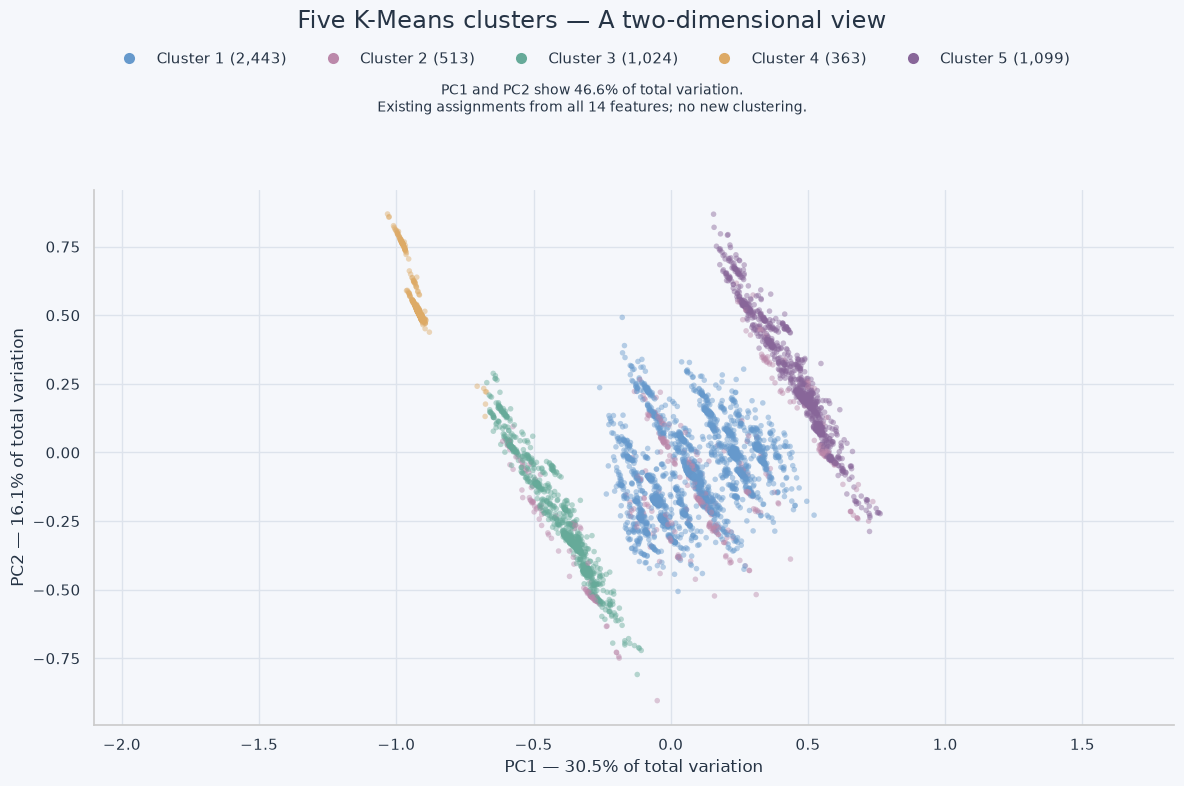

Users displayed: 5,442
Existing cluster assignments remain unchanged.


In [45]:
# project existing clusters onto two PCA axes
# bestehende cluster auf zwei PCA-achsen darstellen

from matplotlib.lines import Line2D

original_five_labels = kmeans_labels[
    ("MinMaxScaler", 5)
].reindex(pca_scores.index)

if original_five_labels.isna().any():
    raise ValueError("Cluster assignments missing.")

pca_plot_data = pca_scores[["PC1", "PC2"]].copy()
pca_plot_data["Cluster"] = (
    original_five_labels + 1
).astype(int)

pca_plot_colors = {
    1: COLORS["blue"],
    2: COLORS["lavender"],
    3: COLORS["mint"],
    4: COLORS["orange"],
    5: COLORS["highlight"],
}

pca_plot_sizes = (
    pca_plot_data["Cluster"]
    .value_counts()
    .sort_index()
)

# mix drawing order so one cluster is not always drawn on top
plot_order = np.random.default_rng(42).permutation(
    len(pca_plot_data)
)
points = pca_plot_data.iloc[plot_order]

pc1_share = pca_full.explained_variance_ratio_[0] * 100
pc2_share = pca_full.explained_variance_ratio_[1] * 100
visible_share = pc1_share + pc2_share

fig, ax = plt.subplots(figsize=(12, 8))

ax.scatter(
    points["PC1"],
    points["PC2"],
    c=points["Cluster"].map(pca_plot_colors).tolist(),
    s=16,
    alpha=0.45,
    edgecolors="none",
)

ax.set_xlabel(f"PC1 — {pc1_share:.1f}% of total variation")
ax.set_ylabel(f"PC2 — {pc2_share:.1f}% of total variation")
ax.set_aspect("equal", adjustable="datalim")
ax.set_axisbelow(True)

legend_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="",
        markerfacecolor=pca_plot_colors[cluster],
        markeredgecolor="none",
        markersize=8,
        label=(
            f"Cluster {cluster} "
            f"({pca_plot_sizes.loc[cluster]:,})"
        ),
    )
    for cluster in pca_plot_sizes.index
]

fig.suptitle(
    "Five K-Means clusters — A two-dimensional view",
    fontsize=17,
    y=0.98,
)

fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.945),
    ncol=5,
    frameon=False,
)

fig.text(
    0.5,
    0.89,
    f"PC1 and PC2 show {visible_share:.1f}% of total variation.\n"
    "Existing assignments from all 14 features; no new clustering.",
    ha="center",
    va="top",
    fontsize=10,
)

fig.tight_layout(rect=[0, 0, 1, 0.83])
plt.show()

print("Users displayed:", f"{len(pca_plot_data):,}")
print("Existing cluster assignments remain unchanged.")

In [46]:
# show the existing clusters in an interactive 3D PCA projection
# bestehende cluster in einer interaktiven 3D-PCA-projektion zeigen

import plotly.express as px

pca_3d_data = pca_scores[["PC1", "PC2", "PC3"]].copy()

labels_3d = kmeans_labels[
    ("MinMaxScaler", 5)
].reindex(pca_3d_data.index)

if labels_3d.isna().any():
    raise ValueError("Cluster assignments missing.")

pca_3d_data["Cluster"] = (
    (labels_3d + 1).astype(int).map(lambda x: f"Cluster {x}")
)

pca_3d_data["User"] = pca_3d_data.index.astype(str)

# mix drawing order while retaining all users
pca_3d_data = pca_3d_data.sample(
    frac=1,
    random_state=42,
)

component_shares = (
    pca_full.explained_variance_ratio_[:3] * 100
)
visible_share_3d = component_shares.sum()

fig = px.scatter_3d(
    pca_3d_data,
    x="PC1",
    y="PC2",
    z="PC3",
    color="Cluster",
    category_orders={
        "Cluster": [f"Cluster {i}" for i in range(1, 6)]
    },
    color_discrete_map={
        "Cluster 1": COLORS["blue"],
        "Cluster 2": COLORS["lavender"],
        "Cluster 3": COLORS["mint"],
        "Cluster 4": COLORS["orange"],
        "Cluster 5": COLORS["highlight"],
    },
    hover_name="User",
    labels={
        "PC1": f"PC1 — {component_shares[0]:.1f}%",
        "PC2": f"PC2 — {component_shares[1]:.1f}%",
        "PC3": f"PC3 — {component_shares[2]:.1f}%",
    },
)

fig.update_traces(
    marker={
        "size": 3,
        "opacity": 0.6,
    }
)

fig.update_layout(
    title={
        "text": (
            "Five K-Means clusters — Interactive 3D view"
            f"<br><sup>PC1–PC3 show {visible_share_3d:.1f}% "
            "of total variation. Existing cluster assignments.</sup>"
        ),
        "x": 0.5,
    },
    legend={
        "orientation": "h",
        "yanchor": "bottom",
        "y": 1.02,
        "xanchor": "center",
        "x": 0.5,
        "title_text": "",
    },
    scene={
        "aspectmode": "data",
    },
    height=750,
    margin={"l": 0, "r": 0, "b": 0, "t": 140},
    paper_bgcolor=COLORS["background"],
    font={"color": COLORS["text"]},
)

fig.show()

## 7. Final ML result
## 7. Abschließendes ML-Ergebnis

Select K-Means with MinMax scaling and five clusters as the project's
main ML solution.

The groups show interpretable differences in booking frequency,
flight discount usage, baggage usage and hotel-only bookings.
The assignments were stable across the five additional random seeds tested.

The StandardScaler three-cluster solution provides a complementary view.
The tested MinMax DBSCAN configurations did not provide a more useful
primary segmentation. PCA with seven or nine components produced almost
the same assignments without improving silhouette on the common
14-feature basis.

These findings support the selected solution for this project;
they do not prove a universally optimal segmentation.

Save cluster identifiers without assigning customer benefits yet.
Users excluded from ML remain available for the subsequent domain analysis.

---

K-Means mit MinMax-Skalierung und fünf Clustern als Hauptlösung
des ML-Teils auswählen.

Die Gruppen zeigen verständliche Unterschiede bei Buchungshäufigkeit,
Flugrabatten, Gepäcknutzung und reinen Hotelbuchungen.
Die Zuordnungen waren gegenüber den fünf zusätzlich getesteten
Zufallsstartwerten stabil.

Die StandardScaler-Dreierlösung liefert eine ergänzende Perspektive.
Die getesteten MinMax-DBSCAN-Einstellungen ergaben keine hilfreichere
Hauptsegmentierung. PCA mit sieben beziehungsweise neun Komponenten
lieferte nahezu dieselben Zuordnungen, ohne die Silhouette auf der
gemeinsamen Grundlage mit 14 Merkmalen zu verbessern.

Diese Ergebnisse begründen unsere Auswahl für dieses Projekt;
sie beweisen keine allgemein optimale Segmentierung.

Clusterkennungen speichern, ohne bereits Kundenvorteile zuzuweisen.
Die vom ML ausgeschlossenen Nutzer bleiben für die anschließende
fachliche Analyse erhalten.

### 7.1 Validate the final assignments
### 7.1 Abschließende Zuordnungen prüfen

Verify that every intended ML user has exactly one cluster assignment.
Check that all five clusters are present and all prepared feature values
remain numeric and finite. Do not refit the selected model.

Prüfen, dass jeder vorgesehene ML-Nutzer genau eine Clusterzuordnung hat.
Alle fünf Cluster sowie numerische, endliche Werte der vorbereiteten
Merkmale bestätigen. Das ausgewählte Modell nicht erneut berechnen.

In [47]:
# retain and validate the selected existing model
# ausgewähltes vorhandenes modell übernehmen und prüfen

final_ml_model = kmeans_models[("MinMaxScaler", 5)]
final_ml_scaler = minmax_scaler

selected_labels = kmeans_labels[
    ("MinMaxScaler", 5)
].reindex(ml_work.index)

if selected_labels.isna().any():
    raise ValueError("Some ML users have no cluster assignment.")

if not ml_work.index.is_unique:
    raise ValueError("Duplicate ML user IDs.")

if set(ml_work.index) != set(revised_ml_ids):
    raise ValueError("Unexpected ML population.")

if (
    len(ml_work) != 5442
    or ml_work.shape[1] != 14
    or not np.isfinite(
        ml_work.to_numpy(dtype=float)
    ).all()
):
    raise ValueError("Unexpected or incomplete ML feature table.")

# use cluster identifiers 1–5 in the exported assignment table
final_ml_assignments = pd.DataFrame({
    "user_id": ml_work.index.to_numpy(),
    "ml_cluster": selected_labels.to_numpy().astype(int) + 1,
})

if not final_ml_assignments["user_id"].is_unique:
    raise ValueError("Duplicate users in the assignment table.")

if set(final_ml_assignments["ml_cluster"]) != set(range(1, 6)):
    raise ValueError("Expected cluster identifiers 1–5.")

# verify assignments against the selected fitted model
predicted_labels = final_ml_model.predict(
    ml_minmax.loc[ml_work.index]
)

if not np.array_equal(
    predicted_labels,
    selected_labels.to_numpy(),
):
    raise ValueError("Assignments differ from the selected model.")

# retain original-unit model features, including agreed estimates
final_ml_feature_values = ml_work.copy()
final_ml_feature_values.index.name = "user_id"
final_ml_feature_values = final_ml_feature_values.reset_index()

final_cluster_sizes = (
    final_ml_assignments["ml_cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .reset_index(name="Users")
)

final_cluster_sizes["Share of ML users (%)"] = (
    final_cluster_sizes["Users"]
    / len(final_ml_assignments)
    * 100
)

display(style_overview(
    final_cluster_sizes,
    "Final ML solution — Five clusters",
    {
        "Cluster": "{:.0f}",
        "Users": "{:,.0f}",
        "Share of ML users (%)": "{:.1f}",
    },
))

outside_ml = set(user_features["user_id"]) - set(
    final_ml_assignments["user_id"]
)

if len(outside_ml) != 556:
    raise ValueError("Unexpected number of users outside ML.")

print("ML users with exactly one assignment:", len(final_ml_assignments))
print("Prepared ML features:", len(final_ml_feature_values.columns) - 1)
print("Users retained outside ML for domain analysis:", len(outside_ml))
print("No customer benefits assigned.")
print("Final ML validation passed.")

Cluster,Users,Share of ML users (%)
1,"2,443",44.9
2,513,9.4
3,"1,024",18.8
4,363,6.7
5,"1,099",20.2


ML users with exactly one assignment: 5442
Prepared ML features: 14
Users retained outside ML for domain analysis: 556
No customer benefits assigned.
Final ML validation passed.


### 7.2 Save the ML results
### 7.2 ML-Ergebnisse speichern

Save two separate tables:
- user IDs and final cluster assignments;
- the 14 prepared ML features in original units, including the documented
  zero codings and estimates.

The 556 users outside ML remain in the existing project data and will
be addressed in the domain analysis. No customer benefits are assigned yet.

Read both files back and verify that their contents match the tables.

Zwei getrennte Tabellen speichern:
- Nutzer-IDs und endgültige Clusterzuordnungen;
- die 14 vorbereiteten ML-Merkmale in ursprünglichen Einheiten,
  einschließlich dokumentierter Null-Codierungen und Schätzwerte.

Die 556 Nutzer außerhalb des ML bleiben in den vorhandenen Projektdaten
erhalten und werden in der fachlichen Analyse behandelt.
Noch keine Kundenvorteile zuweisen.

Beide Dateien erneut einlesen und ihre Inhalte mit den Tabellen vergleichen.

In [48]:
# save assignments and prepared features separately
# zuordnungen und vorbereitete merkmale getrennt speichern

cluster_output_path = processed_path / "ml_user_clusters.csv"
feature_output_path = processed_path / "ml_features_prepared.csv"

clusters_to_save = (
    final_ml_assignments
    .sort_values("user_id")
    .reset_index(drop=True)
)

features_to_save = (
    final_ml_feature_values
    .sort_values("user_id")
    .reset_index(drop=True)
)

clusters_to_save.to_csv(
    cluster_output_path,
    index=False,
)

features_to_save.to_csv(
    feature_output_path,
    index=False,
)

# read back and verify the saved contents
saved_clusters = pd.read_csv(cluster_output_path)
saved_features = pd.read_csv(feature_output_path)

pd.testing.assert_frame_equal(
    clusters_to_save,
    saved_clusters,
    check_dtype=False,
)

pd.testing.assert_frame_equal(
    features_to_save,
    saved_features,
    check_dtype=False,
    check_exact=False,
    rtol=1e-10,
    atol=1e-12,
)

saved_overview = pd.DataFrame({
    "File": [
        cluster_output_path.name,
        feature_output_path.name,
    ],
    "Users": [
        len(saved_clusters),
        len(saved_features),
    ],
    "Columns": [
        saved_clusters.shape[1],
        saved_features.shape[1],
    ],
})

display(style_overview(
    saved_overview,
    "ML results — Saved and verified",
    {
        "Users": "{:,.0f}",
        "Columns": "{:.0f}",
    },
))

print("ML results saved and verified.")
print("Customer benefit recommendations remain open.")

File,Users,Columns
ml_user_clusters.csv,"5,442",2
ml_features_prepared.csv,"5,442",15


ML results saved and verified.
Customer benefit recommendations remain open.


In [49]:
# preview both saved ML tables
# vorschau beider gespeicherten ML-tabellen

print("Cluster assignments — First 5 users")
display(saved_clusters.head(5))

print("Prepared ML features — First 5 users")
with pd.option_context("display.max_columns", None):
    display(saved_features.head(5))

Cluster assignments — First 5 users


,user_id,ml_cluster
0,23557,4
1,94883,1
2,101486,3
3,101961,1
4,118043,5


Prepared ML features — First 5 users


,user_id,trip_count,cancelled_trip_share_pct,flight_only_trip_share_pct,hotel_only_trip_share_pct,flight_discount_booking_share_pct,hotel_discount_booking_share_pct,flight_with_baggage_share_pct,avg_hotel_nights,avg_travel_days,avg_seats_per_flight_booking,avg_flight_distance_km,avg_flight_booking_lead_days,avg_hotel_booking_lead_days,avg_trip_booking_value_usd
0,23557,2.0,0.0,0.0,100.0,0.0,50.0,0.0,10.0,0.000000,0.0,0.000000,0.000000,13.00,1901.000
1,94883,2.0,0.0,0.0,0.0,0.0,0.0,50.0,1.0,1.500000,1.5,1448.099369,7.500000,7.50,547.045
2,101486,2.0,0.0,0.0,50.0,0.0,0.0,0.0,4.5,4.000000,1.0,965.340568,9.000000,8.00,1320.955
3,101961,5.0,0.0,0.0,0.0,20.0,0.0,40.0,4.4,4.800000,1.0,1320.983714,6.600000,6.60,808.132
4,118043,5.0,0.0,20.0,40.0,0.0,50.0,100.0,6.0,4.666667,2.0,2447.974284,9.666667,8.25,1795.458
